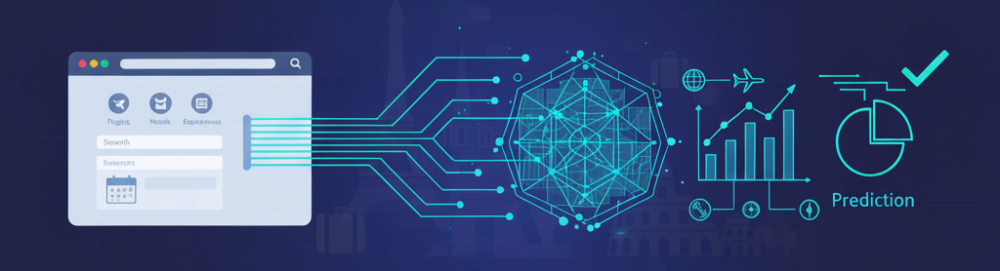

# **Actividad Integradora Grupo 13**

**Base de Datos elegida: Interacciones en página web de turismo**

**Integrantes:**

1.   Achával, Pastor Ignacio.
2.   Beck, Liz Ailén.
1.   Luna, Ana Clara.
2.   Martinez, Lucia.
1.   Rinaldi, Juan Sebastian.








# Importación de Librerias y Data Base.


In [ ]:
# ==============================================
# 📦 Tratamiento de datos


import numpy as np
import pandas as pd
import sys
!{sys.executable} -m pip install ydata_profiling
from ydata_profiling import ProfileReport

# ==============================================
# 📊 Gráficos

import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
import graphviz

# Estilos de gráficos
sns.set(style="white")   # estilo limpio
style.use('ggplot')      # estilo ggplot

# ==============================================
# ⚙️ Preprocesado y modelado


from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV,
    StratifiedKFold, cross_val_score
)
from sklearn.preprocessing import (
    StandardScaler, PolynomialFeatures, LabelEncoder, OrdinalEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA

# Modelos
from sklearn import ensemble, tree                          # Se agrega la carga de "tree" acá
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    r2_score, mean_squared_error, classification_report,
    confusion_matrix, roc_auc_score, roc_curve, make_scorer
)

# Otros utilitarios
from sklearn.datasets import make_classification
from sklearn.inspection import DecisionBoundaryDisplay
from scipy.stats import uniform

# Modelos avanzados
import xgboost as xgb
from lightgbm import LGBMClassifier

# ==============================================
# 📈 Estadística y modelos avanzados (statsmodels)


import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.weightstats import ttest_ind
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats import api as sms
from scipy.stats import chi2_contingency

# ==============================================
# 📂 Otros


from pathlib import Path
from google.colab import drive
import requests
from io import StringIO

# ==============================================
# ⚠️ Configuración adicional


import warnings
warnings.filterwarnings("ignore")

# Montar Google Drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 399.3/399.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.8 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3


Mounted at /content/drive


In [ ]:
url='https://drive.google.com/file/d/1ZdGW0m3P9BSXj5MhtjbuhbWw35jmBm97/view?usp=drive_link'

file_id = url.split('/')[-2]
dwn_url='https://drive.google.com/uc?export=download&id=' + file_id
print(dwn_url)
url = requests.get(dwn_url).text
csv_raw = StringIO(url)
df = pd.read_csv(csv_raw)
df = df.iloc[:,:]
df.head(5)

https://drive.google.com/uc?export=download&id=1ZdGW0m3P9BSXj5MhtjbuhbWw35jmBm97


,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
0,1000001,Yes,307.0,iOS and Android,38570.0,1,2,Financial,94.0,5993,8,Yes,11,No,1,0.0,8.0
1,1000002,No,367.0,iOS,9765.0,1,1,Financial,61.0,5130,1,No,23,Yes,4,1.0,10.0
2,1000003,Yes,277.0,iOS and Android,48055.0,1,2,Other,92.0,2090,6,Yes,15,No,2,0.0,7.0
3,1000004,No,247.0,iOS,48720.0,1,4,Financial,56.0,2909,1,Yes,11,No,3,0.0,8.0
4,1000005,No,202.0,iOS and Android,20685.0,1,1,Medical,40.0,3468,9,No,12,No,4,1.0,6.0


# **Objetivo principal**

El objetivo principal consiste en predecir si los usuarios adquirirán un boleto en el próximo mes.
Esta predicción permite anticipar el comportamiento de los clientes, optimizar estrategias comerciales, planificar recursos y diseñar acciones de marketing más efectivas. Al identificar de manera temprana a los usuarios con mayor probabilidad de compra, el modelo contribuye a una toma de decisiones más informada y al aumento del valor estratégico de los datos disponibles.

# **Checkpoint 1**

## Primer acercamiento a la Base de Datos.

Este conjunto de datos comprende información detallada sobre el Compromiso Digital en Turismo.

***Identificadores y Comportamiento del Usuario:***

**UserID**: ID único del usuario.

**preferred_device**: Dispositivo preferido para el inicio de sesión del usuario.

**working_flag**: Si el cliente está trabajando o no.

**Adult_flag**: Si el cliente es un adulto o no.



***Métricas de Compromiso:***

**Yearly_avg_view_on_travel_page**: Promedio anual de vistas en páginas relacionadas con viajes.

**Yearly_avg_comment_on_travel_page**: Promedio anual de comentarios en páginas relacionadas con viajes.

**monthly_avg_comment_on_company_page**: Promedio mensual de comentarios en la página de la empresa.

**total_likes_on_outstation_checkin_given**: Total de "me gusta" dados en check-ins fuera de la estación en el último año.

**total_likes_on_outofstation_checkin_received**: Total de "me gusta" recibidos en check-ins fuera de la estación.



***Comportamiento de Viaje:***

**Taken_product**: Comprar un boleto en el próximo mes (variable objetivo).

**yearly_avg_Outstation_checkins**: Promedio de check-ins fuera de la estación realizados por el usuario.

**week_since_last_outstation_checkin**: Semanas desde el último check-in fuera de la estación.

**travelling_network_rating**: Calificación de amigos que también viajan (1 es alta, 4 es baja).

**preferred_location_type**: Tipo de ubicación de viaje preferida.

**member_in_family**: Total de relaciones mencionadas por el usuario.

In [ ]:
df.describe()

,UserID,Yearly_avg_view_on_travel_page,total_likes_on_outstation_checkin_given,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,montly_avg_comment_on_company_page,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
count,1.176000e+04,11179.000000,11379.000000,11554.000000,11760.000000,11760.000000,11760.000000,11760.000000,11759.000000,11759.000000
mean,1.005880e+06,280.830844,28170.481765,74.790029,6531.699065,3.203571,28.660884,2.712755,0.793945,13.817757
std,3.394964e+03,68.182958,14385.032134,24.026650,4706.613785,2.616365,48.660793,1.082909,0.851828,9.070974
min,1.000001e+06,35.000000,3570.000000,3.000000,1009.000000,0.000000,4.000000,1.000000,0.000000,0.000000
25%,1.002941e+06,232.000000,16380.000000,57.000000,2940.750000,1.000000,17.000000,2.000000,0.000000,8.000000
50%,1.005880e+06,271.000000,28076.000000,75.000000,4948.000000,3.000000,22.000000,3.000000,1.000000,12.000000
75%,1.008820e+06,324.000000,40525.000000,92.000000,8393.250000,5.000000,27.000000,4.000000,1.000000,18.000000
max,1.011760e+06,464.000000,252430.000000,815.000000,20065.000000,11.000000,500.000000,10.000000,3.000000,270.000000


In [ ]:
# access metadata
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11760 entries, 0 to 11759
Data columns (total 17 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   UserID                                        11760 non-null  int64  
 1   Taken_product                                 11760 non-null  object 
 2   Yearly_avg_view_on_travel_page                11179 non-null  float64
 3   preferred_device                              11707 non-null  object 
 4   total_likes_on_outstation_checkin_given       11379 non-null  float64
 5   yearly_avg_Outstation_checkins                11685 non-null  object 
 6   member_in_family                              11760 non-null  object 
 7   preferred_location_type                       11729 non-null  object 
 8   Yearly_avg_comment_on_travel_page             11554 non-null  float64
 9   total_likes_on_outofstation_checkin_received  11760 non-null 

¿Qué tipo de base es?

In [ ]:
type(df)

pandas.core.frame.DataFrame

¿Qué tipo de datos hay presente en cada columna?

In [ ]:
df.dtypes

,0
UserID,int64
Taken_product,object
Yearly_avg_view_on_travel_page,float64
preferred_device,object
total_likes_on_outstation_checkin_given,float64
yearly_avg_Outstation_checkins,object
member_in_family,object
preferred_location_type,object
Yearly_avg_comment_on_travel_page,float64
total_likes_on_outofstation_checkin_received,int64


Cantidad de filas y columnas

In [ ]:
df.shape

(11760, 17)

In [ ]:
print(df.index)
print(df.columns)

RangeIndex(start=0, stop=11760, step=1)
Index(['UserID', 'Taken_product', 'Yearly_avg_view_on_travel_page',
       'preferred_device', 'total_likes_on_outstation_checkin_given',
       'yearly_avg_Outstation_checkins', 'member_in_family',
       'preferred_location_type', 'Yearly_avg_comment_on_travel_page',
       'total_likes_on_outofstation_checkin_received',
       'week_since_last_outstation_checkin', 'following_company_page',
       'montly_avg_comment_on_company_page', 'working_flag',
       'travelling_network_rating', 'Adult_flag',
       'Daily_Avg_mins_spend_on_traveling_page'],
      dtype='object')


### Análisis de la columna User ID

Se resuelve las siguientes incógnitas:

*   ¿Son valores únicos?
*   ¿Son valores únicos para cada registro?
*   ¿Hay valores nulos?


In [ ]:
df['UserID'].dtype

dtype('int64')

Es un ID con integer, es decir, valores numéricos enteros

In [ ]:
duplicados_UserID = [df['UserID'].duplicated()]
print(duplicados_UserID)

[0        False
1        False
2        False
3        False
4        False
         ...  
11755    False
11756    False
11757    False
11758    False
11759    False
Name: UserID, Length: 11760, dtype: bool]


In [ ]:
df['UserID'].isnull().sum()

np.int64(0)

**A raíz de los resultados se puede decir que la  columna UserID es el ID único del dataframe.**

## Análisis exploratorio de datos.

Se realiza una exploración inicial del conjunto de datos con el fin de evaluar su calidad y completitud, utilizando herramientas básicas que sean adecuadas al tipo de información disponible. En caso de ser necesario, se lleva a cabo un proceso de limpieza de datos para construir una base confiable y ordenada. Esto incluye la creación de visualizaciones, la aplicación de funciones fundamentales de Python, el análisis de las variables y sus tipos, la detección de valores nulos, atípicos o extremos, así como la identificación de errores, datos faltantes y categorías irrelevantes.

### Análisis de la columna de 'Taken_product'.


Indica si compró un viaje o no. Utilizaremos esta columna para relacionarla hacia las demás variables.

In [ ]:
df['Taken_product']

,Taken_product
0,Yes
1,No
2,Yes
3,No
4,No
...,...
11755,No
11756,No
11757,No
11758,No


In [ ]:
df['Taken_product'].value_counts()

,count
Taken_product,
No,9864
Yes,1896


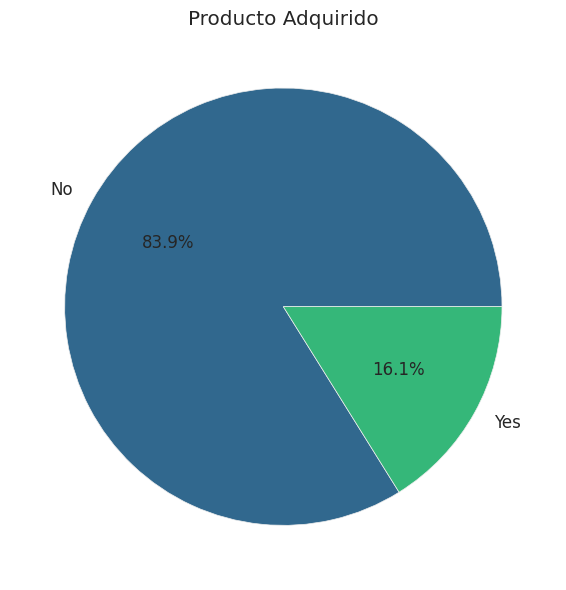

In [ ]:
colors = sns.color_palette('viridis', n_colors=2)


plt.figure(figsize=(6,6))
plt.pie(df['Taken_product'].value_counts(),
        labels=df['Taken_product'].value_counts().index,
        autopct='%1.1f%%',
        textprops={'fontsize': 12},
        colors=colors
       )
plt.title('Producto Adquirido')
plt.tight_layout()
plt.show()

Esta variable es la variable objetivo que intentaremos predecir utilizando un modelo.

### Análisis de la columna 'Adult Flag'.

Indica si el cliente es un adulto o no.

In [ ]:
df['Adult_flag']

,Adult_flag
0,0.0
1,1.0
2,0.0
3,0.0
4,1.0
...,...
11755,1.0
11756,1.0
11757,1.0
11758,0.0


In [ ]:
df['Adult_flag'].value_counts()

,count
Adult_flag,
0.0,5047
1.0,4768
2.0,1264
3.0,680


¿Cuántos valores nulos hay?

In [ ]:
df['Adult_flag'].isna().sum()

np.int64(1)

In [ ]:
df[df["Adult_flag"].isnull()]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
11,1000012,No,217.0,iOS and Android,5355.0,15,2,Financial,49.0,4193,0,Yeso,4,0,10,NaN,NaN


Se crea una nueva base de datos con los valores no nulos de la variable 'Adult Flag', ya que se considera que no afectará al análisis porque el usuario no compró.


In [ ]:
df_limpio=df[~df['Adult_flag'].isna()]

Inicialmente, debido a la definición de la variable, se asumió que el resultado sería binario (sí o no). Sin embargo, al analizar la variable, se observa que tiene cuatro posibles valores (0, 1, 2 y 3), cuyo significado aún no hemos podido determinar.

### Análisis de la columna 'Working_flag'.

Indica si el cliente está trabajando o no.

In [ ]:
df['working_flag']

,working_flag
0,No
1,Yes
2,No
3,No
4,No
...,...
11755,No
11756,No
11757,Yes
11758,No


In [ ]:
df['working_flag'].value_counts()

,count
working_flag,
No,9951
Yes,1808
0,1


Analizamos cual es la fila que tiene como resultado un 0.

In [ ]:
df[df["working_flag"]=="0"]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
11,1000012,No,217.0,iOS and Android,5355.0,15,2,Financial,49.0,4193,0,Yeso,4,0,10,NaN,NaN


Al observar que es el UserID 1000012, la misma que originó el error en 'Adult_flag' verificamos que en el nuevo data frame ya no esté incluida.

In [ ]:
df_limpio[df["UserID"]==1000012]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page


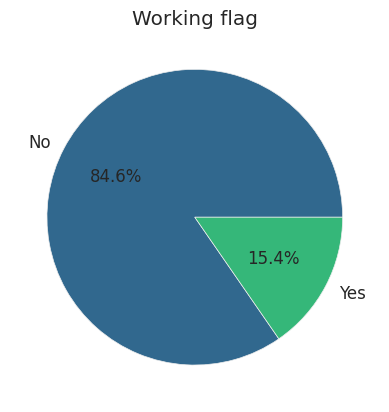

In [ ]:
plt.pie(df_limpio['working_flag'].value_counts(),
        labels=df_limpio['working_flag'].value_counts().index,
        autopct='%1.1f%%',
        textprops={'fontsize': 12},
        colors=colors)
plt.title('Working flag')
plt.show()

Esta variable contenía un valor de 0, que fue decidido eliminar, ya que solo correspondía a una fila.
Como conclusión, se observa que, en su mayoría, los casos indican que no están trabajando. Además, se realizará un análisis de correlación con la variable objetivo.

### Análisis de la columna 'Preferred_device'.

Indica el tipo de dispositivo preferido.

In [ ]:
df['preferred_device'].value_counts()

,count
preferred_device,
Tab,4172
iOS and Android,4134
Laptop,1108
iOS,1095
Mobile,600
Android,315
Android OS,145
ANDROID,134
Other,2


Se unificaron los resultados, ya que se presentaban de manera diversa, y se tomó la decisión de agrupar los valores "Android", "Android OS", "iOS", "iOs" y "Android" bajo la categoría 'Mobile'. De esta manera, se obtienen resultados más claros sobre los dispositivos (Laptop, Mobile, Tablet y Others).

In [ ]:
df_limpio['preferred_device'].value_counts()

df_limpio['preferred_device'].replace({'Android OS':'Mobile'}, inplace=True)
df_limpio['preferred_device'].replace({'android':'Mobile'}, inplace=True)
df_limpio['preferred_device'].replace({'ANDROID':'Mobile'}, inplace=True)
df_limpio['preferred_device'].replace({'Android':'Mobile'}, inplace=True)
df_limpio['preferred_device'].replace({'Other':'Others'}, inplace=True)
df_limpio['preferred_device'].replace({'iOS':'Mobile'}, inplace=True)
df_limpio['preferred_device'].replace({'iOS and Android':'Mobile'}, inplace=True)




Asignamos como NaN a los que tenían un 'nan'

In [ ]:
df_limpio['preferred_device'] = df_limpio['preferred_device'].replace({'NaN': np.nan},regex=False)

¿Hay valores nulos?

In [ ]:
df_limpio['preferred_device'].isnull().sum()

np.int64(53)

Hay 53 valores nulos, ¿cuál es el porcentaje sobre la base de datos?

In [ ]:
(df_limpio['preferred_device'].isnull().sum() / len(df)) * 100

np.float64(0.45068027210884354)

Es el 0,45%

Ante la presencia de datos nulos, se tomó la decisión de asignarles una nueva categoría denominada "Desconocido", ya que imputar valores aleatorios en la columna afectaría negativamente la predicción del modelo.

In [ ]:
df_limpio['preferred_device'] = df_limpio['preferred_device'].fillna('Desconocido')

In [ ]:
df_limpio['preferred_device'].value_counts()

,count
preferred_device,
Mobile,6422
Tab,4172
Laptop,1108
Desconocido,53
Others,4


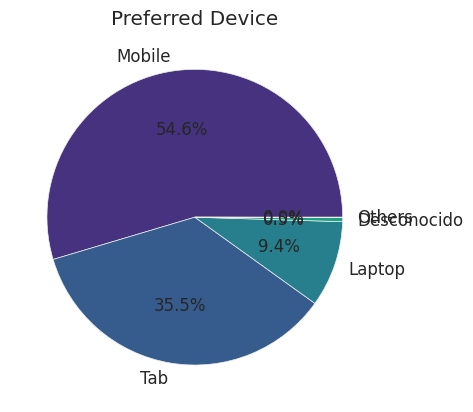

In [ ]:
colors = sns.color_palette('viridis', n_colors=6)
plt.pie(df_limpio['preferred_device'].value_counts(),
        labels=df_limpio['preferred_device'].value_counts().index,
        autopct='%1.1f%%',
        textprops={'fontsize': 12},
        colors=colors)
plt.title('Preferred Device')
plt.show()

Se observa que, en su mayoría, los usuarios utilizan dispositivos móviles (celulares) para interactuar en páginas de turismo.

### Análisis de la columna 'preferred_location_type'

Indica el tipo de ubicación preferida de viaje.

In [ ]:
df['preferred_location_type'].value_counts()

,count
preferred_location_type,
Beach,2424
Financial,2409
Historical site,1856
Medical,1845
Other,643
Big Cities,636
Social media,633
Trekking,528
Entertainment,516


Se unifican valores que representan el mismo concepto, como "Tour and Travel" y "Tour Travel", para mantener la coherencia en los datos.

In [ ]:
df_limpio['preferred_location_type'].replace({'Tour and Travel':'Tour Travel'}, inplace=True)
df_limpio['preferred_location_type'].replace({'Tour  Travel':'Tour Travel'}, inplace=True)

In [ ]:
destinos = [
    'Beach',
    'Financial',
    'Historical site',
    'Medical',
    'Other',
    'Big Cities',
    'Social media',
    'Trekking',
    'Entertainment',
    'Hill Stations',
    'Tour Travel',
    'Game',
    'OTT',
    "Movie",
    'No especificado'
]


¿Hay resultados nulos?

In [ ]:
df_limpio['preferred_location_type'].isna().sum()

np.int64(31)

Hay 31 valores nulos. ¿Cuál es el porcentaje sobre la base de datos?

In [ ]:
(df_limpio['preferred_location_type'].isna().sum()/len(df)) * 100

np.float64(0.2636054421768707)

Los valores nulos representan un 0,26% de la base de datos.

Se decide asignar el valor 'No especificado' a los valores NaN para mantener la integridad del conjunto de datos.

In [ ]:
df_limpio['preferred_location_type'] = df_limpio['preferred_location_type'].fillna('No especificado')

¿Cuál es el tipo ?

In [ ]:
df_limpio['preferred_location_type'].dtype

dtype('O')

In [ ]:
df_limpio['preferred_location_type'].value_counts()

,count
preferred_location_type,
Beach,2424
Financial,2408
Historical site,1856
Medical,1845
Other,643
Big Cities,636
Social media,633
Trekking,528
Entertainment,516


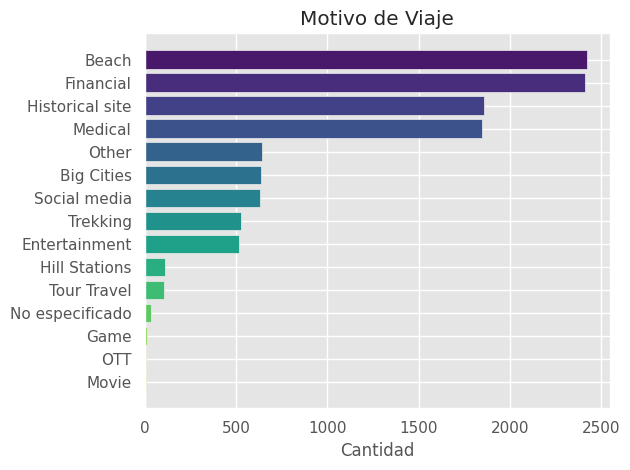

In [ ]:
counts = df_limpio['preferred_location_type'].value_counts()
destinos = counts.index

colors = sns.color_palette('viridis', n_colors=len(destinos))
plt.barh(destinos, counts, color=colors)

plt.gca().invert_yaxis()
plt.title('Motivo de Viaje')
plt.xlabel('Cantidad')
plt.tight_layout()
plt.show()

Se observa que la mayoría de los viajes son por placer(Beach) y trabajo(Financial). Y en segunda posición están motivos de Salud (Medical) y Sitios Históricos (Historical Site).  

### Análisis de la columna 'Member_in_family'.

Indica el total de relaciones mencionadas por el usuario.

In [ ]:
df['member_in_family'].value_counts()

,count
member_in_family,
3,4561
4,3184
2,2256
1,1349
5,384
Three,15
10,11


Se corrige el valor 'Three' por '3' y se une ambos resultados.

In [ ]:
df_limpio['member_in_family'] = df_limpio['member_in_family'].replace('Three', '3')

Se cambia el tipo de variable a numérico.

In [ ]:
df_limpio['member_in_family'] = pd.to_numeric(df_limpio['member_in_family'], errors='coerce')
df_limpio['member_in_family'].unique()

array([ 2,  1,  4,  3,  5, 10])

In [ ]:
df_limpio['member_in_family'].value_counts()

,count
member_in_family,
3,4576
4,3184
2,2255
1,1349
5,384
10,11


In [ ]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11759 entries, 0 to 11759
Data columns (total 17 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   UserID                                        11759 non-null  int64  
 1   Taken_product                                 11759 non-null  object 
 2   Yearly_avg_view_on_travel_page                11178 non-null  float64
 3   preferred_device                              11759 non-null  object 
 4   total_likes_on_outstation_checkin_given       11378 non-null  float64
 5   yearly_avg_Outstation_checkins                11684 non-null  object 
 6   member_in_family                              11759 non-null  int64  
 7   preferred_location_type                       11759 non-null  object 
 8   Yearly_avg_comment_on_travel_page             11553 non-null  float64
 9   total_likes_on_outofstation_checkin_received  11759 non-null  int6

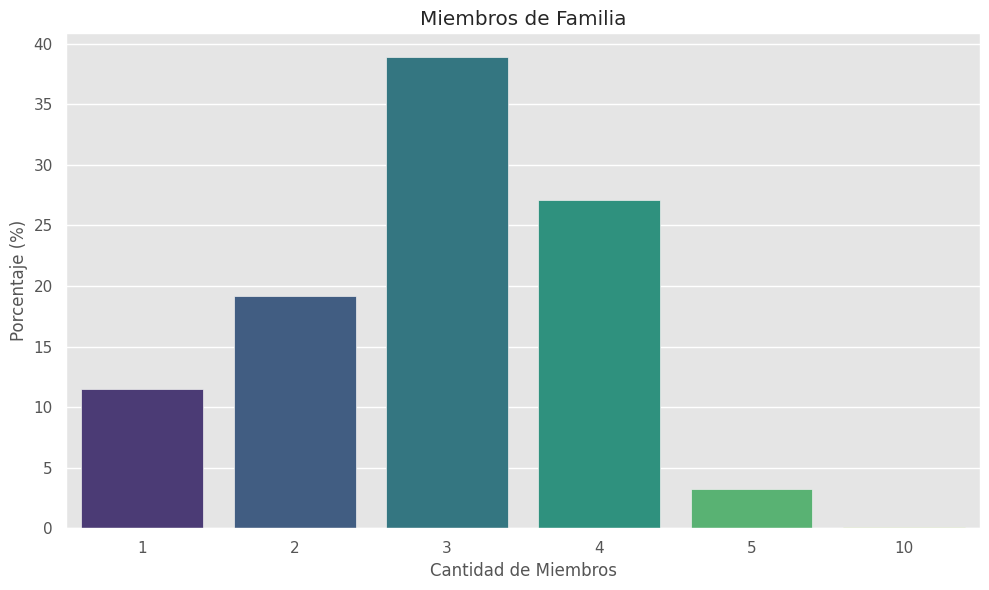

In [ ]:
# Calcular los porcentajes
porcentajes = df_limpio['member_in_family'].value_counts(normalize=True) * 100
# Convertir a DataFrame para graficar con seaborn
df_porcentajes = porcentajes.reset_index()
df_porcentajes.columns = ['member_in_family', 'percentage']
# Crear gráfico de barras
plt.figure(figsize=(10,6))
sns.barplot(
    data=df_porcentajes,
    x='member_in_family',
    y='percentage',
    palette='viridis'
)
plt.title('Miembros de Familia')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Cantidad de Miembros')
plt.tight_layout()
plt.show()

El porcentaje más alto corresponde a 3 personas por cada consulta de viaje, con casi un 40%. El segundo lugar lo ocupa el grupo de 4 personas, que representa un poco más del 25%.

### Análisis de la columna 'travelling_network_rating'

Indica la calificación de amigos que también viajan (1 es alta, 4 es baja)

In [ ]:
df_limpio['travelling_network_rating'].value_counts()

,count
travelling_network_rating,
3,3672
4,3455
2,2424
1,2208


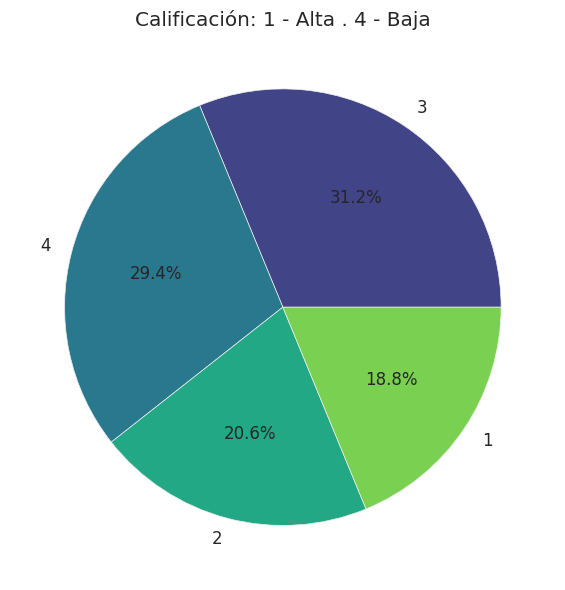

In [ ]:
counts = df_limpio['travelling_network_rating'].value_counts()
labels = counts.index

colors = sns.color_palette('viridis', n_colors=len(labels))

plt.figure(figsize=(6,6))
plt.pie(counts,
        labels=labels,
        autopct='%1.1f%%',
        textprops={'fontsize': 12},
        colors=colors
       )
plt.title('Calificación: 1 - Alta . 4 - Baja')
plt.tight_layout()
plt.show()

Se observa en el gráfico que un alto porcentaje de calificaciones son bajas, ya que al sumar los valores '3' y '4' se alcanza un 60,4%. Este porcentaje es elevado, lo cual indica que, para una mejor experiencia de viaje, se esperaría un patrón inverso.

###  Análisis de la columna 'Week_since_last_outstation_checkin'.

Indica las semanas desde el último check-in fuera de la estación.

Interpretamos que "fuera de la estación", es la estación de salida.




In [ ]:
df_limpio['week_since_last_outstation_checkin'].value_counts()

,count
week_since_last_outstation_checkin,
1,3070
3,1766
2,1700
4,1118
0,1031
5,728
6,654
7,594
9,472


¿Hay valores nulos?

In [ ]:
df_limpio['week_since_last_outstation_checkin'].isna().sum()

np.int64(0)

No hay valores nulos.

Gráfico.

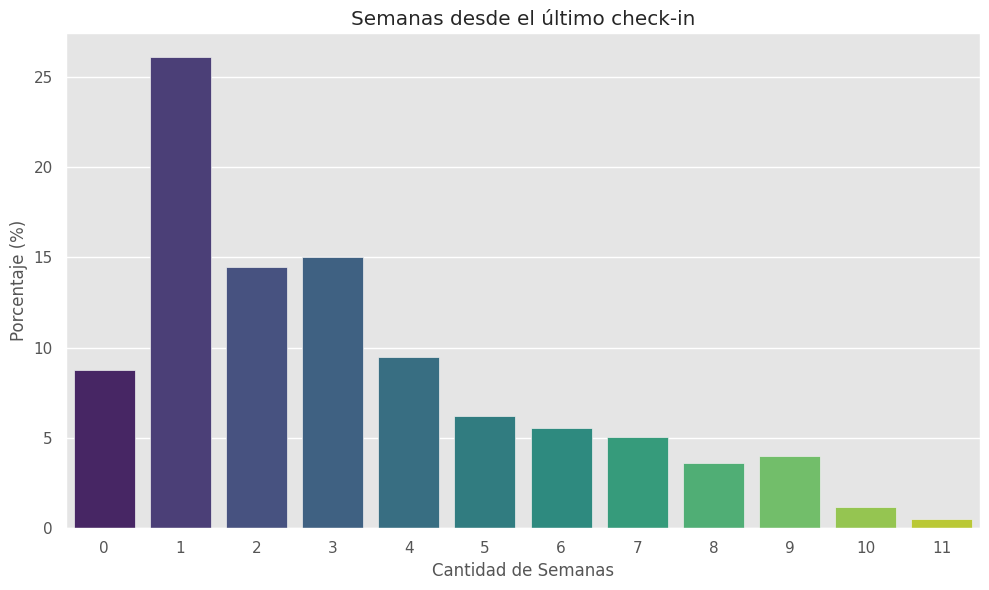

In [ ]:
# Calcular los porcentajes
porcentajes = df_limpio['week_since_last_outstation_checkin'].value_counts(normalize=True) * 100
# Convertir a DataFrame para graficar con seaborn
df_porcentajes = porcentajes.reset_index()
df_porcentajes.columns = ['week_since_last_outstation_checkin', 'percentage']
# Crear gráfico de barras
plt.figure(figsize=(10,6))
sns.barplot(
    data=df_porcentajes,
    x='week_since_last_outstation_checkin',
    y='percentage',
    palette='viridis'
)
plt.title('Semanas desde el último check-in')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Cantidad de Semanas')
plt.tight_layout()
plt.show()

Se observa que el mayor porcentaje de check-ins se concentra entre 0 y 4 semanas, lo que indica que la mayoría de los check-ins ocurren dentro del último mes.

### Análisis de la columna 'monthly_avg_comment_on_company_page'

Indica el promedio mensual de comentarios en la página de la empresa.

In [ ]:
df_limpio['montly_avg_comment_on_company_page'].value_counts()

,count
montly_avg_comment_on_company_page,
23,673
22,653
25,609
24,605
21,594
...,...
402,1
390,1
449,1


¿Hay valores nulos?

In [ ]:
df_limpio['montly_avg_comment_on_company_page'].isna().sum()

np.int64(0)

No hay valores nulos.

¿Cuál es el valor máximo?

In [ ]:
df_limpio['montly_avg_comment_on_company_page'].max()

500

Esta variable presenta un total de 160 resultados distintos, sin embargo, se observa que los primeros cinco puestos están ocupados por un promedio mensual de entre 20 y 25 comentarios.

###  Análisis de la columna 'Yearly_avg_outstation_checkins'.

Indica el promedio de check-ins fuera de la estación realizados por el usuario.

In [ ]:
df_limpio['yearly_avg_Outstation_checkins'].value_counts()

,count
yearly_avg_Outstation_checkins,
1,4543
2,844
10,682
9,340
7,336
3,336
8,320
5,261
4,256


¿Hay valores nulos?

In [ ]:
df_limpio['yearly_avg_Outstation_checkins'].isna().sum()

np.int64(75)

Hay 75 valores nulos.

Y también detectamos que un valor corresponde a '*' , filtramos la columna para observar.

In [ ]:
df_limpio[df_limpio['yearly_avg_Outstation_checkins'] == '*']

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
1618,1001619,No,307.0,Mobile,32655.0,*,4,Financial,94.0,2238,2,No,21,Yes,4,1.0,7.0


Decidimos cambiar ese '*' por '0', mismo criterio utilizamos para los NaN.

In [ ]:
df_limpio['yearly_avg_Outstation_checkins'].replace({"*":0}, inplace=True)

Observamos las filas correspondientes a los valores nulos.

In [ ]:
df_limpio[df_limpio['yearly_avg_Outstation_checkins'].isna()]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
63,1000064,No,NaN,Mobile,50225.0,NaN,3,Financial,99.0,7637,7,No,11,No,4,0.0,28.0
64,1000065,No,270.0,Mobile,42805.0,NaN,3,Entertainment,59.0,10096,1,No,13,No,2,3.0,17.0
254,1000255,No,217.0,Mobile,43645.0,NaN,2,Social media,45.0,6931,2,No,14,No,4,1.0,10.0
255,1000256,No,187.0,Mobile,23975.0,NaN,3,Financial,62.0,4898,0,No,12,No,4,2.0,5.0
447,1000448,No,262.0,Mobile,21665.0,NaN,3,Social media,85.0,4717,9,No,11,No,3,0.0,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5385,1005386,Yes,413.0,Mobile,NaN,NaN,4,Social media,95.0,13746,7,Yes,27,No,3,0.0,29.0
5433,1005434,No,421.0,Mobile,43970.0,NaN,2,Financial,98.0,2115,2,No,29,Yes,4,1.0,9.0
5505,1005506,No,249.0,Mobile,20649.0,NaN,4,Financial,94.0,5264,3,Yes,22,No,2,1.0,20.0
5625,1005626,No,NaN,Mobile,5151.0,NaN,4,Medical,91.0,4983,1,Yes,20,No,3,0.0,8.0


Determinamos que los 75 valores nulos, los pasamos a '0'

In [ ]:
df_limpio['yearly_avg_Outstation_checkins']= (df_limpio['yearly_avg_Outstation_checkins'].fillna(0))

Verificamos que se hayan corregido los NaN.

In [ ]:
df_limpio['yearly_avg_Outstation_checkins'].isna().sum()

np.int64(0)

Y verificamos que los cambios hayan sido solo a la variable deseada.

In [ ]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11759 entries, 0 to 11759
Data columns (total 17 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   UserID                                        11759 non-null  int64  
 1   Taken_product                                 11759 non-null  object 
 2   Yearly_avg_view_on_travel_page                11178 non-null  float64
 3   preferred_device                              11759 non-null  object 
 4   total_likes_on_outstation_checkin_given       11378 non-null  float64
 5   yearly_avg_Outstation_checkins                11759 non-null  object 
 6   member_in_family                              11759 non-null  int64  
 7   preferred_location_type                       11759 non-null  object 
 8   Yearly_avg_comment_on_travel_page             11553 non-null  float64
 9   total_likes_on_outofstation_checkin_received  11759 non-null  int6

Verificamos que con valor '0' sumen 76 (75 de los NaN y el *).

In [ ]:
df_limpio['yearly_avg_Outstation_checkins'].value_counts()

,count
yearly_avg_Outstation_checkins,
1,4543
2,844
10,682
9,340
7,336
3,336
8,320
5,261
4,256


Modificamos la variable de Object a Int64

In [ ]:
df_limpio['yearly_avg_Outstation_checkins'] = df_limpio['yearly_avg_Outstation_checkins'].astype(int)

In [ ]:
df_limpio['yearly_avg_Outstation_checkins'].dtype

dtype('int64')

Visualización de la variable.

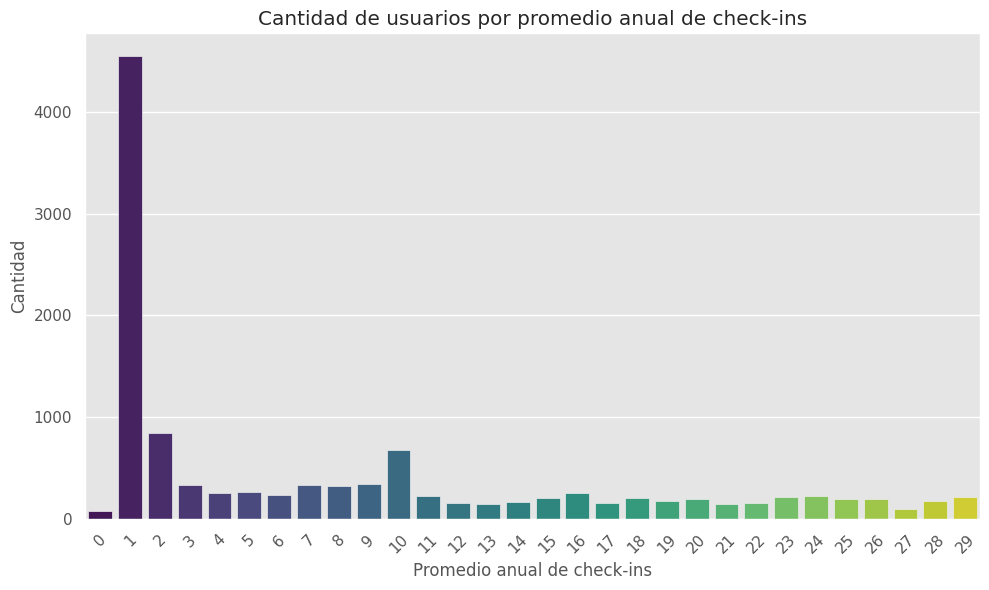

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(
    data=df_limpio,
    x='yearly_avg_Outstation_checkins',
    palette='viridis'
)
plt.title('Cantidad de usuarios por promedio anual de check-ins')
plt.ylabel('Cantidad')
plt.xlabel('Promedio anual de check-ins')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Como se puede observar, la mayoría de los usuarios realiza un viaje una vez al año.

### Análisis de la columna 'Yearly_avg_view_on_travel_page'

Indica el promedio anual de vistas en páginas relacionadas con viajes.

In [ ]:
df_limpio['Yearly_avg_view_on_travel_page'].value_counts()

,count
Yearly_avg_view_on_travel_page,
262.0,190
255.0,186
270.0,179
217.0,164
232.0,160
...,...
461.0,2
146.0,1
458.0,1


¿Hay valores nulos?

In [ ]:
df_limpio['Yearly_avg_view_on_travel_page'].isna().sum()

np.int64(581)

Hay 581 valores nulos.

¿Cuál es el porcentaje de valores nulos sobre la base de datos?

In [ ]:
(df_limpio['Yearly_avg_view_on_travel_page'].isnull().sum() / len(df)) * 100

np.float64(4.940476190476191)

Corresponde a un 4,94% de la base total.

Observamos los valores únicos.

In [ ]:
df_limpio['Yearly_avg_view_on_travel_page'].unique()

array([307., 367., 277., 247., 202., 240.,  nan, 225., 285., 270., 262.,
       232., 255., 210., 217., 165., 397., 180., 157., 330., 345., 292.,
       322., 375., 195., 360., 412., 382., 300., 405., 435., 150., 187.,
        42., 427., 352.,  35., 450., 135., 308., 368., 249., 205., 445.,
       226., 287., 271., 263., 219., 234., 256., 212., 241., 399., 286.,
       182., 159., 316., 332., 347., 248., 331., 294., 323., 376., 265.,
       204., 309., 257., 346., 264., 361., 196., 278., 444., 272., 414.,
       339., 443., 233., 280., 422., 174., 384., 302., 242., 181., 211.,
       436., 279., 151., 377., 188., 189., 166., 406., 324., 197., 143.,
       167., 383., 227., 144., 301., 429., 203., 250., 413., 338., 310.,
       392., 317., 354., 400., 369., 137., 136., 295., 391., 353., 218.,
       362., 428., 451., 430., 173., 190., 398., 355., 437., 407., 152.,
       421., 158., 293., 235., 220., 340., 385., 370., 325., 415., 452.,
       315., 379., 290., 231., 281., 269., 222., 24

Observamos las filas correspondientes a valores nulos.

In [ ]:
df_limpio[df_limpio['Yearly_avg_view_on_travel_page'].isna()]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
6,1000007,No,NaN,Mobile,46340.0,1,3,Medical,81.0,2670,4,Yes,20,Yes,1,3.0,12.0
27,1000028,No,NaN,Desconocido,24185.0,1,4,Social media,48.0,6825,0,No,11,No,4,1.0,10.0
63,1000064,No,NaN,Mobile,50225.0,0,3,Financial,99.0,7637,7,No,11,No,4,0.0,28.0
67,1000068,No,NaN,Mobile,46865.0,1,3,Financial,59.0,9724,2,No,17,No,3,1.0,25.0
70,1000071,No,NaN,Mobile,42875.0,1,1,Financial,57.0,5473,7,No,11,No,4,0.0,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5816,1005817,No,NaN,Mobile,5545.0,10,3,Medical,85.0,4488,7,Yes,25,No,4,0.0,9.0
5832,1005833,No,NaN,Mobile,52184.0,11,4,Medical,53.0,2707,8,Yes,21,No,3,1.0,8.0
5842,1005843,No,NaN,Mobile,5683.0,10,3,Financial,48.0,13803,2,Yes,414,Yes,1,1.0,20.0
5872,1005873,No,NaN,Mobile,NaN,24,1,Social media,70.0,12085,0,No,20,No,1,1.0,29.0


Se toma la decisión de asignarle un '0' a los valores nulos.

In [ ]:
df_limpio['Yearly_avg_view_on_travel_page'] = df_limpio['Yearly_avg_view_on_travel_page'].fillna(0)

In [ ]:
df_limpio['Yearly_avg_view_on_travel_page'].value_counts()

,count
Yearly_avg_view_on_travel_page,
0.0,581
262.0,190
255.0,186
270.0,179
217.0,164
...,...
461.0,2
146.0,1
458.0,1


### Análisis de la columna 'Yearly_avg_comment_on_travel_page'

Indica el promedio anual de comentarios en páginas relacionadas con viajes.

In [ ]:
df_limpio['Yearly_avg_comment_on_travel_page'].value_counts()

,count
Yearly_avg_comment_on_travel_page,
96.0,192
66.0,191
90.0,190
56.0,188
80.0,184
...,...
124.0,3
615.0,1
685.0,1


Observamos todos los valores únicos en esta columna.

In [ ]:
df_limpio['Yearly_avg_comment_on_travel_page'].unique()

array([ 94.,  61.,  92.,  56.,  40.,  79.,  81.,  67.,  44.,  84.,  31.,
        93.,  50.,  51.,  80.,  96.,  78.,  45.,  82.,  53.,  83.,  58.,
        72.,  48.,  42.,  41.,  86.,  97.,  75.,  33.,  37.,  49.,  73.,
        nan,  98.,  47.,  71.,   3.,  43.,  99.,  59.,  95.,  57.,  76.,
        87.,  66.,  55.,  32.,  52.,  70.,  62.,  64.,  63.,  60., 100.,
        46.,  39.,  77.,  91.,  54.,  34.,  90.,  65.,  36.,  88.,  35.,
        89.,  68.,  85.,  69.,  74.,  38., 106., 105., 103., 108., 111.,
       104., 102., 109., 110., 112., 101., 107., 615., 114., 113., 215.,
       815., 685., 118., 117., 115., 116., 121., 122., 120., 124., 119.,
       125., 123.])

¿Hay valores nulos?

In [ ]:
df_limpio['Yearly_avg_comment_on_travel_page'].isna().sum()

np.int64(206)

Hay 206 valores nulos.

¿Cuál es el porcentaje de valores nulos en la base de datos?

In [ ]:
(df_limpio['Yearly_avg_comment_on_travel_page'].isnull().sum() / len(df)) * 100

np.float64(1.751700680272109)

Representan el 1,75% de la base total de datos.

Se observan las filas correspondientes a los valores nulos.

In [ ]:
df_limpio[df_limpio['Yearly_avg_comment_on_travel_page'].isna()]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
48,1000049,No,345.0,Mobile,42385.0,1,4,Social media,NaN,5772,4,NaN,21,Yes,3,0.0,14.0
49,1000050,No,262.0,Mobile,NaN,1,1,Financial,NaN,2269,1,No,19,No,4,0.0,1.0
96,1000097,No,180.0,Mobile,47355.0,1,2,Other,NaN,4999,0,NaN,21,Yes,1,1.0,4.0
97,1000098,No,210.0,Mobile,NaN,1,3,Medical,NaN,4221,1,No,15,No,2,0.0,5.0
120,1000121,No,225.0,Mobile,45920.0,23,3,Financial,NaN,2613,1,No,25,Yes,3,3.0,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5305,1005306,No,235.0,Mobile,46659.0,11,2,Medical,NaN,6880,1,Yes,22,No,4,0.0,12.0
5497,1005498,No,257.0,Mobile,50449.0,1,2,Entertainment,NaN,2358,2,Yes,384,Yes,2,1.0,18.0
5689,1005690,Yes,331.0,Mobile,15053.0,1,2,Medical,NaN,2383,1,Yes,16,No,3,3.0,12.0
5713,1005714,No,354.0,Mobile,35081.0,1,3,Financial,NaN,10393,10,Yes,15,No,3,1.0,38.0


Se toma la decisión de completar los valores nulos con '0'.

In [ ]:
df_limpio['Yearly_avg_comment_on_travel_page'] = df_limpio['Yearly_avg_comment_on_travel_page'].fillna(0)

Se observa el tipo de dato.

In [ ]:
df_limpio['Yearly_avg_comment_on_travel_page'].dtype

dtype('float64')

Y se corrige el tipo de dato de flotante a entero.

In [ ]:
df_limpio['Yearly_avg_comment_on_travel_page'] = df_limpio['Yearly_avg_comment_on_travel_page'].astype(int)

In [ ]:
df_limpio['Yearly_avg_comment_on_travel_page'].dtype

dtype('int64')

Se genera el gráfico excluyendo el valor '0', el cual fue asignado a los valores nulos.

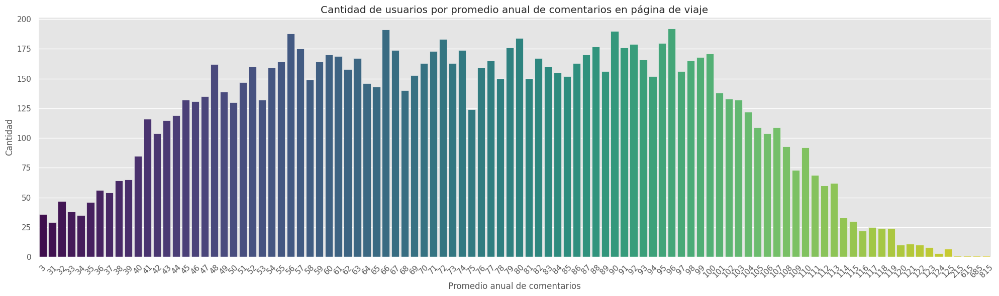

In [ ]:
plt.figure(figsize=(20,6))
sns.countplot(
    data=df_limpio[df_limpio['Yearly_avg_comment_on_travel_page']>0],
    x='Yearly_avg_comment_on_travel_page',
    palette='viridis'
)
plt.title('Cantidad de usuarios por promedio anual de comentarios en página de viaje')
plt.ylabel('Cantidad')
plt.xlabel('Promedio anual de comentarios')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Análisis de la columna 'total_likes_on_outstation_checkin_given'

Indica el total de "me gusta" dados en check-ins fuera de la estación en el último año.

In [ ]:
df_limpio['total_likes_on_outstation_checkin_given'].value_counts()

,count
total_likes_on_outstation_checkin_given,
24185.0,12
11515.0,11
37870.0,10
18550.0,10
34195.0,9
...,...
12118.0,1
40170.0,1
18571.0,1


¿Hay valores nulos?

In [ ]:
df_limpio['total_likes_on_outstation_checkin_given'].isna().sum()

np.int64(381)

Hay 381 valores nulos.

¿Cuál es el porcentaje de valores nulos sobre la base de datos?

In [ ]:
(df_limpio['total_likes_on_outstation_checkin_given'].isnull().sum() / len(df)) * 100

np.float64(3.239795918367347)

Los valores nulos representan un 3,29% de la base total de datos.

Se observa si contiene '0'.

In [ ]:
df_limpio[df_limpio['total_likes_on_outstation_checkin_given']==0]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page


Y se observa si contiene '*'.

In [ ]:
df_limpio[df_limpio['total_likes_on_outstation_checkin_given']=='*']

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page


Se observan las filas que contienen valores nulos.

In [ ]:
df_limpio[df_limpio['total_likes_on_outstation_checkin_given'].isna()]

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
7,1000008,No,225.0,Mobile,NaN,24,1,Financial,67,2693,1,No,22,Yes,2,1.0,1.0
16,1000017,No,240.0,Mobile,NaN,1,2,Financial,80,3298,0,Yes,12,No,4,2.0,7.0
17,1000018,No,165.0,Mobile,NaN,16,2,Medical,96,2935,1,Yes,13,No,2,2.0,1.0
29,1000030,No,345.0,Mobile,NaN,1,4,Social media,83,18947,3,No,12,No,4,0.0,22.0
30,1000031,No,247.0,Mobile,NaN,1,3,Medical,78,2496,4,No,11,No,4,0.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5840,1005841,No,286.0,Mobile,NaN,10,3,Medical,113,13260,5,No,24,No,1,1.0,24.0
5850,1005851,No,272.0,Mobile,NaN,1,2,Financial,107,5177,7,No,25,No,2,3.0,23.0
5864,1005865,No,339.0,Mobile,NaN,20,3,Financial,57,4897,9,No,26,No,3,0.0,15.0
5872,1005873,No,0.0,Mobile,NaN,24,1,Social media,70,12085,0,No,20,No,1,1.0,29.0


Se decide asignar el valor '0' a todos los valores nulos.

In [ ]:
df_limpio['total_likes_on_outstation_checkin_given'] = df_limpio['total_likes_on_outstation_checkin_given'].fillna(0)

Se observa el tipo de dato.

In [ ]:
df_limpio['total_likes_on_outstation_checkin_given'].dtype

dtype('float64')

Se corrige el tipo de dato de flotante a entero.

In [ ]:
df_limpio['total_likes_on_outstation_checkin_given'] = df_limpio['total_likes_on_outstation_checkin_given'].astype(int)

In [ ]:
df_limpio['total_likes_on_outstation_checkin_given'].value_counts()

,count
total_likes_on_outstation_checkin_given,
0,381
24185,12
11515,11
18550,10
37870,10
...,...
40170,1
18571,1
10585,1


### Análisis de la columna 'total_likes_on_outofstation_checkin_received'

Indica el total de "me gusta" recibidos en check-ins fuera de la estación.

In [ ]:
df_limpio['total_likes_on_outofstation_checkin_received'].value_counts()

,count
total_likes_on_outofstation_checkin_received,
2377,12
2380,11
2342,11
2096,10
2610,10
...,...
4159,1
9745,1
6021,1


¿Hay valores nulos?

In [ ]:
df_limpio['total_likes_on_outofstation_checkin_received'].isna().sum()

np.int64(0)

No hay valores nulos.

Se observa el tipo de dato.

In [ ]:
df_limpio['total_likes_on_outofstation_checkin_received'].dtype

dtype('int64')

### Análisis de la columna 'following_company_page'

In [ ]:
df_limpio['following_company_page'].value_counts()

,count
following_company_page,
No,8355
Yes,3284
1,12
0,5


¿Hay valores nulos?

In [ ]:
df_limpio['following_company_page'].isna().sum()

np.int64(103)

Hay 103 valores nulos.

Se toma la decisión de asignar 'Desconocido' a los valores NaN, así como también a los '0' y '1'.

In [ ]:
df_limpio['following_company_page'] = df_limpio['following_company_page'].fillna('Desconocido')

In [ ]:
df_limpio['following_company_page'].replace({'1':'Desconocido'}, inplace=True)
df_limpio['following_company_page'].replace({'0':'Desconocido'}, inplace=True)

In [ ]:
df_limpio['following_company_page'].value_counts()

,count
following_company_page,
No,8355
Yes,3284
Desconocido,120


Observamos el tipo de dato.

In [ ]:
df_limpio['following_company_page'].dtype

dtype('O')

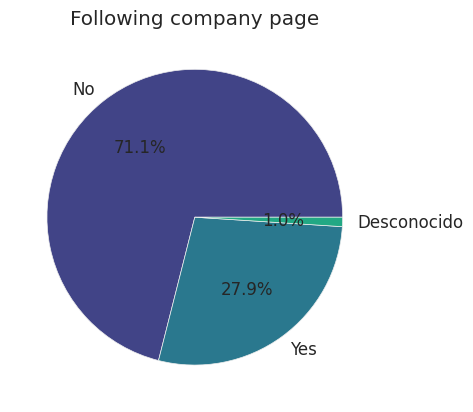

In [ ]:
plt.pie(df_limpio['following_company_page'].value_counts(),
        labels=df_limpio['following_company_page'].value_counts().index,
        autopct='%1.1f%%',
        textprops={'fontsize': 12},
        colors=colors)
plt.title('Following company page')
plt.show()

### Análisis de la columna 'Daily_Avg_mins_spend_on_traveling_page'

In [ ]:
df_limpio['Daily_Avg_mins_spend_on_traveling_page'].value_counts()

,count
Daily_Avg_mins_spend_on_traveling_page,
10.0,1125
9.0,676
8.0,662
6.0,624
7.0,554
13.0,532
11.0,530
12.0,500
14.0,496


In [ ]:
df_limpio['Daily_Avg_mins_spend_on_traveling_page'].unique()

array([  8.,  10.,   7.,   6.,  12.,   1.,  17.,   5.,   3.,  31.,  13.,
         0.,  26.,  24.,  22.,   9.,  19.,   2.,  23.,  14.,  15.,   4.,
        29.,  28.,  21.,  25.,  20.,  11.,  16.,  37.,  38.,  30.,  40.,
        18.,  36.,  34.,  32.,  33.,  35.,  27.,  41., 135.,  45.,  43.,
        39.,  44.,  42., 170., 235., 270.,  47.,  46.])

¿Hay valores nulos?

In [ ]:
df_limpio['Daily_Avg_mins_spend_on_traveling_page'].isna().sum()

np.int64(0)

No hay valores nulos.

Se observa el tipo de dato.

In [ ]:
df_limpio['Daily_Avg_mins_spend_on_traveling_page'].dtype

dtype('float64')

Se transforman los valores de tipo flotante a enteros.

In [ ]:
df_limpio['Daily_Avg_mins_spend_on_traveling_page'] = df_limpio['Daily_Avg_mins_spend_on_traveling_page'].astype(int)

Se verifica que el cambio haya impactado.

In [ ]:
df_limpio['Daily_Avg_mins_spend_on_traveling_page'].dtype

dtype('int64')

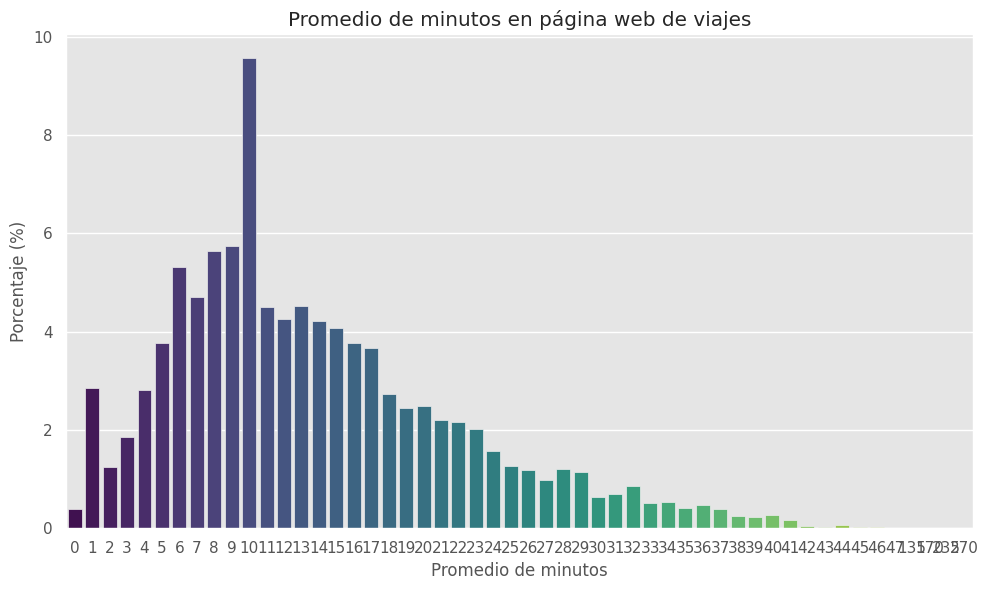

In [ ]:
# Calcular los porcentajes
porcentajes = df_limpio['Daily_Avg_mins_spend_on_traveling_page'].value_counts(normalize=True) * 100
# Convertir a DataFrame para graficar con seaborn
df_porcentajes = porcentajes.reset_index()
df_porcentajes.columns = ['Daily_Avg_mins_spend_on_traveling_page', 'percentage']
# Crear gráfico de barras
plt.figure(figsize=(10,6))
sns.barplot(
    data=df_porcentajes,
    x='Daily_Avg_mins_spend_on_traveling_page',
    y='percentage',
    palette='viridis'
)
plt.title('Promedio de minutos en página web de viajes')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Promedio de minutos')
plt.tight_layout()
plt.show()

El gráfico presenta una asimetría hacia la derecha. Con el fin de obtener una mejor visualización, se establecen rangos de 5 minutos hasta los 30 minutos, y un único rango adicional para los valores superiores a 30 minutos, dado que representan una proporción reducida de los datos.

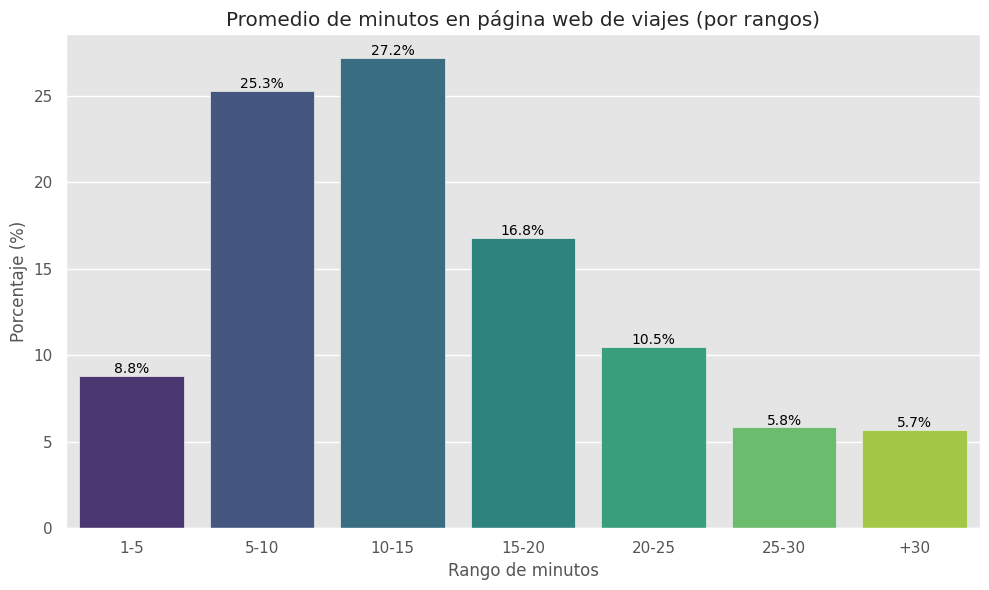

In [ ]:
bins = [1, 5, 10, 15, 20, 25, 30, float('inf')]
labels = ['1-5', '5-10', '10-15', '15-20', '20-25', '25-30', '+30']

# Crear una nueva columna con los rangos
df_limpio['rango_minutos'] = pd.cut(
    df_limpio['Daily_Avg_mins_spend_on_traveling_page'],
    bins=bins,
    labels=labels,
    right=False
)


porcentajes = df_limpio['rango_minutos'].value_counts(normalize=True).sort_index() * 100

df_porcentajes = porcentajes.reset_index()
df_porcentajes.columns = ['rango_minutos', 'percentage']

plt.figure(figsize=(10,6))
ax = sns.barplot(
    data=df_porcentajes,
    x='rango_minutos',
    y='percentage',
    palette='viridis'
)

# Etiquetas
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Promedio de minutos en página web de viajes (por rangos)')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Rango de minutos')
plt.tight_layout()
plt.show()


## Análisis preliminares conjuntos.

En esta sección, se llevará a cabo un análisis preliminar de las variables del conjunto de datos en relación con la variable objetivo. El objetivo es explorar cómo cada una de las variables explicativas podría influir en la variable objetivo, identificando posibles patrones, correlaciones y relaciones clave que podrían ser relevantes para la construcción de un modelo predictivo. A través de gráficos y estadísticas descriptivas, se analizará la distribución de las variables y se establecerán primeras conclusiones acerca de su impacto sobre la variable dependiente. Este enfoque nos permitirá obtener una visión general de las relaciones entre las variables y orientar el proceso de modelado en función de estos hallazgos iniciales.

### Relación entre 'total_likes_on_outstation_checkin_given' y 'total_likes_on_outofstation_checkin_received

Comparamos las columnas de Likes dados y recibidos.

In [ ]:
df_limpio[['total_likes_on_outstation_checkin_given','total_likes_on_outofstation_checkin_received']].describe()

,total_likes_on_outstation_checkin_given,total_likes_on_outofstation_checkin_received
count,11759.000000,11759.000000
mean,27259.678289,6531.897951
std,15002.741027,4706.764507
min,0.000000,1009.000000
25%,15114.500000,2940.500000
50%,27104.000000,4948.000000
75%,40115.500000,8393.500000
max,252430.000000,20065.000000


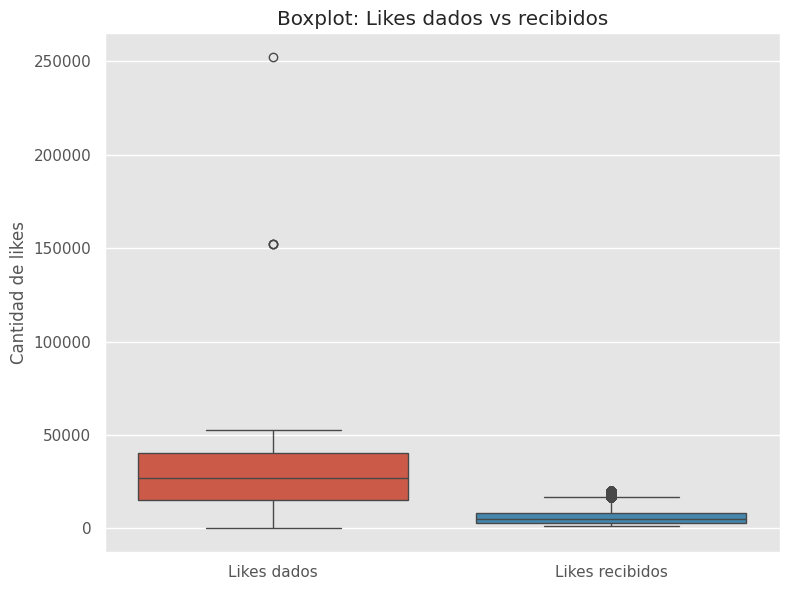

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df_limpio[['total_likes_on_outstation_checkin_given', 'total_likes_on_outofstation_checkin_received']])
plt.title('Boxplot: Likes dados vs recibidos')
plt.ylabel('Cantidad de likes')
plt.xticks([0,1], ['Likes dados', 'Likes recibidos'])
plt.tight_layout()
plt.show()

La cantidad de likes dados es sustancialmente mayor que la de likes recibidos. Sin embargo, la presencia de valores atípicos distorsiona la visualización de los datos. Para mejorar la interpretación, se limita el valor máximo a 60.000 en el siguiente gráfico, lo que permite obtener una representación más clara y detallada de la distribución.

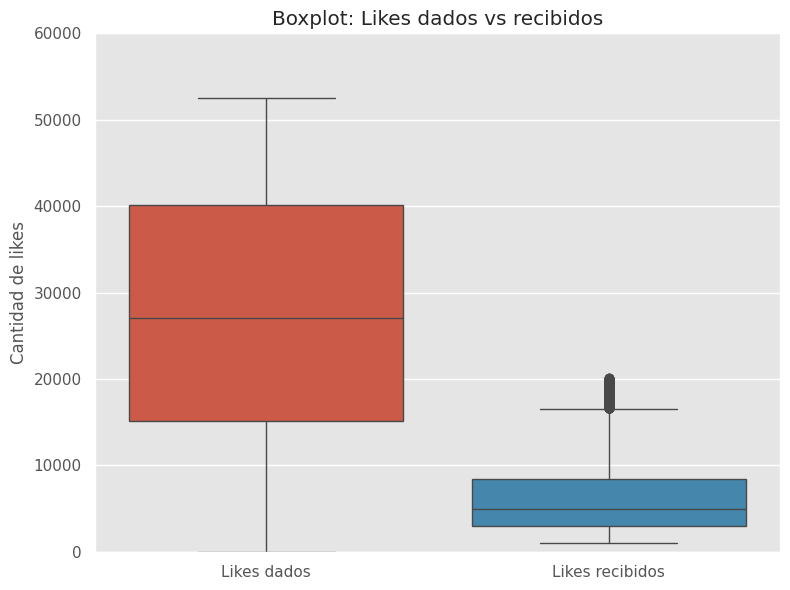

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df_limpio[['total_likes_on_outstation_checkin_given', 'total_likes_on_outofstation_checkin_received']])
plt.ylim(0,60000)
plt.title('Boxplot: Likes dados vs recibidos')
plt.ylabel('Cantidad de likes')
plt.xticks([0,1], ['Likes dados', 'Likes recibidos'])
plt.tight_layout()
plt.show()

Al comparar los likes con un límite máximo de 60.000 para mejorar la visualización, se observa que la mayoría de los likes dados se concentran por encima de la franja de 10.000, con una dispersión aproximada entre 15.000 y 40.000. En cambio, los likes recibidos se sitúan principalmente por debajo de los 10.000, con la mayor parte de los valores concentrados en ese rango.
Este patrón sugiere que, habitualmente, los usuarios dan mucho más likes de los que reciben.

### Relación entre 'total_likes_on_outofstation_checkin_received' y 'Taken_product'

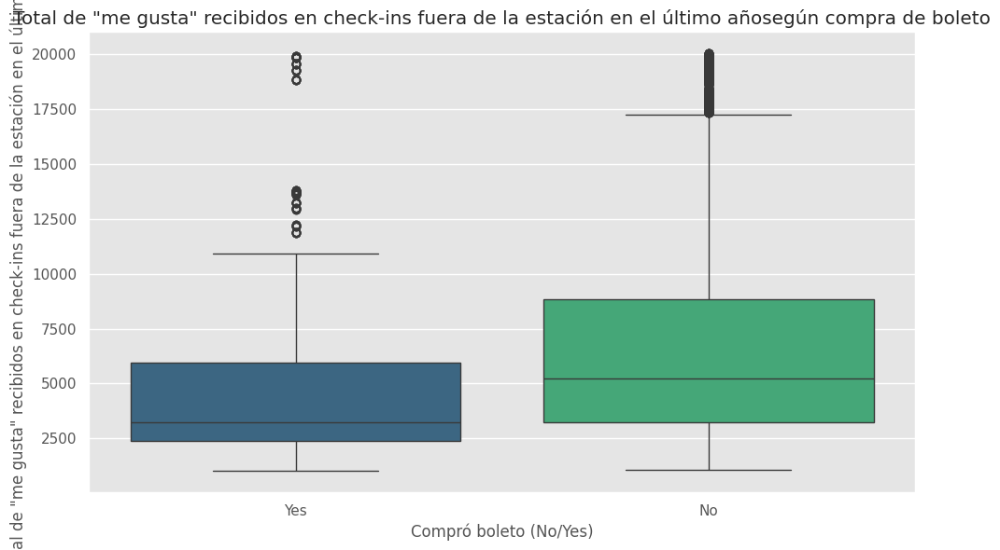

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',                  # si compró o no
    y='total_likes_on_outofstation_checkin_received', # Total Likes recibidos
    palette='viridis'
    )

plt.title('Total de "me gusta" recibidos en check-ins fuera de la estación en el último añosegún compra de boleto')
plt.xlabel('Compró boleto (No/Yes)')
plt.ylabel('Total de "me gusta" recibidos en check-ins fuera de la estación en el último año')
plt.tight_layout()
plt.show()

Al analizar el total de me gusta en función de la compra de boletos, se observa que los usuarios que no realizaron la compra registraron una mayor cantidad de me gusta en comparación con aquellos que sí la realizaron.

### Relación entre 'total_likes_on_outofstation_checkin_given' y 'Taken_product'

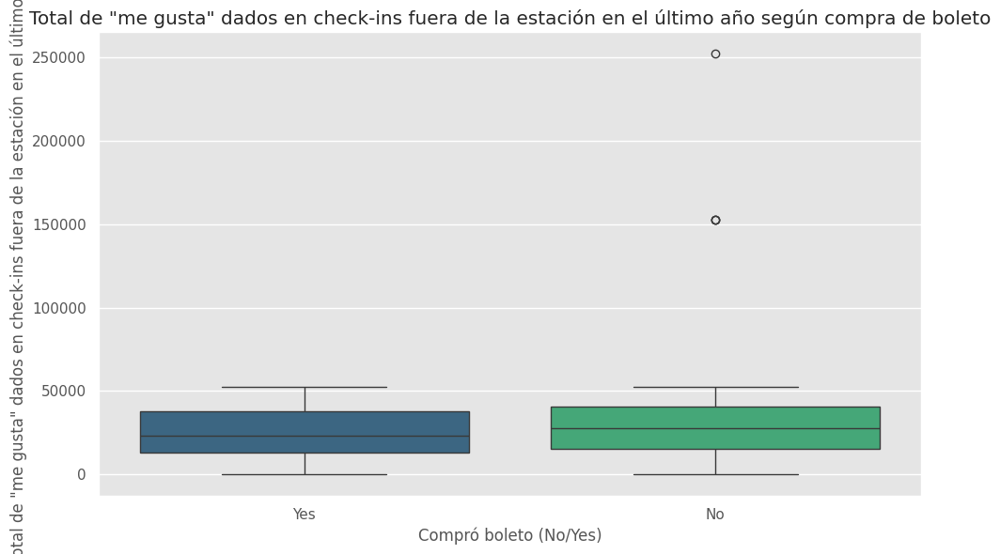

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',                  # si compró o no
    y='total_likes_on_outstation_checkin_given', # Likes dados
    palette='viridis'
    )

plt.title('Total de "me gusta" dados en check-ins fuera de la estación en el último año según compra de boleto')
plt.xlabel('Compró boleto (No/Yes)')
plt.ylabel('Total de "me gusta" dados en check-ins fuera de la estación en el último año')
plt.tight_layout()
plt.show()

Dado que los outliers distorsionan el gráfico, se decide limitar el valor máximo a 60.000 para obtener una visualización más clara y poder extraer información más relevante.

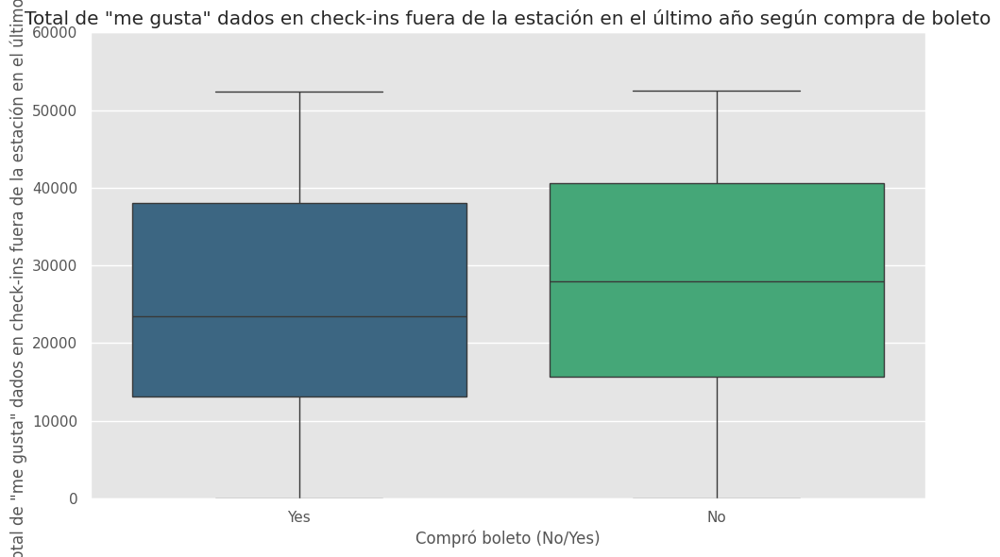

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',                  # si compró o no
    y='total_likes_on_outstation_checkin_given', # Likes dados
    palette='viridis'
    )

plt.ylim(0,60000)
plt.title('Total de "me gusta" dados en check-ins fuera de la estación en el último año según compra de boleto')
plt.xlabel('Compró boleto (No/Yes)')
plt.ylabel('Total de "me gusta" dados en check-ins fuera de la estación en el último año')
plt.tight_layout()
plt.show()


Al limitar el valor máximo en el diagrama de caja, se observa que la cantidad de me gusta es similar entre quienes no compraron boletos y quienes sí lo hicieron, aunque en estos últimos la cifra resulta ligeramente inferior.

### Relación entre 'Yearly_avg_comment_on_travel_page' y 'Taken_product'

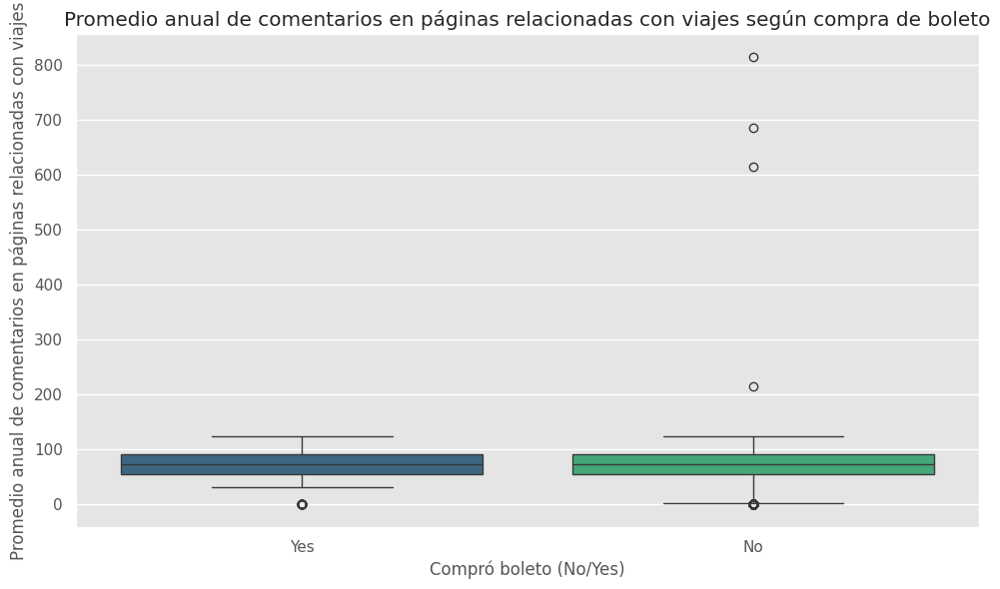

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',                  # si compró o no
    y='Yearly_avg_comment_on_travel_page',
    palette='viridis'
)

plt.title('Promedio anual de comentarios en páginas relacionadas con viajes según compra de boleto')
plt.xlabel('Compró boleto (No/Yes)')
plt.ylabel('Promedio anual de comentarios en páginas relacionadas con viajes')
plt.tight_layout()
plt.show()

Los valores atípicos distorsionan el gráfico; por ello, para mejorar la visualización del boxplot, se limita el valor máximo a 150, permitiendo así obtener información más clara y relevante.

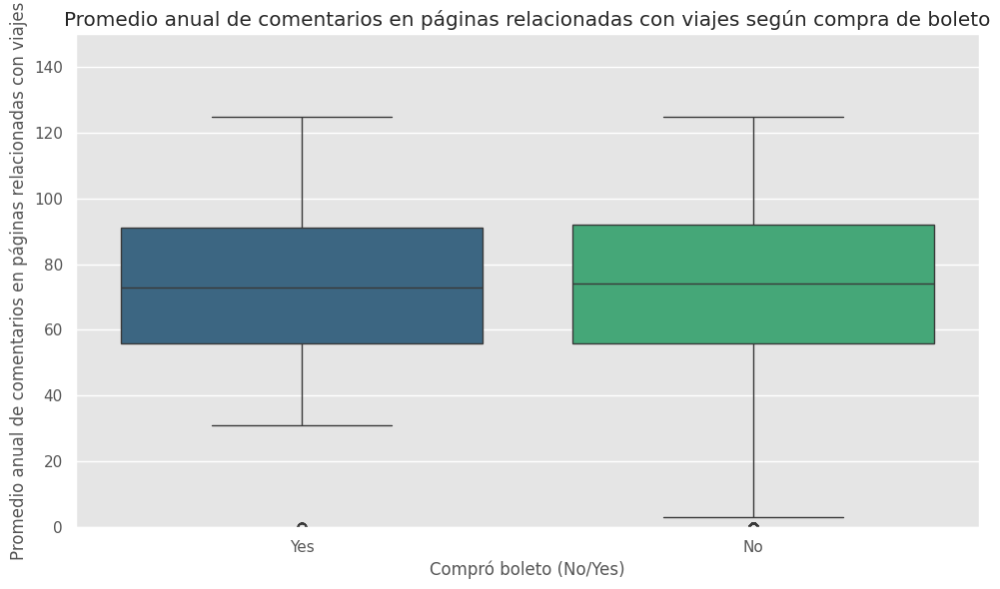

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',                  # si compró o no
    y='Yearly_avg_comment_on_travel_page',
    palette='viridis'
)

plt.ylim(0,150)
plt.title('Promedio anual de comentarios en páginas relacionadas con viajes según compra de boleto')
plt.xlabel('Compró boleto (No/Yes)')
plt.ylabel('Promedio anual de comentarios en páginas relacionadas con viajes')
plt.tight_layout()
plt.show()

Se observa que tanto quienes compran boletos como quienes no, realizan una cantidad similar de comentarios en páginas relacionadas con viajes, siendo ligeramente superior el número de comentarios entre quienes no compran boletos.

### Relación entre 'Yearly_avg_view_on_travel_page' y 'Taken_product'

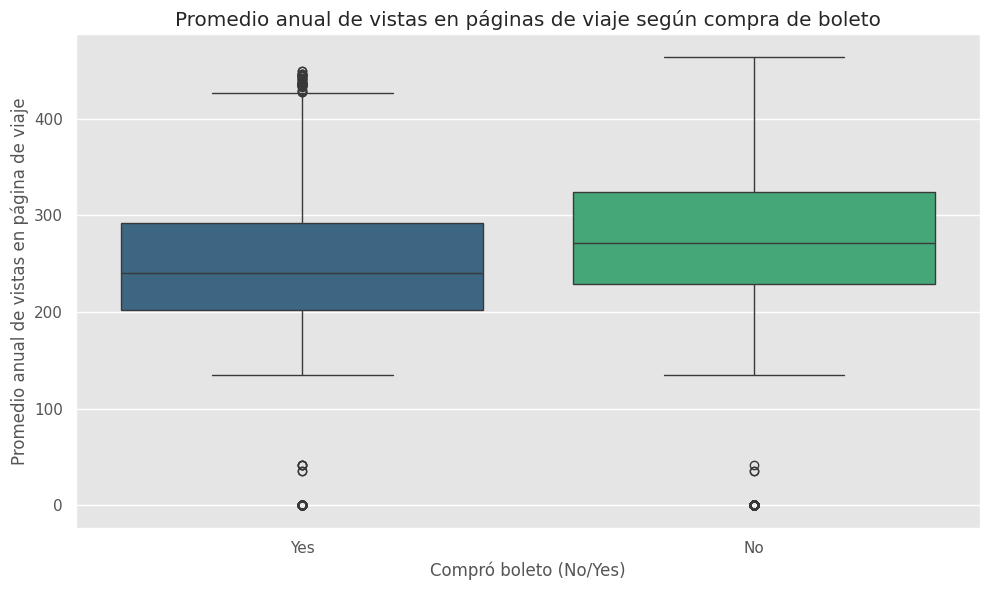

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',                  # si compró o no
    y='Yearly_avg_view_on_travel_page', # promedio de vistas
    palette='viridis'
)
plt.title('Promedio anual de vistas en páginas de viaje según compra de boleto')
plt.xlabel('Compró boleto (No/Yes)')
plt.ylabel('Promedio anual de vistas en página de viaje')
plt.tight_layout()
plt.show()

Se observa que tanto quienes compran boletos como quienes no, realizan una cantidad similar de visitas en páginas relacionadas con viajes, siendo brevemente superior el número de visitas entre quienes no compran boletos.

### Relación entre 'Travelling_network_rating' y 'Taken_product'.

Tabla de contingencias absoluta

In [ ]:
tabla = pd.crosstab(df_limpio['travelling_network_rating'], df_limpio['Taken_product'])
print("Tabla de contingencia absoluta:")
print(tabla)

Tabla de contingencia absoluta:
Taken_product                No  Yes
travelling_network_rating           
1                          1752  456
2                          2064  360
3                          3104  568
4                          2943  512


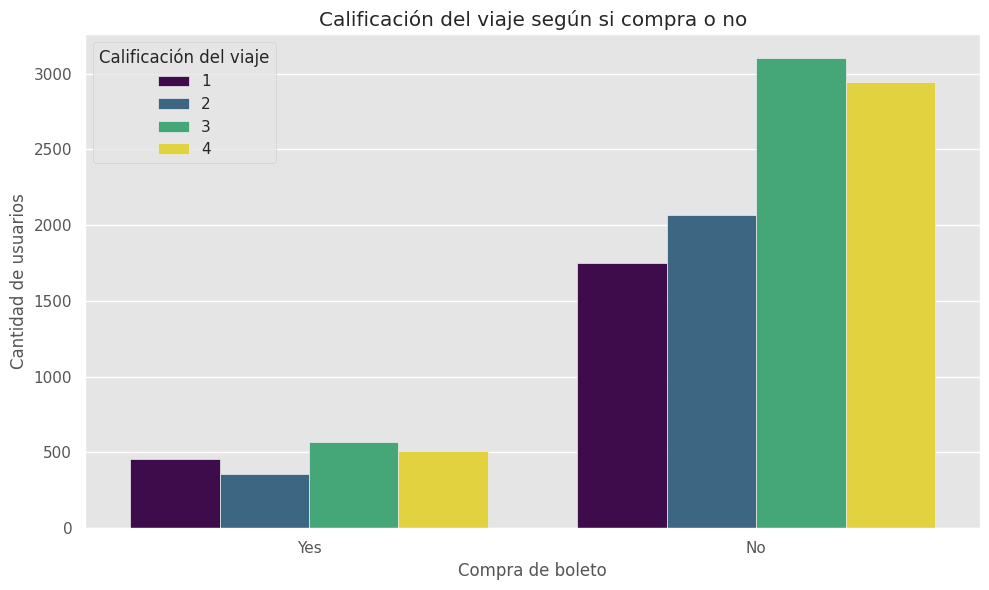

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(
    data=df_limpio,
    x='Taken_product',          # Eje X: categorías de adulto
    hue='travelling_network_rating',      # Colores: trabaja o no
    palette='viridis'
)
plt.title('Calificación del viaje según si compra o no')
plt.xlabel('Compra de boleto')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Calificación del viaje')
plt.tight_layout()
plt.show()

### Relación entre 'preferred_location_type' y 'Taken_product'

In [ ]:
df_limpio[df_limpio['Taken_product']=='Yes'][['Taken_product','preferred_location_type']].value_counts()

Taken_product  preferred_location_type
Yes            Beach                      356
               Financial                  354
               Historical site            252
               Medical                    252
               Big Cities                 140
               Social media               139
               Trekking                   128
               Entertainment              123
               Other                       87
               Tour Travel                 28
               Hill Stations               28
               OTT                          4
               No especificado              3
               Game                         1
               Movie                        1
Name: count, dtype: int64

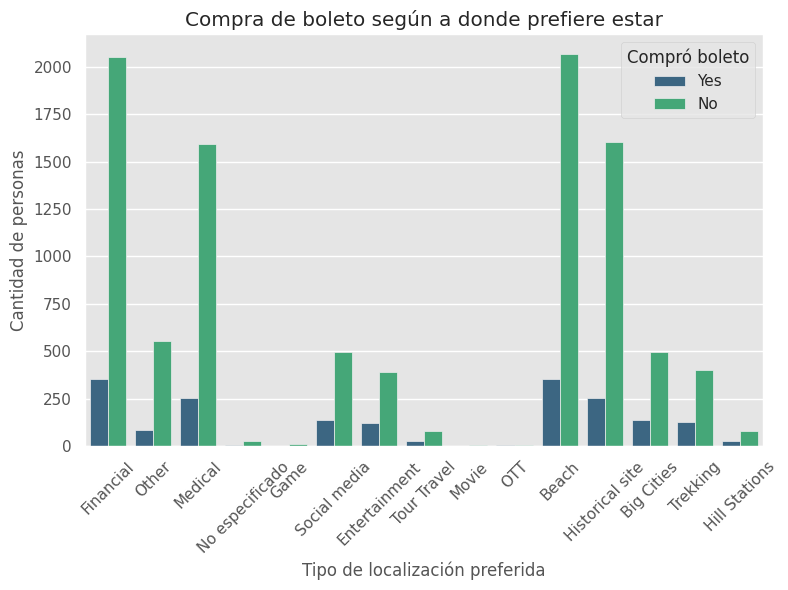

In [ ]:
plt.figure(figsize=(8,6))
sns.countplot(
    data=df_limpio,
    x='preferred_location_type',
    hue='Taken_product',
    palette='viridis')

plt.xticks(rotation=45)
plt.title('Compra de boleto según a donde prefiere estar')
plt.xlabel('Tipo de localización preferida')
plt.ylabel('Cantidad de personas')
plt.legend(title='Compró boleto')
plt.tight_layout()

Se genera una tabla de contingencias con porcentajes para observar las preferencias dentro de cada grupo.

In [ ]:
tabla_preferencia_compra = pd.crosstab(
    df_limpio['preferred_location_type'],
    df_limpio['Taken_product'],
    normalize='index'  # porcentaje por tipo de lugar
) * 100
print(tabla_preferencia_compra)

Taken_product                   No        Yes
preferred_location_type                      
Beach                    85.313531  14.686469
Big Cities               77.987421  22.012579
Entertainment            76.162791  23.837209
Financial                85.299003  14.700997
Game                     91.666667   8.333333
Hill Stations            74.074074  25.925926
Historical site          86.422414  13.577586
Medical                  86.341463  13.658537
Movie                    80.000000  20.000000
No especificado          90.322581   9.677419
OTT                      42.857143  57.142857
Other                    86.469673  13.530327
Social media             78.041074  21.958926
Tour Travel              73.831776  26.168224
Trekking                 75.757576  24.242424


Se observa que la mayor parte de los viajes realizados y las personas que compran boletos lo hacen por motivos financieros, de salud y vacacionales, con una clara preferencia por destinos de playa. Asimismo, se destaca que, en su mayoría, los usuarios optan por no viajar ni comprar boletos, independientemente del motivo de búsqueda del viaje o de la localización preferida.

### Relación entre 'Adult_flag' y 'Taken_product'

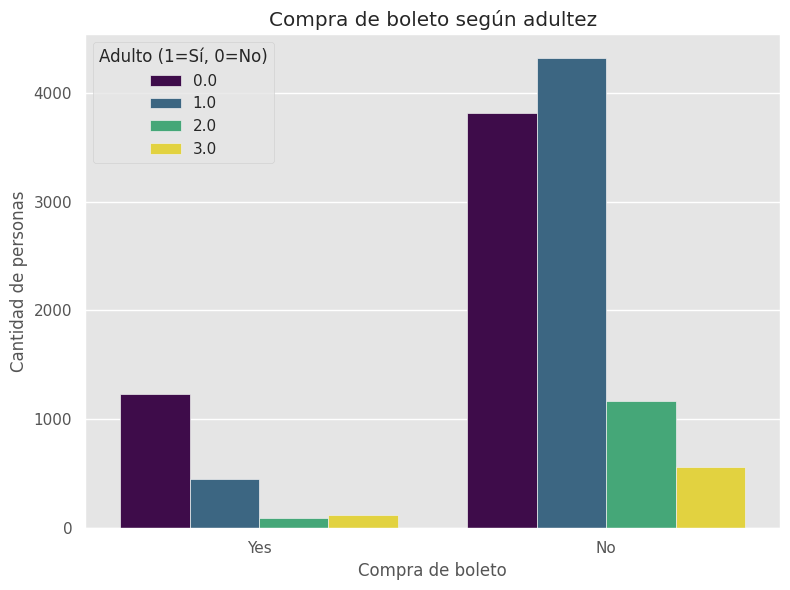

In [ ]:
plt.figure(figsize=(8,6))
sns.countplot(data=df_limpio, x='Taken_product', hue='Adult_flag', palette='viridis')
plt.title('Compra de boleto según adultez')
plt.xlabel('Compra de boleto')
plt.ylabel('Cantidad de personas')
plt.legend(title='Adulto (1=Sí, 0=No)')
plt.tight_layout()
plt.show()

### Relación entre 'Adult_flag' y 'Working_flag'

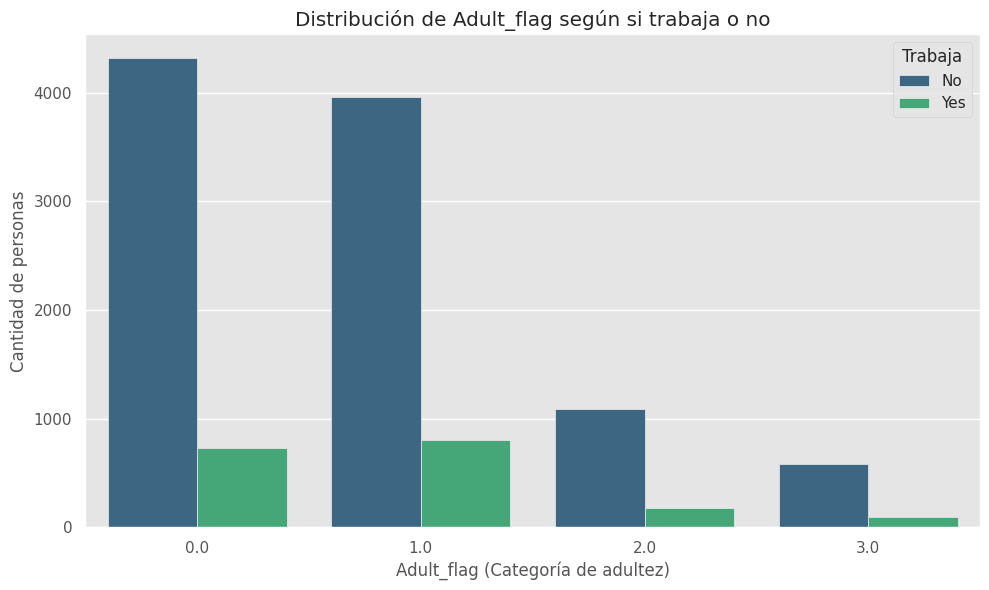

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(
    data=df_limpio,
    x='Adult_flag',          # Eje X: categorías de adulto
    hue='working_flag',      # Colores: trabaja o no
    palette='viridis'        # Paleta de colores
)
plt.title('Distribución de Adult_flag según si trabaja o no')
plt.xlabel('Adult_flag (Categoría de adultez)')
plt.ylabel('Cantidad de personas')
plt.legend(title='Trabaja')
plt.tight_layout()
plt.show()

Se vuelve a graficar de manera proporcional para mejorar la visualización y poder observar con mayor claridad los resultados.


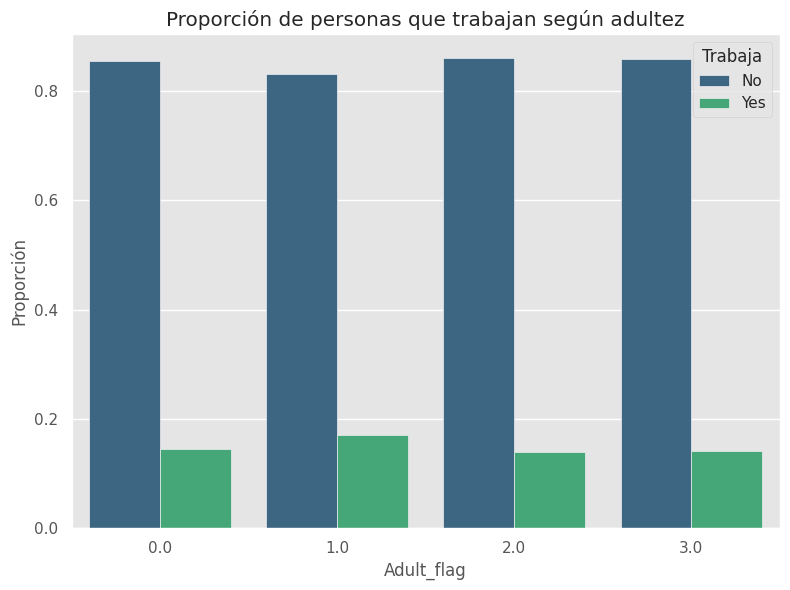

In [ ]:
tabla_prop = (
    pd.crosstab(df_limpio['Adult_flag'], df_limpio['working_flag'], normalize='index')
    .reset_index()
    .melt(id_vars='Adult_flag', var_name='working_flag', value_name='proportion')
)

plt.figure(figsize=(8,6))
sns.barplot(data=tabla_prop, x='Adult_flag', y='proportion', hue='working_flag', palette='viridis')

plt.title('Proporción de personas que trabajan según adultez')
plt.xlabel('Adult_flag')
plt.ylabel('Proporción')
plt.legend(title='Trabaja')
plt.tight_layout()
plt.show()

Se observa que en cada categoría de Adultos, aproximadamente el 80% de los individuos no están trabajando.

### Relación entre 'Adult_flag' y 'preferred_device'

In [ ]:
Dispositivo = pd.crosstab(df_limpio['Adult_flag'], df_limpio['preferred_device'])
print(Dispositivo)

preferred_device  Desconocido  Laptop  Mobile  Others   Tab
Adult_flag                                                 
0.0                        27     484    2734       2  1800
1.0                        22     456    2609       1  1680
2.0                         1     112     694       1   456
3.0                         3      56     385       0   236


### Relación entre 'Adult_flag' y 'preferred_location_type'


In [ ]:
df_Cluster = df_limpio

In [ ]:
def crear_heatmap_adult_flag_location(df_Cluster):
    """
    Crea un mapa de calor específico entre Adult_flag y preferred_location_type
    """

    # Verificar que el DataFrame tenga las columnas necesarias
    if 'Adult_flag' not in df_Cluster.columns or 'preferred_location_type' not in df_Cluster.columns:
        print("Error: El DataFrame debe contener las columnas 'Adult_flag' y 'preferred_location_type'")
        return

    # Verificar que no esté vacío
    if df_Cluster.empty:
        print("Error: El DataFrame está vacío")
        return

    # Crear tabla de contingencia
    tabla_contingencia = pd.crosstab(df_Cluster['Adult_flag'],
                                    df_Cluster['preferred_location_type'],
                                    normalize='index') * 100

    # Mostrar información sobre los datos
    print(f"Total de registros: {len(df_Cluster)}")
    print(f"Valores únicos en Adult_flag: {df_Cluster['Adult_flag'].unique()}")
    print(f"Valores únicos en preferred_location_type: {df_Cluster['preferred_location_type'].unique()}")
    print(f"\nTabla de contingencia (porcentajes por fila):")
    print(tabla_contingencia.round(2))

    # Crear el mapa de calor
    plt.figure(figsize=(14, 10))

    # Crear heatmap con seaborn
    sns.heatmap(tabla_contingencia,
                annot=True,           # Mostrar valores
                fmt='.1f',           # Formato de números
                cmap='YlOrRd',       # Paleta de colores
                cbar_kws={'label': 'Porcentaje (%)'},
                linewidths=0.5,      # Líneas de separación
                square=False)        # No forzar forma cuadrada

    # Configurar título y etiquetas
    plt.title('Mapa de Calor: Adult_flag vs preferred_location_type\n(Porcentajes por fila)',
              fontsize=16, fontweight='bold', pad=20)
    plt.xlabel('Tipo de Ubicación Preferida', fontweight='bold', fontsize=12)
    plt.ylabel('Adult_flag', fontweight='bold', fontsize=12)

    # Rotar etiquetas del eje X para mejor legibilidad
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    # Crear también un heatmap con frecuencias absolutas
    tabla_frecuencias = pd.crosstab(df_Cluster['Adult_flag'],
                                   df_Cluster['preferred_location_type'])

    plt.figure(figsize=(14, 10))

    sns.heatmap(tabla_frecuencias,
                annot=True,           # Mostrar valores
                fmt='d',             # Formato de números enteros
                cmap='Blues',        # Paleta de colores diferente
                cbar_kws={'label': 'Frecuencia'},
                linewidths=0.5,
                square=False)

    plt.title('Mapa de Calor: Adult_flag vs preferred_location_type\n(Frecuencias absolutas)',
              fontsize=16, fontweight='bold', pad=20)
    plt.xlabel('Tipo de Ubicación Preferida', fontweight='bold', fontsize=12)
    plt.ylabel('Adult_flag', fontweight='bold', fontsize=12)

    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

def crear_heatmap_adult_flag_location(df_Cluster):
    """
    Crea un mapa de calor específico entre Adult_flag y preferred_location_type
    """

    # Verificar que el DataFrame tenga las columnas necesarias
    if 'Adult_flag' not in df_Cluster.columns or 'preferred_location_type' not in df_Cluster.columns:
        print("Error: El DataFrame debe contener las columnas 'Adult_flag' y 'preferred_location_type'")
        return

    # Verificar que no esté vacío
    if df_Cluster.empty:
        print("Error: El DataFrame está vacío")
        return

    # Verificar que haya datos válidos en las columnas
    if df_Cluster['Adult_flag'].isna().all() or df_Cluster['preferred_location_type'].isna().all():
        print("Error: Las columnas contienen solo valores NaN")
        return

    # Mostrar información sobre los datos
    print(f"Total de registros: {len(df_Cluster)}")
    print(f"Valores únicos en Adult_flag: {df_Cluster['Adult_flag'].unique()}")
    print(f"Valores únicos en preferred_location_type: {df_Cluster['preferred_location_type'].unique()}")

    # Crear tabla de contingencia con manejo de errores
    try:
        tabla_contingencia = pd.crosstab(df_Cluster['Adult_flag'],
                                        df_Cluster['preferred_location_type'],
                                        normalize='index') * 100

        # Verificar si la tabla tiene datos
        if tabla_contingencia.empty or tabla_contingencia.shape[0] == 0 or tabla_contingencia.shape[1] == 0:
            print("Error: No se pueden crear tablas de contingencia con los datos proporcionados")
            print("Verifica que haya valores válidos en ambas columnas")
            return

        print(f"\nTabla de contingencia (porcentajes por fila):")
        print(tabla_contingencia.round(2))

        # Crear el mapa de calor de porcentajes
        plt.figure(figsize=(14, 10))

        # Crear heatmap con seaborn
        sns.heatmap(tabla_contingencia,
                    annot=True,           # Mostrar valores
                    fmt='.1f',           # Formato de números
                    cmap='YlOrRd',       # Paleta de colores
                    cbar_kws={'label': 'Porcentaje (%)'},
                    linewidths=0.5,      # Líneas de separación
                    square=False)        # No forzar forma cuadrada

        # Configurar título y etiquetas
        plt.title('Mapa de Calor: Adult_flag vs preferred_location_type\n(Porcentajes por fila)',
                  fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Tipo de Ubicación Preferida', fontweight='bold', fontsize=12)
        plt.ylabel('Adult_flag', fontweight='bold', fontsize=12)

        # Rotar etiquetas del eje X para mejor legibilidad
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error al crear el heatmap de porcentajes: {e}")
        print("Verifica que los datos sean válidos")
        return

    # Crear también un heatmap con frecuencias absolutas
    try:
        tabla_frecuencias = pd.crosstab(df_Cluster['Adult_flag'],
                                       df_Cluster['preferred_location_type'])

        # Verificar si la tabla tiene datos
        if tabla_frecuencias.empty or tabla_frecuencias.shape[0] == 0 or tabla_frecuencias.shape[1] == 0:
            print("Error: No se pueden crear tablas de frecuencias con los datos proporcionados")
            return

        plt.figure(figsize=(14, 10))

        sns.heatmap(tabla_frecuencias,
                    annot=True,           # Mostrar valores
                    fmt='d',             # Formato de números enteros
                    cmap='Blues',        # Paleta de colores diferente
                    cbar_kws={'label': 'Frecuencia'},
                    linewidths=0.5,
                    square=False)

        plt.title('Mapa de Calor: Adult_flag vs preferred_location_type\n(Frecuencias absolutas)',
                  fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Tipo de Ubicación Preferida', fontweight='bold', fontsize=12)
        plt.ylabel('Adult_flag', fontweight='bold', fontsize=12)

        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error al crear el heatmap de frecuencias: {e}")
        print("Verifica que los datos sean válidos")
        return



Total de registros: 11759
Valores únicos en Adult_flag: [0. 1. 3. 2.]
Valores únicos en preferred_location_type: ['Financial' 'Other' 'Medical' 'No especificado' 'Game' 'Social media'
 'Entertainment' 'Tour Travel' 'Movie' 'OTT' 'Beach' 'Historical site'
 'Big Cities' 'Trekking' 'Hill Stations']

Tabla de contingencia (porcentajes por fila):
preferred_location_type  Beach  Big Cities  Entertainment  Financial  Game  \
Adult_flag                                                                   
0.0                      20.53        4.99           4.40      20.45  0.10   
1.0                      21.22        5.54           4.84      21.10  0.10   
2.0                      20.57        6.65           3.40      20.09  0.16   
3.0                      17.06        5.29           2.94      17.06  0.00   

preferred_location_type  Hill Stations  Historical site  Medical  Movie  \
Adult_flag                                                                
0.0                               0.7

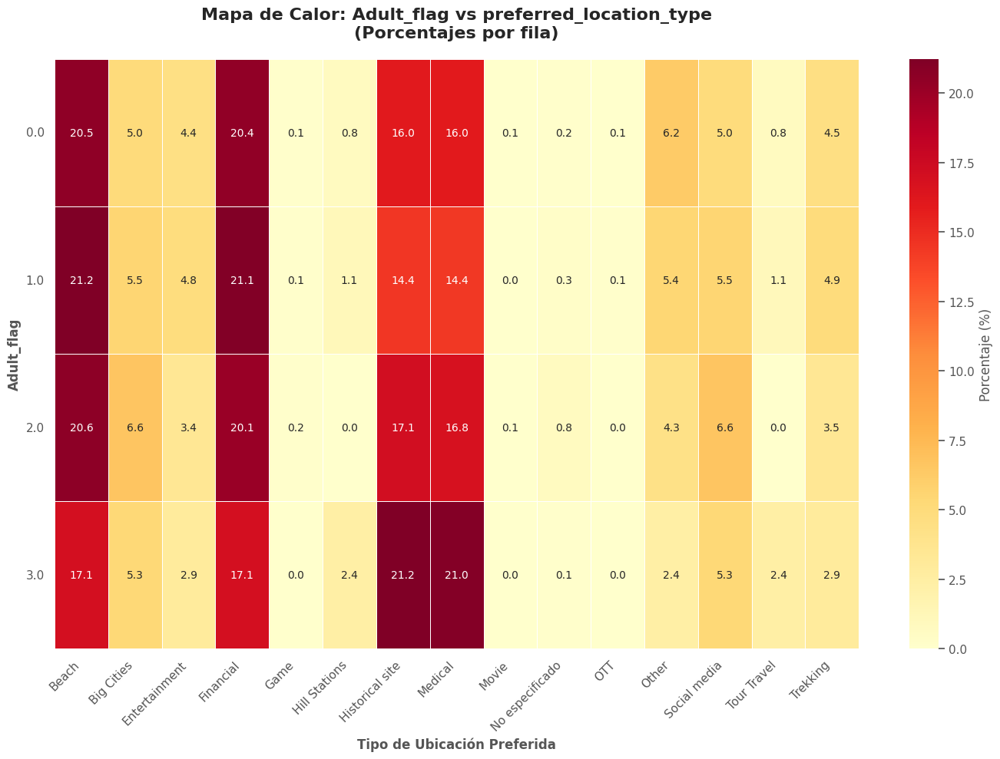

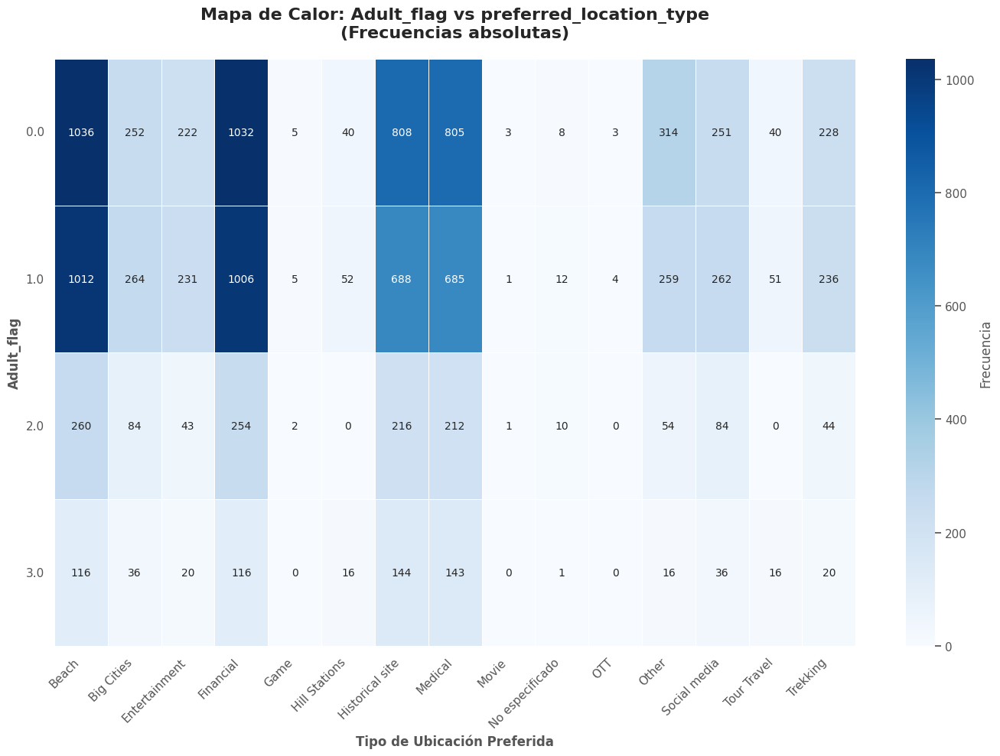

In [ ]:
crear_heatmap_adult_flag_location(df_Cluster)

Según lo observado, podemos deducir que la categoría "Adultos 3.0" corresponde a personas de edad avanzada. Esta conclusión se sustenta en sus preferencias de viaje, que se enfocan principalmente en sitios históricos y motivos médicos. Además, presentan un porcentaje muy bajo en actividades como trekking y uno notablemente más alto en destinos de tipo Hill Station, en comparación con las otras categorías. También se observa que son quienes menos trabajan.

Asimismo, el grupo 3 es el que menos utiliza dispositivos electrónicos, lo cual refuerza la hipótesis de que se trata de personas mayores. En contraposición, la categoría 0 muestra un uso elevado de dispositivos, lo que podría estar asociado a un perfil adolescente o joven.

De esta manera, se podría inferir que las categorías 0, 1, 2 y 3 del campo Adult_flag representan distintos rangos etarios, posiblemente en orden creciente.

### Relación entre 'Preferred_device' y 'Taken_product'

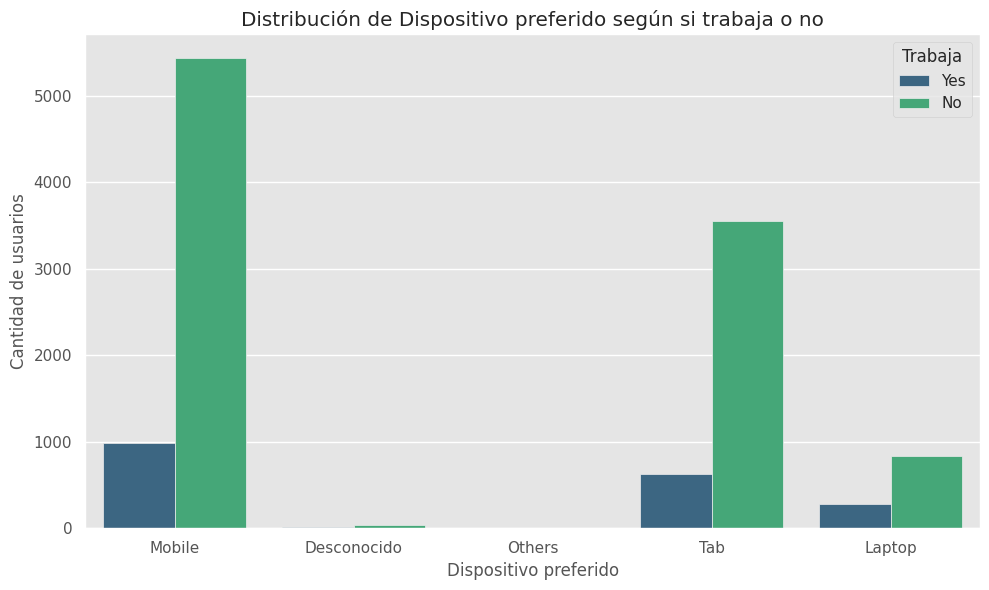

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(
    data=df_limpio,
    x='preferred_device',
    hue='Taken_product',
    palette='viridis'
)
plt.title('Distribución de Dispositivo preferido según si trabaja o no')
plt.xlabel('Dispositivo preferido')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Trabaja')
plt.tight_layout()
plt.show()

En este gráfico, se observa que la cantidad de usuarios que no trabajan es aproximadamente un 70% superior a la de aquellos que sí trabajan, en todos los dispositivos móviles. Además, se destaca que el celular es el dispositivo móvil más elegido por los usuarios.

### Relación entre 'working_flag' y 'Taken_product'

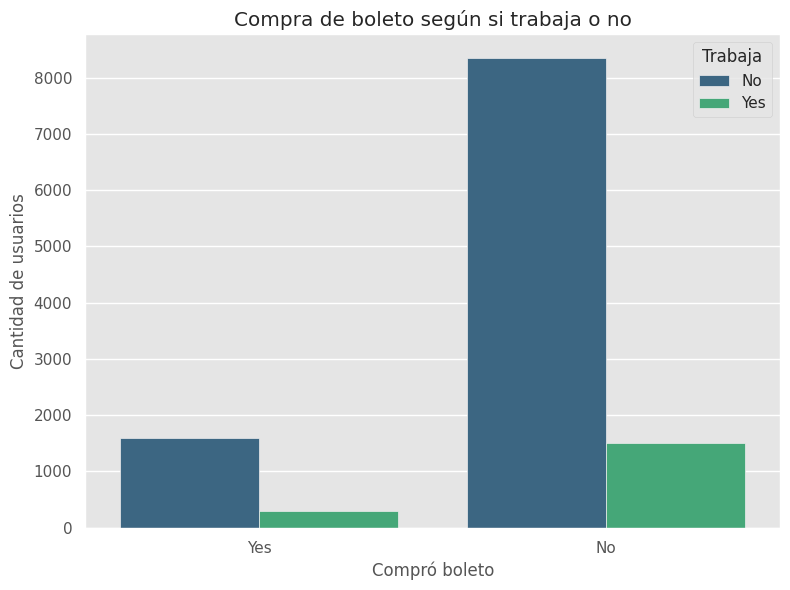

In [ ]:
plt.figure(figsize=(8,6))
sns.countplot(data=df_limpio, x='Taken_product', hue='working_flag', palette='viridis')
plt.title('Compra de boleto según si trabaja o no')
plt.xlabel('Compró boleto')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Trabaja')
plt.tight_layout()
plt.show()

In [ ]:
def analizar_correlacion_taken_working(df):
    """
    Analiza la correlación entre Taken_product y Working_flag
    """
    # Verificar que las variables existen
    if 'Taken_product' not in df.columns or 'working_flag' not in df.columns:
        print("❌ Error: Una o ambas variables no existen en el dataframe")
        print(f"Columnas disponibles: {df.columns.tolist()}")
        return None, None

    # Información básica de las variables
    print("=== INFORMACIÓN DE LAS VARIABLES ===")
    print(f"Taken_product - Tipo: {df['Taken_product'].dtype}")
    print(f"Taken_product - Valores únicos: {df['Taken_product'].nunique()}")
    print(f"working_flag - Tipo: {df['working_flag'].dtype}")
    print(f"working_flag - Valores únicos: {df['working_flag'].nunique()}")

    # Mostrar algunos valores únicos
    print(f"\nValores únicos de Taken_product: {df['Taken_product'].unique()}")
    print(f"Valores únicos de Working_flag: {df['working_flag'].unique()}")

    # Si las variables son categóricas, usar correlación de Spearman
    if df['Taken_product'].dtype == 'object' or df['working_flag'].dtype == 'object':
        print("\n=== CORRELACIÓN PARA VARIABLES CATEGÓRICAS ===")

        # Convertir a numérico para correlación
        taken_numeric = pd.Categorical(df['Taken_product']).codes
        working_numeric = pd.Categorical(df['working_flag']).codes

        correlacion_spearman = np.corrcoef(taken_numeric, working_numeric)[0, 1]
        print(f"Correlación de Spearman: {correlacion_spearman:.4f}")

        # Interpretación
        if abs(correlacion_spearman) >= 0.7:
            fuerza = "fuerte"
        elif abs(correlacion_spearman) >= 0.5:
            fuerza = "moderada"
        elif abs(correlacion_spearman) >= 0.3:
            fuerza = "débil"
        else:
            fuerza = "muy débil"

        direccion = "positiva" if correlacion_spearman > 0 else "negativa"
        print(f"La correlación es {fuerza} y {direccion}")

        return correlacion_spearman, None

    else:
        # Si son numéricas, usar Pearson
        print("\n=== CORRELACIÓN PARA VARIABLES NUMÉRICAS ===")
        correlacion_pearson = df['Taken_product'].corr(df['working_flag'], method='pearson')
        correlacion_spearman = df['Taken_product'].corr(df['working_flag'], method='spearman')

        print(f"Correlación de Pearson: {correlacion_pearson:.4f}")
        print(f"Correlación de Spearman: {correlacion_spearman:.4f}")

        return correlacion_pearson, correlacion_spearman

# Ejecutar el análisis
correlacion = analizar_correlacion_taken_working(df_limpio)

=== INFORMACIÓN DE LAS VARIABLES ===
Taken_product - Tipo: object
Taken_product - Valores únicos: 2
working_flag - Tipo: object
working_flag - Valores únicos: 2

Valores únicos de Taken_product: ['Yes' 'No']
Valores únicos de Working_flag: ['No' 'Yes']

=== CORRELACIÓN PARA VARIABLES CATEGÓRICAS ===
Correlación de Spearman: 0.0029
La correlación es muy débil y positiva


Se observa que la cantidad de usuarios que no compran boletos y no trabajan es considerablemente superior a la de aquellos que no compran boletos pero sí trabajan. Por otro lado, entre los usuarios que sí compran boletos, es mayor la cantidad de quienes no trabajan en comparación con aquellos que sí lo hacen.

Según el resultado de la correlación, se puede concluir que las variables son independientes, lo que implica que el hecho de que una persona trabaje o no no influirá en su decisión de compra de boletos.

### Relación entre 'montly_avg_comment_on_company_page' y 'Taken_product'

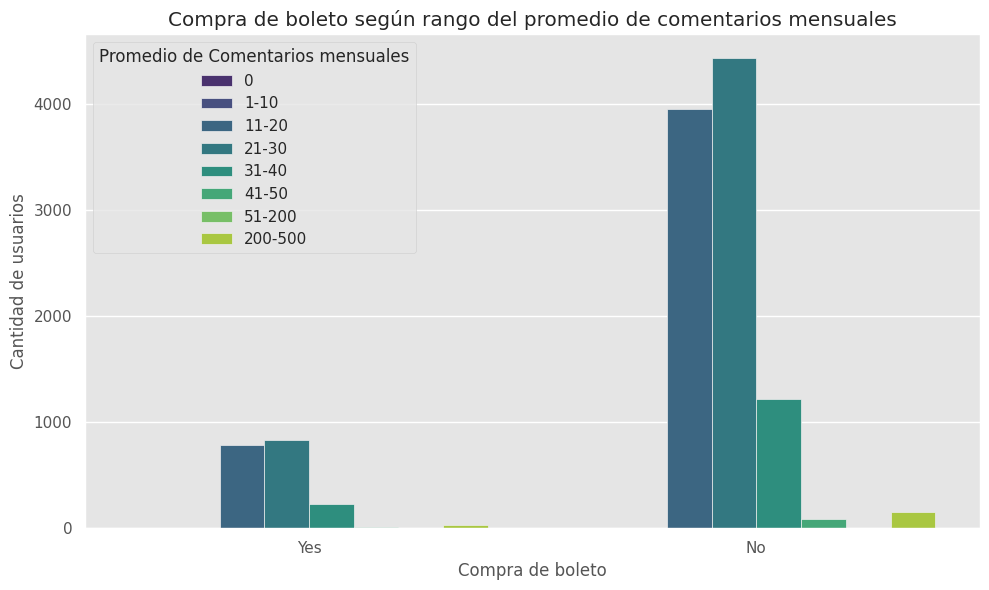

In [ ]:
df_limpio['comentarios_categoria'] = pd.cut(
    df_limpio['montly_avg_comment_on_company_page'],
    bins=[-1, 0, 10, 20, 30, 40, 50, 200, float('inf')],
    labels=['0', '1-10', '11-20', '21-30', '31-40', '41-50', '51-200', '200-500']
)


plt.figure(figsize=(10,6))
sns.countplot(
    data=df_limpio,
    x='Taken_product',
    hue='comentarios_categoria',
    palette='viridis'
)
plt.title('Compra de boleto según rango del promedio de comentarios mensuales')
plt.xlabel('Compra de boleto')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Promedio de Comentarios mensuales')
plt.tight_layout()
plt.show()


Se observa que la gente que menos comentarios hace sobre pubicaciones son los que toman la decision de comprar los boletos.

### Relación entre 'yearly_avg_Outstation_checkins' y 'Taken_product'

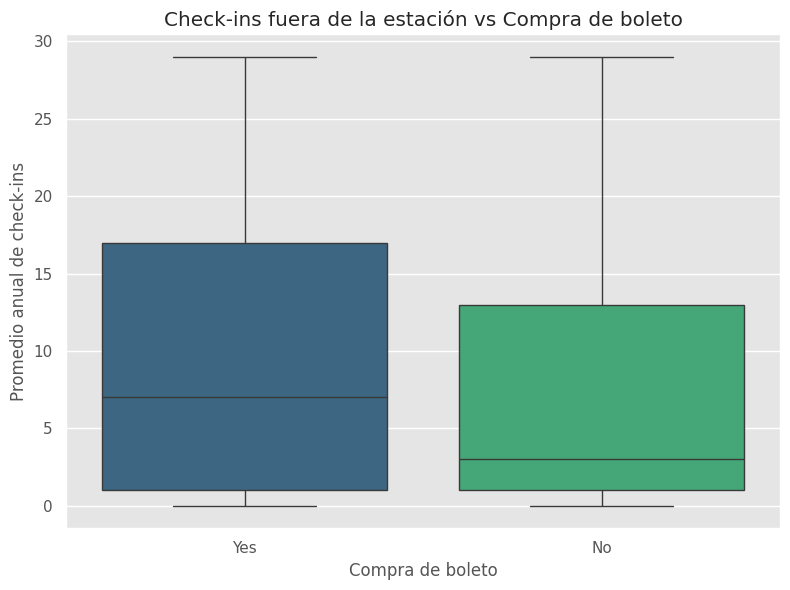

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',
    y='yearly_avg_Outstation_checkins',
    palette='viridis'
)
plt.title('Check-ins fuera de la estación vs Compra de boleto')
plt.xlabel('Compra de boleto')
plt.ylabel('Promedio anual de check-ins')
plt.tight_layout()
plt.show()

Se observa que la mediana de aquellos que sí comprarían un viaje el próximo mes es considerablemente mayor en comparación con los que no lo harían. Sin embargo, los boxplots muestran tamaños bastante similares entre ambos grupos.

### Relación entre 'week_since_last_outstation_checkin' y 'Taken_product'



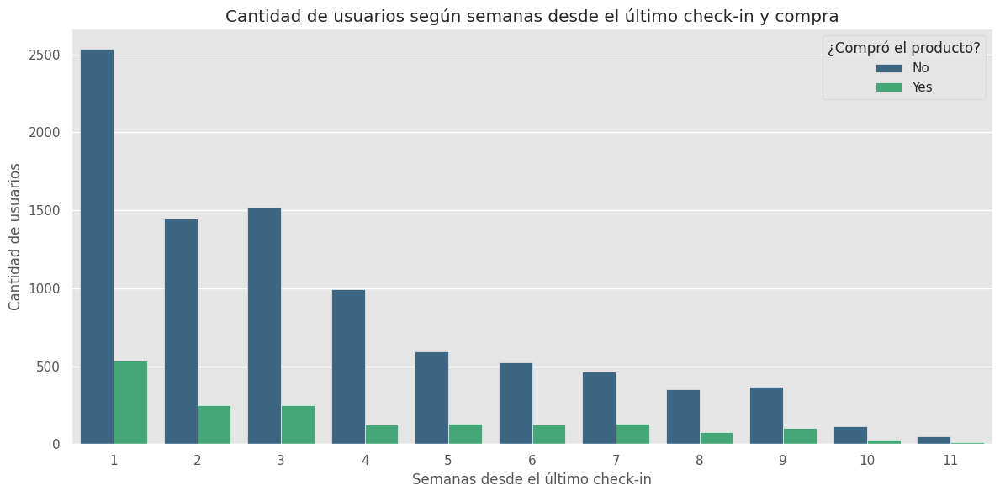

In [ ]:
plt.figure(figsize=(12,6))
sns.countplot(
    data=df_limpio[df_limpio['week_since_last_outstation_checkin'].between(1, 11)],
    x='week_since_last_outstation_checkin',
    hue='Taken_product',
    palette='viridis'
)
plt.title('Cantidad de usuarios según semanas desde el último check-in y compra')
plt.xlabel('Semanas desde el último check-in')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='¿Compró el producto?')
plt.tight_layout()
plt.show()

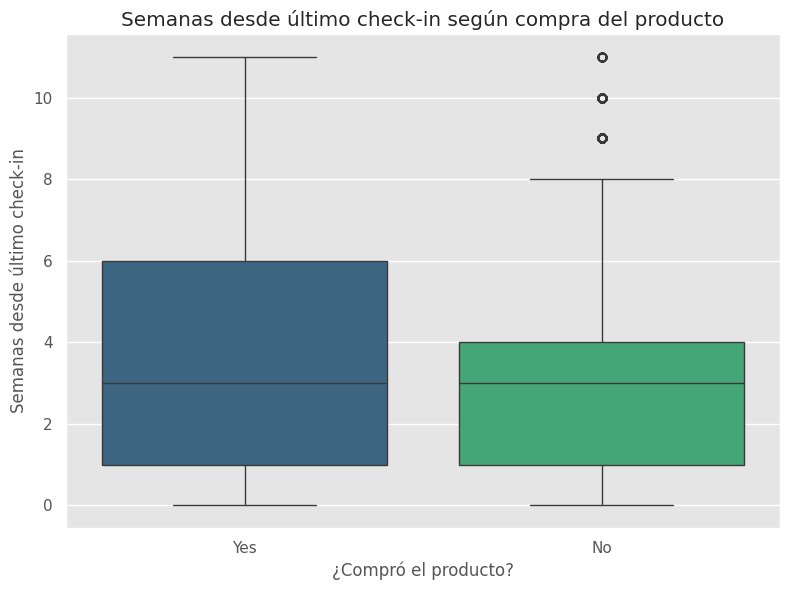

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(
    data=df_limpio,
    x='Taken_product',
    y='week_since_last_outstation_checkin',
    palette='viridis'
)
plt.title('Semanas desde último check-in según compra del producto')
plt.xlabel('¿Compró el producto?')
plt.ylabel('Semanas desde último check-in')
plt.tight_layout()
plt.show()

## Análisis básico de OLS.

En esta sección se realizará una regresión OLS básica con el objetivo de obtener una visión preliminar de los datos y explorar qué variables podrían ser útiles para análisis futuros o modelos predictivos. Cabe destacar que no se realizarán más gráficos y que no se verificará si el modelo puede continuar con un análisis más profundo; el propósito principal es simplemente ejecutar el análisis de regresión lineal para obtener una idea general de las relaciones entre las variables.

### Modelo 1 OLS

In [ ]:
Y = df_limpio['Taken_product'].map({'No': 0, 'Yes': 1}) # Convertir variable objetivo a numérica

X = df_limpio[['preferred_device',
               'working_flag',
               'Adult_flag',
               'Yearly_avg_view_on_travel_page',
               'Yearly_avg_comment_on_travel_page',
               'montly_avg_comment_on_company_page',
               'total_likes_on_outstation_checkin_given',
               'total_likes_on_outofstation_checkin_received',
               'yearly_avg_Outstation_checkins',
               'week_since_last_outstation_checkin',
               'travelling_network_rating',
               'preferred_location_type',
               'member_in_family',
               'following_company_page',
               'Daily_Avg_mins_spend_on_traveling_page']]


# Convertir variables categóricas en dummies (variables binarias)
# Primero identificar variables categóricas (tipo object o categorías)
cat_vars = ['preferred_device', 'preferred_location_type','working_flag']

X = pd.get_dummies(X, columns=cat_vars, drop_first=True)

# Agregar constante para intercepto
X = sm.add_constant(X)

Se observa el tipo de dato de las columnas.

In [ ]:
print(X.dtypes.unique())

[dtype('float64') dtype('int64') dtype('O') dtype('bool')]


Es necesario unificar las columnas a tipos de datos int64 o float64 para que el análisis de regresión funcione correctamente.

In [ ]:
bool_cols = X.select_dtypes(include=['bool']).columns
print(bool_cols)

Index(['preferred_device_Laptop', 'preferred_device_Mobile',
       'preferred_device_Others', 'preferred_device_Tab',
       'preferred_location_type_Big Cities',
       'preferred_location_type_Entertainment',
       'preferred_location_type_Financial', 'preferred_location_type_Game',
       'preferred_location_type_Hill Stations',
       'preferred_location_type_Historical site',
       'preferred_location_type_Medical', 'preferred_location_type_Movie',
       'preferred_location_type_No especificado',
       'preferred_location_type_OTT', 'preferred_location_type_Other',
       'preferred_location_type_Social media',
       'preferred_location_type_Tour Travel',
       'preferred_location_type_Trekking', 'working_flag_Yes'],
      dtype='object')


In [ ]:
# Convertir bool a int
bool_cols = X.select_dtypes(include=['bool']).columns
X[bool_cols] = X[bool_cols].astype(int)

# Confirmar tipos
print(X.dtypes.unique())

# Convertir object a dummies (ya lo hicimos, pero por si quedó algo)
obj_cols = X.select_dtypes(include=['object']).columns
if len(obj_cols) > 0:
    X = pd.get_dummies(X, columns=obj_cols, drop_first=True)

[dtype('float64') dtype('int64') dtype('O')]


In [ ]:
# Convertir bool a int
bool_cols = X.select_dtypes(include=['bool']).columns
X[bool_cols] = X[bool_cols].astype(int)

# Confirmar tipos
print(X.dtypes.unique())

# Convertir object a dummies (ya lo hicimos, pero por si quedó algo)
obj_cols = X.select_dtypes(include=['object']).columns
if len(obj_cols) > 0:
    X = pd.get_dummies(X, columns=obj_cols, drop_first=True)

[dtype('float64') dtype('int64')]


In [ ]:
# Confirmar tipos
print(X.dtypes.unique())

[dtype('float64') dtype('int64')]


In [ ]:
# Convertir columnas booleanas a enteros
bool_cols = X.select_dtypes(include=['bool']).columns
X[bool_cols] = X[bool_cols].astype(int)

# Verificar tipos
print(X.dtypes.unique())

[dtype('float64') dtype('int64')]


Con todas las columnas listas y los tipos de datos unificados, podemos proceder a realizar el análisis de regresión OLS.

In [ ]:
MiModelo = sm.OLS(Y, sm.add_constant(X))
Resultados = MiModelo.fit()
print(Resultados.summary())

                            OLS Regression Results                            
Dep. Variable:          Taken_product   R-squared:                       0.149
Model:                            OLS   Adj. R-squared:                  0.147
Method:                 Least Squares   F-statistic:                     64.14
Date:                Tue, 18 Nov 2025   Prob (F-statistic):               0.00
Time:                        00:42:55   Log-Likelihood:                -3973.8
No. Observations:               11759   AIC:                             8014.
Df Residuals:                   11726   BIC:                             8257.
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

En este modelo de OLS se observa que:


*   r-squared : 0.149 . Indica que el modelo explica el 14,9% de la variabilidad en la dependiente Taken_product, , lo que sugiere que hay un margen considerable de variación que no se captura en el modelo actual.

*   Prob (F-statistic) : 0.00 . Extremadamente bajo.

*   Ajuste para nuevo modelo: se procederá a construir un nuevo modelo utilizando únicamente las variables con un valor p < 0.05, lo que asegura que se consideren solo aquellas que tienen un impacto estadísticamente relevante.





### Modelo 2 OLS

Se realiza la prueba de Chi-cuadrado, la cual se emplea para evaluar la independencia de las variables categóricas. Este análisis nos permitirá identificar qué variables podrían ser relevantes para incluir en el segundo modelo de regresión OLS. A partir de los resultados de la prueba, seleccionaremos las variables más significativas para construir el modelo predictivo.

In [ ]:
def chi2_test(var1, var2):
    tabla = pd.crosstab(df_limpio[var1], df_limpio[var2])
    chi2, p, dof, expected = chi2_contingency(tabla)
    print(f"Chi2 entre {var1} y {var2}: {chi2:.3f}, p-valor: {p:.6f}")

variables = ['Adult_flag', 'working_flag', 'preferred_location_type', 'preferred_device']

# Hacemos el test para todos los pares únicos
for i in range(len(variables)):
    for j in range(i+1, len(variables)):
        chi2_test(variables[i], variables[j])

Chi2 entre Adult_flag y working_flag: 15.424, p-valor: 0.001488
Chi2 entre Adult_flag y preferred_location_type: 175.359, p-valor: 0.000000
Chi2 entre Adult_flag y preferred_device: 8.726, p-valor: 0.726147
Chi2 entre working_flag y preferred_location_type: 19.239, p-valor: 0.156016
Chi2 entre working_flag y preferred_device: 6.944, p-valor: 0.138897
Chi2 entre preferred_location_type y preferred_device: 9079.029, p-valor: 0.000000


Para este nuevo modelo también se sacan las variables que tienen el p mayor al 0.05.

In [ ]:
Y2 = df_limpio['Taken_product'].map({'No': 0, 'Yes': 1}) # Convertir variable objetivo a numérica

# Variables seleccionadas según el análisis previo
variables = [
    'Adult_flag',
    'Yearly_avg_view_on_travel_page',
    'total_likes_on_outstation_checkin_given',
    'total_likes_on_outofstation_checkin_received',
    'yearly_avg_Outstation_checkins',
    'week_since_last_outstation_checkin',
    'travelling_network_rating',
    'following_company_page',
    'Daily_Avg_mins_spend_on_traveling_page'

]

X2 = df_limpio[variables]
Y2 = df_limpio['Taken_product']

Observamos el tipo de datos que tenemos.

In [ ]:
print(X2.dtypes.unique())


[dtype('float64') dtype('int64') dtype('O')]


Es necesario unificar las columnas a tipos de datos int64 o float64 para que el análisis de regresión funcione correctamente.

In [ ]:
# Convertir bool a int
bool_cols = X2.select_dtypes(include=['bool']).columns
X2[bool_cols] = X2[bool_cols].astype(int)

# Convertir object a dummies (ya lo hicimos, pero por si quedó algo)
obj_cols = X2.select_dtypes(include=['object']).columns
if len(obj_cols) > 0:
    X2 = pd.get_dummies(X2, columns=obj_cols, drop_first=True)

# Confirmar tipos
print(X2.dtypes.unique())

[dtype('float64') dtype('int64') dtype('bool')]


In [ ]:
# Convertir columnas booleanas a enteros
bool_cols = X2.select_dtypes(include=['bool']).columns
X2[bool_cols] = X2[bool_cols].astype(int)

# Verificar tipos
print(X2.dtypes.unique())

[dtype('float64') dtype('int64')]


In [ ]:
X2_const = sm.add_constant(X2)

In [ ]:
# Si la variable objetivo tiene 'Yes' y 'No', convertir a 1 y 0
Y2_num = df_limpio['Taken_product'].map({'No':0, 'Yes':1})

# Confirmar
print(Y2_num.unique())
print(Y2_num.dtype)

[1 0]
int64


Con todas las columnas listas y los tipos de datos unificados, podemos proceder a realizar el análisis de regresión OLS.

In [ ]:
modelo2 = sm.OLS(Y2_num, X2_const)
resultados2 = modelo2.fit()
print(resultados2.summary())

                            OLS Regression Results                            
Dep. Variable:          Taken_product   R-squared:                       0.130
Model:                            OLS   Adj. R-squared:                  0.129
Method:                 Least Squares   F-statistic:                     175.6
Date:                Tue, 18 Nov 2025   Prob (F-statistic):               0.00
Time:                        00:42:55   Log-Likelihood:                -4103.3
No. Observations:               11759   AIC:                             8229.
Df Residuals:                   11748   BIC:                             8310.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

En este modelo de OLS se observa que:

r-squared : 0.13 . Indica que el modelo explica el 13% de la variabilidad en la dependiente Taken_product, , lo que sugiere que hay un margen considerable de variación que no se captura en el modelo actual.

Prob (F-statistic) : 0.00 . Extremadamente bajo.



# **Checkpoint 2**

In [ ]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11759 entries, 0 to 11759
Data columns (total 19 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   UserID                                        11759 non-null  int64   
 1   Taken_product                                 11759 non-null  object  
 2   Yearly_avg_view_on_travel_page                11759 non-null  float64 
 3   preferred_device                              11759 non-null  object  
 4   total_likes_on_outstation_checkin_given       11759 non-null  int64   
 5   yearly_avg_Outstation_checkins                11759 non-null  int64   
 6   member_in_family                              11759 non-null  int64   
 7   preferred_location_type                       11759 non-null  object  
 8   Yearly_avg_comment_on_travel_page             11759 non-null  int64   
 9   total_likes_on_outofstation_checkin_received  11759 non

En los dos modelos OLS presentados, se intentó identificar las variables que podrían explicar la probabilidad de que una persona compre un boleto de viaje (Taken_product). Sin embargo, aún no se ha verificado si los modelos cumplen con todos los supuestos necesarios para aplicar una regresión OLS de manera válida. Por lo tanto, aunque los resultados proporcionan información preliminar sobre la relación entre las variables, no se pueden extraer conclusiones definitivas sobre la precisión o la aplicabilidad de estos modelos en su totalidad. Dado que la variable dependiente es binaria (compra/no compra), la aplicación de un modelo OLS no resulta adecuada, ya que este tipo de regresión asume una variable continua como resultado.
En consecuencia, las estimaciones obtenidas presentan limitaciones importantes, como la posibilidad de generar probabilidades fuera del rango [0,1] y problemas de heterocedasticidad.

**Variables que utilizaremos en el nuevo Data Frame**


*   UserID                                          
 1   Taken_product                                  
 2   Yearly_avg_view_on_travel_page               
 3   preferred_device                               
 4   total_likes_on_outstation_checkin_given        
 5   yearly_avg_Outstation_checkins                  
 6   member_in_family                                 
 7   preferred_location_type                         
 8   Yearly_avg_comment_on_travel_page                
 9   total_likes_on_outofstation_checkin_received   
 10  week_since_last_outstation_checkin            
 11  following_company_page                        
 12  montly_avg_comment_on_company_page               
 13  working_flag                                  
 14  travelling_network_rating                      
 15  Adult_flag                                     
 16  Daily_Avg_mins_spend_on_traveling_page         



Se procede a eliminar las columnas rango_minutos y comentarios_categoria, ya que no forman parte de la base de datos original y fueron variables generadas por el equipo durante el análisis exploratorio de datos (EDA).

In [ ]:
df_nuevo = df_limpio.drop(['UserID','rango_minutos','comentarios_categoria'], axis=1)


En esta etapa, se utilizarán todas las variables restantes y la información que aportan para continuar con el desarrollo del análisis.

In [ ]:
df_nuevo

,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
0,Yes,307.0,Mobile,38570,1,2,Financial,94,5993,8,Yes,11,No,1,0.0,8
1,No,367.0,Mobile,9765,1,1,Financial,61,5130,1,No,23,Yes,4,1.0,10
2,Yes,277.0,Mobile,48055,1,2,Other,92,2090,6,Yes,15,No,2,0.0,7
3,No,247.0,Mobile,48720,1,4,Financial,56,2909,1,Yes,11,No,3,0.0,8
4,No,202.0,Mobile,20685,1,1,Medical,40,3468,9,No,12,No,4,1.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11755,No,279.0,Laptop,30987,23,2,Historical site,58,2616,4,No,36,No,3,1.0,23
11756,No,305.0,Tab,21510,6,1,Historical site,55,10041,4,No,30,No,1,1.0,11
11757,No,214.0,Tab,5478,4,3,Beach,103,6203,3,Yes,40,Yes,2,1.0,12
11758,No,382.0,Laptop,35851,2,3,Historical site,83,5444,3,No,32,No,4,0.0,20


In [ ]:
df_nuevo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11759 entries, 0 to 11759
Data columns (total 16 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Taken_product                                 11759 non-null  object 
 1   Yearly_avg_view_on_travel_page                11759 non-null  float64
 2   preferred_device                              11759 non-null  object 
 3   total_likes_on_outstation_checkin_given       11759 non-null  int64  
 4   yearly_avg_Outstation_checkins                11759 non-null  int64  
 5   member_in_family                              11759 non-null  int64  
 6   preferred_location_type                       11759 non-null  object 
 7   Yearly_avg_comment_on_travel_page             11759 non-null  int64  
 8   total_likes_on_outofstation_checkin_received  11759 non-null  int64  
 9   week_since_last_outstation_checkin            11759 non-null  int6

Se constató que los datos habían sido depurados y no presentaban inconsistencias. A partir de esta validación, se identificaron las variables de tipo object, las cuales fueron transformadas en variables dummy con el propósito de preparar los datos para su procesamiento en modelos estadísticos.

### Reporte inicial

Con el objetivo de verificar la consistencia de los datos y respaldar los resultados obtenidos, caracteristicas generales de la información se elaboró un reporte de Análisis Exploratorio de Datos (EDA) que permitió constatar los resultados derivados de nuestro propio trabajo de depuración y estandarización.

In [ ]:
ProfileReport(df_nuevo, title="Reporte EDA")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 16/16 [00:00<00:00, 38.77it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Observamos datos estadísticos relevantes para cada una de las variables de df_nuevo.

In [ ]:
df_nuevo.describe()

,Yearly_avg_view_on_travel_page,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,montly_avg_comment_on_company_page,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
count,11759.000000,11759.000000,11759.000000,11759.000000,11759.000000,11759.000000,11759.000000,11759.000000,11759.000000,11759.000000,11759.000000
mean,266.960711,27259.678289,8.169827,2.921422,73.482014,6531.897951,3.203844,28.662982,2.712135,0.793945,13.817757
std,90.132497,15002.741027,8.669548,1.044893,25.757452,4706.764507,2.616309,48.662330,1.080868,0.851828,9.070974
min,0.000000,0.000000,0.000000,1.000000,0.000000,1009.000000,0.000000,11.000000,1.000000,0.000000,0.000000
25%,225.000000,15114.500000,1.000000,2.000000,56.000000,2940.500000,1.000000,17.000000,2.000000,0.000000,8.000000
50%,267.000000,27104.000000,4.000000,3.000000,74.000000,4948.000000,3.000000,22.000000,3.000000,1.000000,12.000000
75%,322.000000,40115.500000,14.000000,4.000000,92.000000,8393.500000,5.000000,27.000000,4.000000,1.000000,18.000000
max,464.000000,252430.000000,29.000000,10.000000,815.000000,20065.000000,11.000000,500.000000,4.000000,3.000000,270.000000


## División y preparación de la base de datos.

Dado que la variable dependiente es binaria (compra/no compra), se opta por la utilización de un modelo de regresión logística para la predicción de la variable objetivo. Este enfoque resulta adecuado, ya que permite estimar la probabilidad de ocurrencia de un evento en función de las variables explicativas, asegurando que las predicciones se mantengan dentro del rango [0,1].

La base de datos se dividió en conjuntos de entrenamiento y testeo con el fin de ajustar el modelo y evaluar su desempeño en datos no vistos.

In [ ]:
# se crea una base para las variables predictoras  X  y otra para la respuesta dicotómica y
X = df_nuevo.drop(columns=['Taken_product']) #features variables clasificadoras
X_names=X.columns.tolist()
y=df_nuevo.Taken_product # target o grupo


X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

pd.value_counts(df_nuevo['Taken_product'])

,count
Taken_product,
No,9863
Yes,1896


Se procedió a transformar las columnas correspondientes a variables de tipo object en variables dummy, con el fin de habilitar su uso en el modelo.

In [ ]:
pd.value_counts(df_limpio['preferred_device'])


,count
preferred_device,
Mobile,6422
Tab,4172
Laptop,1108
Desconocido,53
Others,4


In [ ]:
df_nuevo = pd.concat(
    [df_nuevo.drop(columns=['preferred_device']),
     pd.get_dummies(df_nuevo['preferred_device'], prefix='preferred_device', drop_first=False)],
    axis=1
)

print(df_nuevo.head())


  Taken_product  Yearly_avg_view_on_travel_page  \
0           Yes                           307.0   
1            No                           367.0   
2           Yes                           277.0   
3            No                           247.0   
4            No                           202.0   

   total_likes_on_outstation_checkin_given  yearly_avg_Outstation_checkins  \
0                                    38570                               1   
1                                     9765                               1   
2                                    48055                               1   
3                                    48720                               1   
4                                    20685                               1   

   member_in_family preferred_location_type  \
0                 2               Financial   
1                 1               Financial   
2                 2                   Other   
3                 4               Fi

In [ ]:
pd.value_counts(df_limpio['preferred_location_type'])


,count
preferred_location_type,
Beach,2424
Financial,2408
Historical site,1856
Medical,1845
Other,643
Big Cities,636
Social media,633
Trekking,528
Entertainment,516


In [ ]:
df_nuevo = pd.concat(
    [df_nuevo.drop(columns=['preferred_location_type']),
     pd.get_dummies(df_nuevo['preferred_location_type'], prefix='preferred_location_type', drop_first=False)],
    axis=1
)

print(df_nuevo.head())

  Taken_product  Yearly_avg_view_on_travel_page  \
0           Yes                           307.0   
1            No                           367.0   
2           Yes                           277.0   
3            No                           247.0   
4            No                           202.0   

   total_likes_on_outstation_checkin_given  yearly_avg_Outstation_checkins  \
0                                    38570                               1   
1                                     9765                               1   
2                                    48055                               1   
3                                    48720                               1   
4                                    20685                               1   

   member_in_family  Yearly_avg_comment_on_travel_page  \
0                 2                                 94   
1                 1                                 61   
2                 2                               

In [ ]:
pd.value_counts(df_limpio['following_company_page'])

,count
following_company_page,
No,8355
Yes,3284
Desconocido,120


In [ ]:
df_nuevo = pd.concat(
    [df_nuevo.drop(columns=['following_company_page']),
     pd.get_dummies(df_nuevo['following_company_page'], prefix='following_company_page', drop_first=False)],
    axis=1
)

print(df_nuevo.head())

  Taken_product  Yearly_avg_view_on_travel_page  \
0           Yes                           307.0   
1            No                           367.0   
2           Yes                           277.0   
3            No                           247.0   
4            No                           202.0   

   total_likes_on_outstation_checkin_given  yearly_avg_Outstation_checkins  \
0                                    38570                               1   
1                                     9765                               1   
2                                    48055                               1   
3                                    48720                               1   
4                                    20685                               1   

   member_in_family  Yearly_avg_comment_on_travel_page  \
0                 2                                 94   
1                 1                                 61   
2                 2                               

In [ ]:
pd.value_counts(df_limpio['working_flag'])

,count
working_flag,
No,9951
Yes,1808


In [ ]:
df_nuevo = pd.concat(
    [df_nuevo.drop(columns=['working_flag']),
     pd.get_dummies(df_nuevo['working_flag'], prefix='working_flag', drop_first=False)],
    axis=1
)

print(df_nuevo.head())

  Taken_product  Yearly_avg_view_on_travel_page  \
0           Yes                           307.0   
1            No                           367.0   
2           Yes                           277.0   
3            No                           247.0   
4            No                           202.0   

   total_likes_on_outstation_checkin_given  yearly_avg_Outstation_checkins  \
0                                    38570                               1   
1                                     9765                               1   
2                                    48055                               1   
3                                    48720                               1   
4                                    20685                               1   

   member_in_family  Yearly_avg_comment_on_travel_page  \
0                 2                                 94   
1                 1                                 61   
2                 2                               

In [ ]:
df_nuevo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11759 entries, 0 to 11759
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Taken_product                                 11759 non-null  object 
 1   Yearly_avg_view_on_travel_page                11759 non-null  float64
 2   total_likes_on_outstation_checkin_given       11759 non-null  int64  
 3   yearly_avg_Outstation_checkins                11759 non-null  int64  
 4   member_in_family                              11759 non-null  int64  
 5   Yearly_avg_comment_on_travel_page             11759 non-null  int64  
 6   total_likes_on_outofstation_checkin_received  11759 non-null  int64  
 7   week_since_last_outstation_checkin            11759 non-null  int64  
 8   montly_avg_comment_on_company_page            11759 non-null  int64  
 9   travelling_network_rating                     11759 non-null  int6

In [ ]:
bool_cols = df_nuevo.select_dtypes('bool').columns
df_nuevo[bool_cols] = df_nuevo[bool_cols].astype(int)


In [ ]:
df_nuevo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11759 entries, 0 to 11759
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Taken_product                                 11759 non-null  object 
 1   Yearly_avg_view_on_travel_page                11759 non-null  float64
 2   total_likes_on_outstation_checkin_given       11759 non-null  int64  
 3   yearly_avg_Outstation_checkins                11759 non-null  int64  
 4   member_in_family                              11759 non-null  int64  
 5   Yearly_avg_comment_on_travel_page             11759 non-null  int64  
 6   total_likes_on_outofstation_checkin_received  11759 non-null  int64  
 7   week_since_last_outstation_checkin            11759 non-null  int64  
 8   montly_avg_comment_on_company_page            11759 non-null  int64  
 9   travelling_network_rating                     11759 non-null  int6

## Modelo de Regresión logística

Se creó un modelo de regresión logística utilizando la librería scikit-learn. Para abordar el desbalance en la variable dependiente —donde la categoría "no compra" presenta una frecuencia significativamente mayor que la categoría "compra"— se incorporó el argumento class_weight='balanced'. Este ajuste permite asignar mayor peso a los ejemplos de la clase minoritaria, contribuyendo a equilibrar la influencia de ambas clases en el proceso de entrenamiento del modelo.

In [ ]:
X_train.select_dtypes(include='object').columns

Index(['preferred_device', 'preferred_location_type', 'following_company_page',
       'working_flag'],
      dtype='object')

In [ ]:
# Dummificar directamente X_train y X_test actuales
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

# Alinear columnas para evitar desajustes
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)


In [ ]:
logr=LogisticRegression(class_weight='balanced')
logr.fit(X_train,y_train)

LogisticRegression(class_weight='balanced')

Se evalúa el desempeño del modelo de regresión logística sobre la muestra de prueba, generando las predicciones, mostrando la matriz de confusión y calculando el accuracy, lo que permite medir la proporción de aciertos del modelo.

In [ ]:
y_pred_logr = logr.predict(X_test)


print('--------------------')
print('Tabla de confusión')
print('-------------------')
CM = confusion_matrix(y_test,y_pred_logr)  # Matriz de confusión
print(CM)
print('--------------------')
print('Reporte de medidas de desempeño')
print('-------------------')
print('accuracy: ', accuracy_score(y_test,y_pred_logr))

--------------------
Tabla de confusión
-------------------
[[1196  777]
 [ 148  231]]
--------------------
Reporte de medidas de desempeño
-------------------
accuracy:  0.60671768707483


El modelo de regresión logística muestra un buen nivel de acierto en la predicción de los casos de “no compra” (TN = 1196), aunque también presenta un número elevado de falsos positivos (FP = 777). En cuanto a los compradores reales, el desempeño es más limitado, con 231 verdaderos positivos (TP) frente a 148 falsos negativos (FN). Estos resultados indican que el modelo tiende a clasificar con mayor frecuencia la categoría “no compra”, lo cual resulta coherente dado que se trata de la clase mayoritaria. En términos globales, el modelo alcanzó un accuracy cercano al 60 % en la muestra de prueba, lo que brinda una primera aproximación a su desempeño. Sin embargo, debido al desbalance en la variable dependiente, el accuracy por sí solo no constituye una métrica suficiente, por lo que resulta más adecuado evaluar indicadores complementarios como precision, recall y F1-score.

Con el fin de optimizar el desempeño del modelo de regresión logística, se implementa una búsqueda de los mejores hiperparámetros (C y solver) mediante GridSearchCV con validación cruzada. Para este procedimiento, los datos se estandarizan previamente dentro de un pipeline, y se utiliza el F1-score como métrica de evaluación, dado que la base de datos presenta clases desbalanceadas (mientras que GridSearchCV por defecto optimiza el accuracy). El resultado esperado es la obtención de la combinación de parámetros que maximice el F1-score promedio.

In [ ]:
# en este caso proponemos una búsqueda de la mejor estimación del modelo logístico armando una grilla de parámetros
# definimos en solver distintos métodos de estimación posibles de la logística que permite la función LogisticRegression  del paquete sklearn.linear
solver = ['liblinear', 'newton-cg', 'lbfgs', 'sag', 'saga']
# y en C se definen parámetros de regularización que aceleran el proceso de estimación (a medida que son más grandes) en este caso se proponen un vector de valores
# aleatorios espaciados según una escala logarítmica ( podrían haberse seleccionado en forma uniforme que son los nros aleatorios que se conocen comunmente).
C = np.logspace(-2, 10, 13)
# definimos el modelo a estimar LogisticRegression previo estandarizar los datos con StandardScaler
pipe_lr = Pipeline([('sc', StandardScaler()),
    ('LR', LogisticRegression(class_weight='balanced'))
    ])
# definimos los vectores de parámetros para hacer las estimaciones
params_lr = {
    'LR__C': C,
    'LR__solver': solver
    }
# proponemos la busqueda del mejor modelo según el resultado del mejor F1-score con la tasa crosvalidada (GridSearchCV)
search_lr = GridSearchCV(estimator=pipe_lr,
                      param_grid=params_lr,
                      cv = 5,
                      scoring = 'f1',
                      return_train_score=True)

search_lr.fit(X_train, y_train)
print(f" Best score is: {search_lr.best_score_} with parameters: {search_lr.best_params_}")

 Best score is: nan with parameters: {'LR__C': np.float64(0.01), 'LR__solver': 'liblinear'}


Para optimizar el desempeño del modelo de regresión logística, se realizó inicialmente una búsqueda de hiperparámetros (C y solver) mediante GridSearchCV con validación cruzada, utilizando un pipeline que estandariza los datos. Se consideró F1-score como métrica debido al desbalance de clases, pero esta elección provocaba problemas de convergencia y generaba resultados NaN. Por este motivo, se optó posteriormente por utilizar accuracy, lo que permitió completar la búsqueda de manera estable. El objetivo fue identificar la combinación de parámetros que proporcione el mejor desempeño general del modelo.

In [ ]:
# en este caso proponemos una búsqueda de la mejor estimación del modelo logístico armando una grilla de parámetros
# definimos en solver distintos métodos de estimación posibles de la logística que permite la función LogisticRegression  del paquete sklearn.linear
solver = ['liblinear', 'newton-cg', 'lbfgs', 'sag', 'saga']
# y en C se definen parámetros de regularización que aceleran el proceso de estimación (a medida que son más grandes) en este caso se proponen un vector de valores
# aleatorios espaciados según una escala logarítmica ( podrían haberse seleccionado en forma uniforme que son los nros aleatorios que se conocen comunmente).
C = np.logspace(-2, 10, 13)
# definimos el modelo a estimar LogisticRegression previo estandarizar los datos con StandardScaler
pipe_lr = Pipeline([('sc', StandardScaler()),
    ('LR', LogisticRegression(class_weight='balanced'))
    ])
# definimos los vectores de parámetros para hacer las estimaciones
params_lr = {
    'LR__C': C,
    'LR__solver': solver
    }
# proponemos la busqueda del mejor modelo según el resultado del mejor F1-score con la tasa crosvalidada (GridSearchCV)
search_lr = GridSearchCV(estimator=pipe_lr,
                      param_grid=params_lr,
                      cv = 5,
                      scoring = 'accuracy',
                      return_train_score=True)

search_lr.fit(X_train, y_train)
print(f" Best score is: {search_lr.best_score_} with parameters: {search_lr.best_params_}")

 Best score is: 0.7119178247037747 with parameters: {'LR__C': np.float64(0.01), 'LR__solver': 'newton-cg'}


Una vez completada la búsqueda de hiperparámetros, los valores seleccionados fueron C = 0.01, correspondiente al parámetro de regularización, y solver = 'newton-cg', que define el algoritmo utilizado para la optimización de los coeficientes de la regresión logística. Con estos valores, que maximizan el desempeño del modelo según el GridSearchCV, se procedió a ajustar la regresión logística final y a generar las predicciones sobre la muestra de prueba.

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=0.01, solver ='newton-cg' )
lr.fit(X_train,y_train)
y_pred_lr = lr.predict(X_test)

Con la muestra de testeo, se calcula la matriz de confusión y se obtienen las principales medidas de desempeño del modelo.

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
print('--------------------')
print('Tabla de confusión')
print('-------------------')
CM = confusion_matrix(y_test,y_pred_lr)  # Matriz de confusión
print(CM)
print('--------------------')
print('Reporte de medidas de desempeño')
print('-------------------')
print(classification_report(y_test,y_pred_lr, digits = 2))
print('accuracy: ', accuracy_score(y_test,y_pred_lr))

--------------------
Tabla de confusión
-------------------
[[1956   17]
 [ 337   42]]
--------------------
Reporte de medidas de desempeño
-------------------
              precision    recall  f1-score   support

          No       0.85      0.99      0.92      1973
         Yes       0.71      0.11      0.19       379

    accuracy                           0.85      2352
   macro avg       0.78      0.55      0.55      2352
weighted avg       0.83      0.85      0.80      2352

accuracy:  0.8494897959183674


Con los hiperparámetros optimizados, el modelo de regresión logística alcanzó un accuracy de 0,85, resultado que se explica principalmente porque logra predecir correctamente la mayoría de los casos de “No compra”, aunque presenta un desempeño mucho más limitado en la clase “Sí compra”. Cabe señalar que el accuracy refleja el rendimiento global del modelo, pero no permite evaluar con precisión cómo se comporta frente a la clase minoritaria en una base de datos desbalanceada.

Por esta razón, además del accuracy, resulta fundamental analizar métricas adicionales como precision, recall y F1-score, que brindan una visión más completa del desempeño por clase:

Recall: de todos los casos que realmente corresponden a “Sí compra”, solo el 11 % fueron correctamente identificados por el modelo, lo que refleja un nivel de sensibilidad muy bajo.

Precision: la proporción de predicciones positivas que fueron correctas alcanzó el 71 %, indicando que cuando el modelo predice un “Sí compra”, suele tener un alto grado de acierto.

F1-score: dado que combina precision y recall y es especialmente útil en escenarios con clases desbalanceadas, se obtuvo un valor muy bajo de 0,19 para la clase “Sí compra”. Esto evidencia que, a pesar de la alta precision, el bajo recall impide que el modelo capture correctamente una proporción significativa de los casos positivos.

En síntesis, el modelo muestra un desempeño sólido en la clase mayoritaria (“No compra”), pero falla al generalizar en la clase minoritaria, lo que limita su utilidad práctica en la predicción de compradores reales.

**Visualización de la Matriz de Confusión**

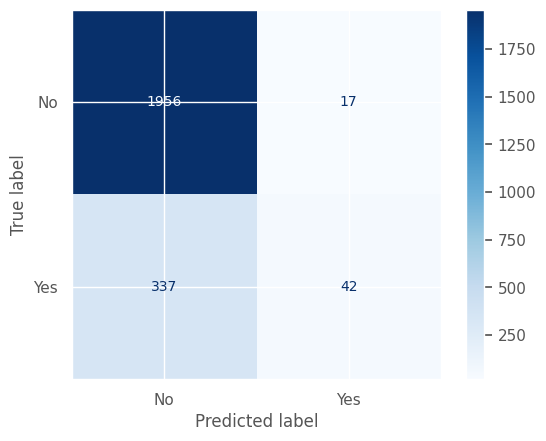

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_lr, display_labels=['No', 'Yes'], cmap = 'Blues')
plt.show()

**Visualización de la Matriz de Confusión Normalizada**

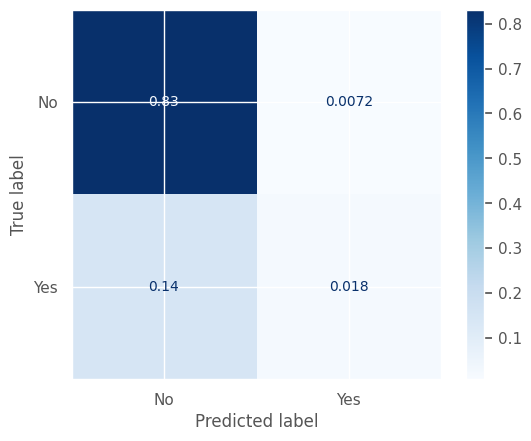

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_lr, display_labels=['No', 'Yes'],normalize='all',cmap='Blues')
plt.show()

Curva ROC

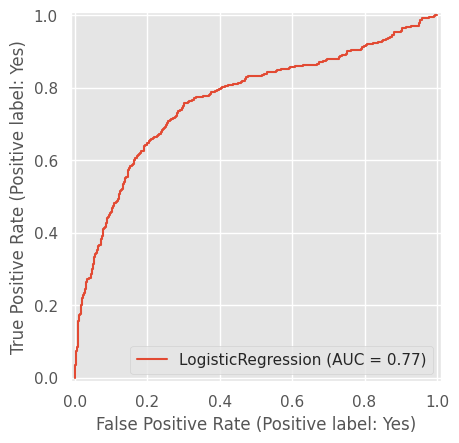

In [ ]:
from sklearn.metrics import RocCurveDisplay
log_cor_est = RocCurveDisplay.from_estimator(lr,X_test, y_test, response_method ='decision_function')
plt.show()

La curva ROC evalúa la capacidad del modelo para diferenciar entre clases. En este caso, el área bajo la curva (AUC) es de 0,77, lo que indica que el modelo tiene un 77 % de probabilidad de asignar un puntaje mayor a la clase Yes que a la clase No.

Es decir, el modelo logra diferenciar en parte entre compradores y no compradores cuando trabaja con probabilidades, lo que muestra cierto potencial. Sin embargo, el desempeño práctico es pobre (F1 = 0,10 para la clase “Yes”). Por eso, el AUC debe interpretarse en conjunto con métricas como precision, recall y F1, ya que por sí solo no garantiza buenos resultados en la predicción final.

## Modelo de Regresión logística balanceado

En este caso, la variable objetivo (Taken_product) tiene clases desbalanceadas (“Yes” es minoritaria frente a “No”), lo que dificulta que el modelo prediga correctamente la clase positiva. Para reducir este sesgo, se balanceó el conjunto de datos, mejorando la capacidad de aprender de ambas clases y evitando métricas engañosas.

In [ ]:
# MODELO INCORPORANDO PESO DE LAS CLASES

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score, accuracy_score, f1_score, precision_score, recall_score  # métricas para evaluar


model_LR = LogisticRegression( C=0.01, solver='newton-cg', class_weight = 'balanced')
model_LR.fit(X_train,y_train)
y_pred_model_LR = model_LR.predict(X_test)

print('--------------------')
print('Tabla de confusión')
print('-------------------')
CM = confusion_matrix(y_test,y_pred_model_LR)  # Matriz de confusión
print(CM)
print('--------------------')
print('Reporte de medidas de desempeño')
print('-------------------')
print(classification_report(y_test,y_pred_model_LR, digits = 2))
print('accuracy: ', accuracy_score(y_test,y_pred_model_LR))

--------------------
Tabla de confusión
-------------------
[[1442  531]
 [ 120  259]]
--------------------
Reporte de medidas de desempeño
-------------------
              precision    recall  f1-score   support

          No       0.92      0.73      0.82      1973
         Yes       0.33      0.68      0.44       379

    accuracy                           0.72      2352
   macro avg       0.63      0.71      0.63      2352
weighted avg       0.83      0.72      0.76      2352

accuracy:  0.7232142857142857




*  La matriz de confusión indica el desempeño del modelo de la siguiente manera:

True Negatives (1442): casos correctamente clasificados como no.

False Positives (531): casos incorrectamente clasificados como sí cuando en realidad eran no.

False Negatives (120): casos incorrectamente clasificados como no cuando en realidad eran sí.

True Positives (259): casos correctamente clasificados como sí.


*   Precision:

No → 0.92: De todas las veces que el modelo predijo “No”, el 92% fueron correctas.

Yes → 0.33: De todas las veces que predijo “Yes”, solo el 32% fueron correctas.

*   Recall

No → 0.73: El modelo detectó correctamente el 74% de los No reales.

Yes → 0.68: El modelo detectó correctamente el 66% de los Yes reales.

*   F1 Score

No → 0.82

Yes → 0.44: Indica que el modelo tiene dificultades para predecir la clase minoritaria.


**Visualización de la Matriz de Confusión**

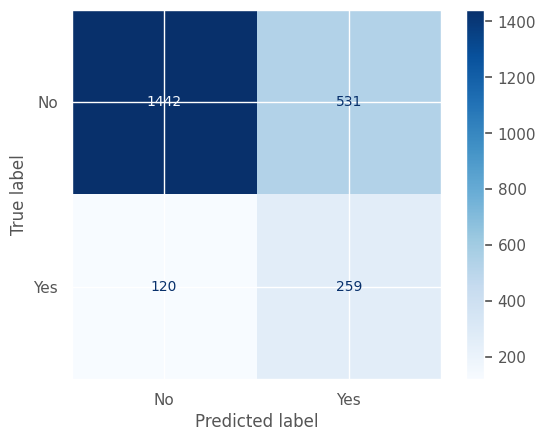

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_model_LR, display_labels=['No', 'Yes'], cmap='Blues')
plt.show()

**Visualización de la Curva ROC**

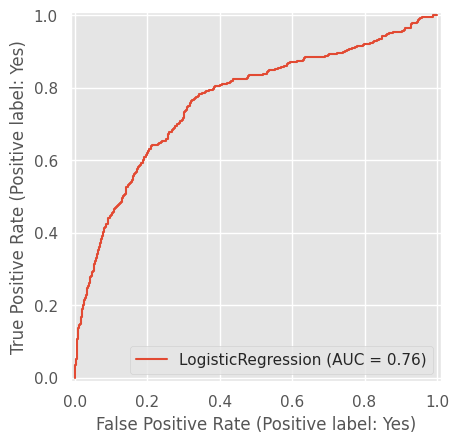

In [ ]:
log_cor_est = RocCurveDisplay.from_estimator(model_LR, X_test , y_test, response_method ='decision_function')
plt.show()

Tras el balanceo de las clases, el AUC se mantuvo en valores similares, lo cual resulta esperado, dado que esta métrica refleja la capacidad de discriminación global del modelo. No obstante, el efecto del balanceo se observa con mayor claridad en métricas como recall y F1-score, las cuales mejoran la detección de la clase minoritaria.

## Evaluación del desempeño y diagnóstico del modelo

Con el objetivo de analizar el comportamiento del modelo y detectar posibles problemas de overfitting o underfitting, se evaluó su desempeño tanto sobre el conjunto de entrenamiento como sobre el conjunto de test.

Comparar las métricas en ambos conjuntos permite identificar si el modelo está aprendiendo patrones genuinos de los datos o si, por el contrario, se está ajustando demasiado a los ejemplos de entrenamiento (overfitting) o no logra capturar la complejidad del problema (underfitting). ersión más técnica y concisa

Para evaluar la capacidad de generalización del modelo, se calcularon las métricas de desempeño en los conjuntos de entrenamiento y de test. Esto permite detectar si el modelo presenta overfitting (alto rendimiento en train y bajo en test) o underfitting (bajo rendimiento en ambos).

In [ ]:
# Predicciones en train y test
y_pred_train_model_LR = model_LR.predict(X_train)
y_pred_test_model_LR = model_LR.predict(X_test)

y_pred_test_lr = lr.predict(X_test)
y_pred_train_lr = lr.predict(X_train)

In [ ]:
from sklearn.metrics import f1_score

# métricas

f1_train_lr = f1_score(y_train, y_pred_train_lr, pos_label='Yes')
f1_test_lr  = f1_score(y_test, y_pred_test_lr, pos_label='Yes')

print(f"F1 Train: {f1_train_lr:.3f}")
print(f"F1 Test:  {f1_test_lr:.3f}")

F1 Train: 0.255
F1 Test:  0.192


In [ ]:
f1_train_LR= f1_score(y_train,y_pred_train_model_LR , pos_label='Yes')
f1_test_LR= f1_score(y_test, y_pred_test_model_LR , pos_label='Yes')

print(f"F1 Train: {f1_train_LR:.3f}")
print(f"F1 Test:  {f1_test_LR:.3f}")

F1 Train: 0.449
F1 Test:  0.443


Los dos metricas f1 para train y para test dan bajas, entonces se trata de underfitting. El modelo no aprende lo suficiente para generalizar.
Apesar de que los f1 de los modelos con mejores hiperparámetros son de mayor magnitud, siguen siendo valores bajos. Lo cual nos dice que el modelo sigue aprendiendo poco es decir nos seguimos encontrando con un caso de underfitting

## Conclusión.

El modelo presenta un desempeño desigual entre las clases debido a la naturaleza minoritaria de la variable objetivo (Yes). La matriz de confusión y las métricas derivadas indican que se clasifican correctamente la mayoría de los casos negativos (No), con una precisión del 92 % y un recall del 73 %, mientras que la clase positiva (Yes) muestra una menor precisión (33 %) y un recall del 68 %, evidenciando dificultades para predecir correctamente la clase minoritaria. El F1-score para Yes (0,44) confirma esta limitación. Por su parte, la curva ROC, con un área bajo la curva (AUC) de 0,76, refleja que el modelo tiene un 76 % de probabilidad de asignar un puntaje mayor a los casos positivos que a los negativos, mostrando una capacidad moderada para diferenciar entre clases.
En conjunto, estos resultados sugieren que, aunque el modelo resulta útil para identificar la clase mayoritaria, la implementación de estrategias adicionales de balanceo o ajuste podría mejorar la predicción de la clase minoritaria.
En la próxima entrega, con las nuevas funcionalidades que se están incorporando, se espera alcanzar un desempeño superior del modelo.

# Checkpoint 3

Hasta aquí se ha abordado el análisis de los datos de manera amplia, queda aún por considerar la comparación del modelo balanceado con un modelo baseline.    

## Modelo Baseline

Este modelo no busca aprender patrones, sino que predice únicamente la clase más frecuente del conjunto de entrenamiento. De esta manera, es posible evaluar si los modelos posteriores aportan una mejora real frente a una predicción aleatoria o trivial.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)


In [ ]:
print("Resultados del modelo baseline:")
print(classification_report(y_test, y_pred_dummy))
print("Matriz de confusión:\n", confusion_matrix(y_test, y_pred_dummy))
print('')

print("Resultados del modelo de Regresión Logística balanceado:")
print(classification_report(y_test, y_pred_model_LR))
print("Matriz de confusión Reg. Logistica Balanceado:\n", confusion_matrix(y_test, y_pred_model_LR))

Resultados del modelo baseline:
              precision    recall  f1-score   support

          No       0.84      1.00      0.91      1973
         Yes       0.00      0.00      0.00       379

    accuracy                           0.84      2352
   macro avg       0.42      0.50      0.46      2352
weighted avg       0.70      0.84      0.77      2352

Matriz de confusión:
 [[1973    0]
 [ 379    0]]

Resultados del modelo de Regresión Logística balanceado:
              precision    recall  f1-score   support

          No       0.92      0.73      0.82      1973
         Yes       0.33      0.68      0.44       379

    accuracy                           0.72      2352
   macro avg       0.63      0.71      0.63      2352
weighted avg       0.83      0.72      0.76      2352

Matriz de confusión Reg. Logistica Balanceado:
 [[1442  531]
 [ 120  259]]


Primero se entrenó un modelo baseline, que simplemente predice siempre la clase más frecuente del conjunto de entrenamiento (“No”). Como era de esperar, este modelo alcanza un accuracy del 84%, pero no identifica ningún comprador potencial (recall de “Yes” = 0). La matriz de confusión confirma que todos los casos “Yes” son clasificados como “No”. Esto sirve como punto de referencia: cualquier modelo que no mejore la detección de la clase minoritaria no aporta información útil para el negocio.
El modelo de regresión logística balanceado, alcanza un accuracy del 72%  lo cual indica que en realidad, está prediciendo peor que el modelo baseline.



El objetivo principal del análisis es predecir las ventas de boletos del próximo mes, con el fin de optimizar la gestión de los recursos económicos, humanos y de marketing orientados a los clientes potenciales. Dada la naturaleza del negocio, los falsos positivos representan un costo más elevado, ya que implican destinar recursos a clientes que finalmente no concretarán la compra. Por este motivo, en este caso se prioriza la métrica Precision.


## Árboles de Decisión

Se entrena un modelo de árbol de decisión aplicando balance de clases, debido al desbalance existente en la distribución de la variable objetivo.

In [ ]:
clf = DecisionTreeClassifier(max_depth=None, class_weight='balanced', random_state=0)
clf.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=0)

In [ ]:
y_train_pred_ad = clf.predict(X_train)
y_test_pred_ad = clf.predict(X_test)

train_f1_ad = f1_score(y_train, y_train_pred_ad, pos_label='Yes')
test_f1_ad = f1_score(y_test, y_test_pred_ad, pos_label='Yes')

print(f'Train F1-score: {train_f1_ad:.3f}')
print(f'Test F1-score: {test_f1_ad:.3f}')

Train F1-score: 1.000
Test F1-score: 0.918


Se evalúa la profundidad máxima (max_depth) del árbol de decisión para identificar el valor que optimiza el rendimiento del modelo.

max_depth=2, train_f1: 0.39221, test_f1: 0.36066
max_depth=3, train_f1: 0.46977, test_f1: 0.44824
max_depth=4, train_f1: 0.48314, test_f1: 0.46615
max_depth=5, train_f1: 0.52937, test_f1: 0.50596
max_depth=6, train_f1: 0.57892, test_f1: 0.54956
max_depth=7, train_f1: 0.61706, test_f1: 0.56387
max_depth=8, train_f1: 0.65756, test_f1: 0.61993
max_depth=9, train_f1: 0.75119, test_f1: 0.69207
max_depth=10, train_f1: 0.76887, test_f1: 0.71933
max_depth=11, train_f1: 0.86809, test_f1: 0.80046
max_depth=12, train_f1: 0.89344, test_f1: 0.82800
max_depth=13, train_f1: 0.93395, test_f1: 0.86783
max_depth=14, train_f1: 0.95367, test_f1: 0.87929
max_depth=15, train_f1: 0.97647, test_f1: 0.89433
max_depth=16, train_f1: 0.98989, test_f1: 0.91821
max_depth=17, train_f1: 0.99770, test_f1: 0.91700
max_depth=18, train_f1: 0.99967, test_f1: 0.91777
max_depth=19, train_f1: 1.00000, test_f1: 0.91777
max_depth=20, train_f1: 1.00000, test_f1: 0.91777


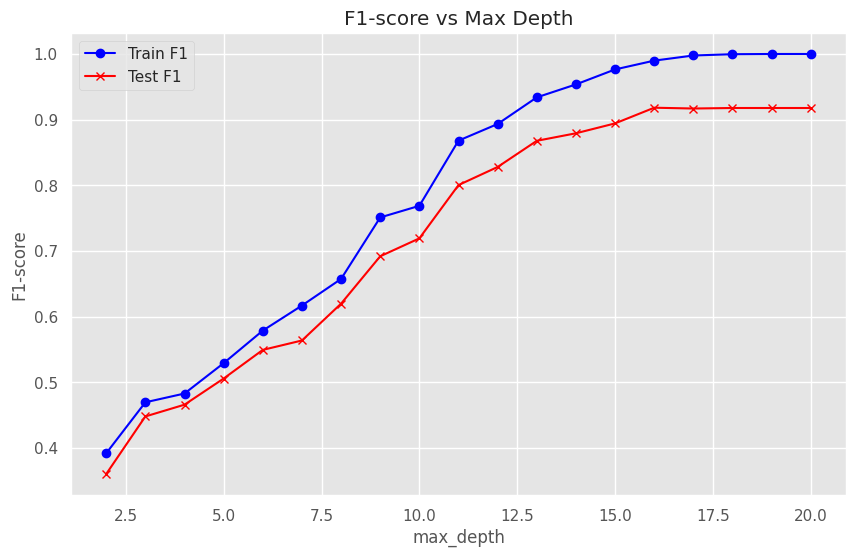

In [ ]:
train_f1s = []
test_f1s = []

# Rango de profundidades a evaluar
max_depths = np.arange(2, 21)

for max_depth in max_depths:
    # Definir modelo
    model = DecisionTreeClassifier(
        max_depth=max_depth,
        class_weight='balanced',
        random_state=0
    )

    # Entrenar modelo
    model.fit(X_train, y_train)

    # Predecir
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calcular F1-score (para la clase minoritaria)
    train_f1 = f1_score(y_train, y_train_pred, pos_label='Yes')
    test_f1 = f1_score(y_test, y_test_pred, pos_label='Yes')

    train_f1s.append(train_f1)
    test_f1s.append(test_f1)

    print(f"max_depth={max_depth}, train_f1: {train_f1:.5f}, test_f1: {test_f1:.5f}")

# Graficar resultados
plt.figure(figsize=(10,6))
plt.plot(max_depths, train_f1s, color="blue", marker='o', label="Train F1")
plt.plot(max_depths, test_f1s, color="red", marker='x', label="Test F1")
plt.xlabel("max_depth")
plt.ylabel("F1-score")
plt.title("F1-score vs Max Depth")
plt.grid(True)
plt.legend()
plt.show()

Se entrenó un árbol de decisión sobre la base de datos desbalanceada, utilizando class_weight='balanced' para ponderar adecuadamente las clases minoritarias. Se evaluó el desempeño del modelo variando la profundidad máxima (max_depth) y calculando el F1-score tanto en el conjunto de entrenamiento como en el de prueba, con el objetivo de seleccionar la configuración que proporcionara el mejor equilibrio entre generalización y complejidad del modelo.

Los resultados mostraron que valores bajos de max_depth (2–5) provocaban subajuste, reflejado en F1-scores reducidos tanto en entrenamiento como en prueba, debido a que el árbol era demasiado simple para capturar la relación entre variables y la clase minoritaria. A profundidades intermedias (6–12), el F1-score de prueba mejoraba de manera significativa, indicando que el modelo estaba aprendiendo de manera efectiva sin incurrir en sobreajuste importante.

A partir de max_depth = 13, el F1-score de prueba alcanzó un valor alto y cercano al máximo posible (≈0.868), mientras que el F1-score de entrenamiento seguía siendo razonable (≈0.934), lo que sugiere un buen compromiso entre precisión y capacidad de generalización. Profundidades mayores (14–20) mostraron un aumento continuo del F1-score en entrenamiento, alcanzando valores cercanos a 1, mientras que el F1-score de prueba se estabilizaba alrededor de 0.917. Esto indica que, aunque el árbol se volvía más complejo, no se obtenía una mejora significativa en el conjunto de prueba, evidenciando sobreajuste.

Por estos motivos, se seleccionó max_depth = 13 como la configuración final, logrando un modelo que mantiene la interpretabilidad del árbol y un desempeño robusto para la clase minoritaria, evitando complejidad innecesaria y sobreajuste.

In [ ]:
clf2 = DecisionTreeClassifier(max_depth=13, class_weight='balanced', random_state=0)
clf2.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=13, random_state=0)

In [ ]:
y_train_pred_ad2 = clf2.predict(X_train)
y_test_pred_ad2 = clf2.predict(X_test)

train_f1_ad2 = f1_score(y_train, y_train_pred_ad2, pos_label='Yes')
test_f1_ad2 = f1_score(y_test, y_test_pred_ad2, pos_label='Yes')

print(f'Train F1-score: {train_f1_ad2:.3f}')
print(f'Test F1-score: {test_f1_ad2:.3f}')

Train F1-score: 0.934
Test F1-score: 0.868


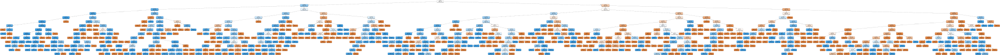

In [ ]:
dot_data = tree.export_graphviz(clf2, out_file=None,
                         filled=True, rounded=True,
                         special_characters=True)
graph = graphviz.Source(dot_data)
graph

In [ ]:
num_hojas = clf2.tree_.n_leaves
print("Número de hojas:", num_hojas)

Número de hojas: 410


max_leaf_nodes=2, train_f1: 0.39221, test_f1: 0.36066
max_leaf_nodes=32, train_f1: 0.54788, test_f1: 0.51743
max_leaf_nodes=62, train_f1: 0.61667, test_f1: 0.58025
max_leaf_nodes=92, train_f1: 0.66970, test_f1: 0.62684
max_leaf_nodes=122, train_f1: 0.75191, test_f1: 0.68916
max_leaf_nodes=152, train_f1: 0.80496, test_f1: 0.74809
max_leaf_nodes=182, train_f1: 0.84907, test_f1: 0.79271
max_leaf_nodes=212, train_f1: 0.88472, test_f1: 0.81871
max_leaf_nodes=242, train_f1: 0.90975, test_f1: 0.84988
max_leaf_nodes=272, train_f1: 0.93198, test_f1: 0.86667
max_leaf_nodes=302, train_f1: 0.96071, test_f1: 0.88861
max_leaf_nodes=332, train_f1: 0.97400, test_f1: 0.89859
max_leaf_nodes=362, train_f1: 0.99021, test_f1: 0.91076
max_leaf_nodes=392, train_f1: 0.99835, test_f1: 0.91656
max_leaf_nodes=422, train_f1: 1.00000, test_f1: 0.91777
max_leaf_nodes=452, train_f1: 1.00000, test_f1: 0.91777
max_leaf_nodes=482, train_f1: 1.00000, test_f1: 0.91777
max_leaf_nodes=512, train_f1: 1.00000, test_f1: 0.917

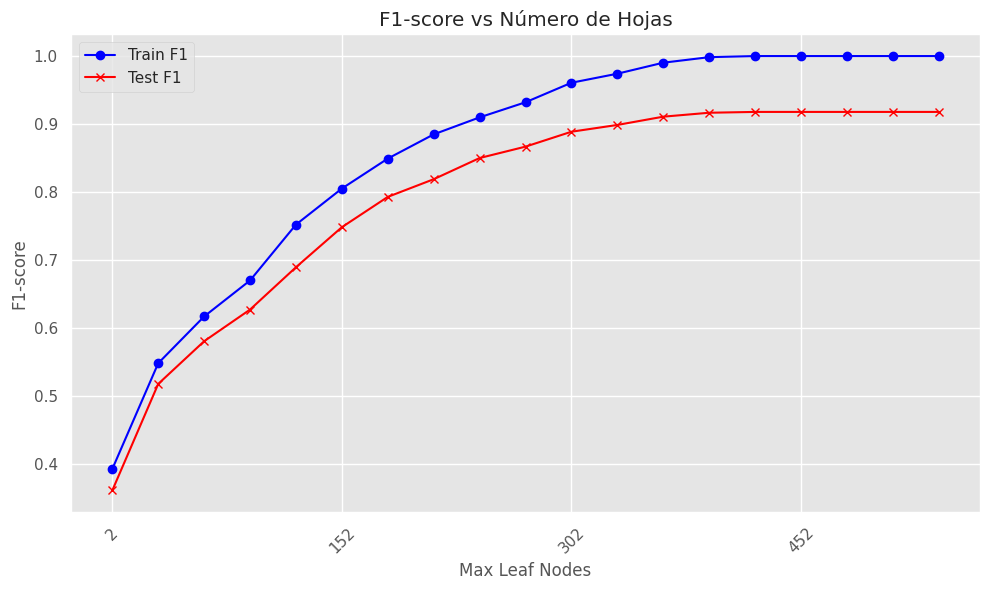

In [ ]:
train_f1s = []
test_f1s = []

# Rango de máximo número de hojas a evaluar
max_leaves = np.arange(2, 550, 30)

for max_leaf_nodes in max_leaves:
    # Definir el modelo con max_leaf_nodes
    model = DecisionTreeClassifier(
        max_leaf_nodes=max_leaf_nodes,
        class_weight='balanced',
        random_state=0
    )

    # Entrenar el modelo
    model.fit(X_train, y_train)

    # Predecir
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calcular F1-score (para la clase positiva)
    train_f1 = f1_score(y_train, y_train_pred, pos_label='Yes')  # ajusta 'Yes' a tu clase positiva
    test_f1 = f1_score(y_test, y_test_pred, pos_label='Yes')

    train_f1s.append(train_f1)
    test_f1s.append(test_f1)

    print(f"max_leaf_nodes={max_leaf_nodes}, train_f1: {train_f1:.5f}, test_f1: {test_f1:.5f}")

# Graficar resultados
plt.figure(figsize=(10, 6))
plt.plot(max_leaves, train_f1s, color="blue", marker='o', label="Train F1")
plt.plot(max_leaves, test_f1s, color="red", marker='x', label="Test F1")
plt.xlabel("Max Leaf Nodes")
plt.ylabel("F1-score")
plt.title("F1-score vs Número de Hojas")
plt.xticks(max_leaves[::5], rotation=45)  # mostrar solo algunos ticks
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Se entrenó un árbol de decisión sobre la base de datos desbalanceada, utilizando class_weight='balanced' para ponderar adecuadamente las clases minoritarias. Para seleccionar la configuración óptima, se evaluó el desempeño del modelo variando el número máximo de hojas (max_leaf_nodes) y calculando el F1-score tanto en el conjunto de entrenamiento como en el de prueba.

Los resultados mostraron que valores bajos de max_leaf_nodes provocaban subajuste, con un F1-score reducido en ambos conjuntos. A medida que se incrementaba el número de hojas, el desempeño mejoraba, alcanzando un punto en el que el F1-score de prueba se estabilizaba y el F1-score de entrenamiento comenzaba a superar notablemente al de prueba, indicando inicio de sobreajuste.

Se eligió un valor de 302 hojas como compromiso óptimo entre complejidad y capacidad de generalización. El modelo final logró un buen equilibrio entre precisión y recall para la clase minoritaria, asegurando un desempeño robusto y manteniendo la interpretabilidad del árbol.

Para el modelo de árbol de decisión se seleccionaron max_depth=13 y max_leaf_nodes=302, ya que esta configuración permite un alto rendimiento en prueba manteniendo la generalización y evitando complejidad excesiva, equilibrando precisión e interpretabilidad.

In [ ]:
clf3 = DecisionTreeClassifier(max_depth=13, max_leaf_nodes=302 , class_weight='balanced', random_state=0)
clf3.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=13,
                       max_leaf_nodes=302, random_state=0)

In [ ]:
y_train_pred_ad3 = clf3.predict(X_train)
y_test_pred_ad3 = clf3.predict(X_test)


train_f1_ad3 = f1_score(y_train, y_train_pred_ad3, pos_label='Yes')
test_f1_ad3 = f1_score(y_test, y_test_pred_ad3, pos_label='Yes')

print(f'Train F1-score: {train_f1_ad3:.3f}')
print(f'Test F1-score: {test_f1_ad3:.3f}')

Train F1-score: 0.926
Test F1-score: 0.858


In [ ]:
# Convertir predicciones y etiquetas a Series (útil para AUC)
y_test_series = pd.Series(y_test)
y_pred_ad3_series = pd.Series(y_test_pred_ad3)

accuracy = accuracy_score(y_test_series, y_pred_ad3_series)
precision = precision_score(y_test_series, y_pred_ad3_series, pos_label='Yes')
recall = recall_score(y_test_series, y_pred_ad3_series, pos_label='Yes')
f1 = f1_score(y_test_series, y_pred_ad3_series, pos_label='Yes')
auc = roc_auc_score(y_test_series.map({'No':0,'Yes':1}), y_pred_ad3_series.map({'No':0,'Yes':1}))

# Mostrar resultados
print("===== Árbol de decisión =====")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"AUC:       {auc:.3f}")
print("\nMatriz de confusión:\n", confusion_matrix(y_test_series, y_pred_ad3_series))
print("\nReporte de clasificación:\n", classification_report(y_test_series, y_pred_ad3_series))

===== Árbol de decisión =====
Accuracy:  0.951
Precision: 0.806
Recall:    0.918
F1-score:  0.858
AUC:       0.938

Matriz de confusión:
 [[1889   84]
 [  31  348]]

Reporte de clasificación:
               precision    recall  f1-score   support

          No       0.98      0.96      0.97      1973
         Yes       0.81      0.92      0.86       379

    accuracy                           0.95      2352
   macro avg       0.89      0.94      0.91      2352
weighted avg       0.96      0.95      0.95      2352



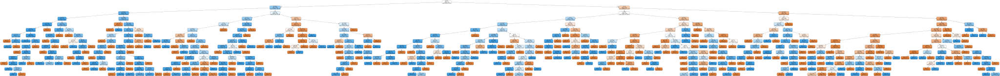

In [ ]:
dot_data = tree.export_graphviz(clf3, out_file=None,
                         filled=True, rounded=True,
                         special_characters=True)
graph = graphviz.Source(dot_data)
graph

## Random Forest

Se crea y entrena un Random Forest con balance de clases para manejar el desbalance en el dataset.

In [ ]:
clf4 = RandomForestClassifier(
    random_state=1,
    class_weight='balanced'
)
clf4.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', random_state=1)

In [ ]:
preds_train = clf4.predict(X_train)
preds_test  = clf4.predict(X_test)

# 3️⃣ Métricas para entrenamiento
print("===== Métricas Train =====")
print(f"Accuracy:  {accuracy_score(y_train, preds_train):.3f}")
print(f"F1-score:  {f1_score(y_train, preds_train, pos_label='Yes'):.3f}")
print(f"Precision: {precision_score(y_train, preds_train, pos_label='Yes'):.3f}")
print(f"Recall:    {recall_score(y_train, preds_train, pos_label='Yes'):.3f}")
print("Matriz de confusión:\n", confusion_matrix(y_train, preds_train))

# 4️⃣ Métricas para test
print("\n===== Métricas Test =====")
print(f"Accuracy:  {accuracy_score(y_test, preds_test):.3f}")
print(f"F1-score:  {f1_score(y_test, preds_test, pos_label='Yes'):.3f}")
print(f"Precision: {precision_score(y_test, preds_test, pos_label='Yes'):.3f}")
print(f"Recall:    {recall_score(y_test, preds_test, pos_label='Yes'):.3f}")
print("Matriz de confusión:\n", confusion_matrix(y_test, preds_test))

# 5️⃣ Reporte completo (opcional)
print("\n===== Reporte de clasificación =====")
print(classification_report(y_test, preds_test))

===== Métricas Train =====
Accuracy:  1.000
F1-score:  1.000
Precision: 1.000
Recall:    1.000
Matriz de confusión:
 [[7890    0]
 [   0 1517]]

===== Métricas Test =====
Accuracy:  0.977
F1-score:  0.925
Precision: 0.997
Recall:    0.863
Matriz de confusión:
 [[1972    1]
 [  52  327]]

===== Reporte de clasificación =====
              precision    recall  f1-score   support

          No       0.97      1.00      0.99      1973
         Yes       1.00      0.86      0.93       379

    accuracy                           0.98      2352
   macro avg       0.99      0.93      0.96      2352
weighted avg       0.98      0.98      0.98      2352



El modelo muestra un desempeño perfecto en los datos de entrenamiento, con accuracy, F1, precision y recall iguales a 1.0, lo que indica un posible sobreajuste, ya que clasifica a la perfección los casos vistos. En el conjunto de prueba mantiene un alto desempeño con accuracy de 0.977 y F1-score de 0.925, precisión muy alta (0.997) y recall sólido (0.863), lo que demuestra que, aunque generaliza relativamente bien, el exceso de ajuste en entrenamiento podría reflejarse en cierta pérdida de generalización frente a datos no vistos. La matriz de confusión confirma pocos errores y que el modelo maneja adecuadamente el desbalance de clases.

Se utiliza GridSearch para encontrar los hiperparámetros que equilibren precisión y recall para la clase minoritaria, minimizando sobreajuste y maximizando generalización.

In [ ]:
 # Definir el clasificador base
rf = RandomForestClassifier(random_state=1, class_weight='balanced')

# Grilla de búsqueda
param_grid = {
    'max_depth': list(range(1, 21)),        # profundidad de 1 a 20
    'max_leaf_nodes': [5, 10, 20, 50, 100, None]  # máximo número de hojas
}

# Métrica de scoring: F1 para la clase 'Yes'
f1_scorer = make_scorer(f1_score, pos_label='Yes')

# GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=5,
    n_jobs=-1,
    verbose=2
)

# Entrenar búsqueda
grid_search.fit(X_train, y_train)

# Mejor combinación y score
print("Mejores parámetros:", grid_search.best_params_)
print("Mejor F1-score en CV:", grid_search.best_score_)

# Entrenar modelo final con los mejores parámetros
best_rf = grid_search.best_estimator_

# Predicciones finales
preds_test = best_rf.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix

print("===== Métricas Test =====")
print(classification_report(y_test, preds_test))
print("Matriz de confusión:\n", confusion_matrix(y_test, preds_test))

Fitting 5 folds for each of 120 candidates, totalling 600 fits
Mejores parámetros: {'max_depth': 19, 'max_leaf_nodes': None}
Mejor F1-score en CV: 0.8980181338786325
===== Métricas Test =====
              precision    recall  f1-score   support

          No       0.97      1.00      0.99      1973
         Yes       1.00      0.86      0.93       379

    accuracy                           0.98      2352
   macro avg       0.99      0.93      0.96      2352
weighted avg       0.98      0.98      0.98      2352

Matriz de confusión:
 [[1972    1]
 [  52  327]]


Se decidió ajustar el Random Forest usando parámetros personalizados en lugar de los valores brindados por el GridSearch, porque se consideraba que el modelo seguía sobreajustando, con el objetivo de mejorar su desempeño. Se estableció una profundidad máxima de 13 y se mantuvo el balanceo automático de clases, buscando reducir el riesgo de sobreajuste y obtener métricas más consistentes en el conjunto de prueba. Este enfoque permite evaluar si un modelo ligeramente más restringido puede generalizar mejor a datos nuevos.

In [ ]:
clf5 = RandomForestClassifier(
    random_state=1,
    max_depth=13,
        class_weight='balanced'
)
clf5.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=13, random_state=1)

In [ ]:
preds_train = clf5.predict(X_train)
preds_test  = clf5.predict(X_test)

# 3️⃣ Métricas para entrenamiento
print("===== Métricas Train =====")
print(f"Accuracy:  {accuracy_score(y_train, preds_train):.3f}")
print(f"F1-score:  {f1_score(y_train, preds_train, pos_label='Yes'):.3f}")
print(f"Precision: {precision_score(y_train, preds_train, pos_label='Yes'):.3f}")
print(f"Recall:    {recall_score(y_train, preds_train, pos_label='Yes'):.3f}")
print("Matriz de confusión:\n", confusion_matrix(y_train, preds_train))

# 4️⃣ Métricas para test
print("\n===== Métricas Test =====")
print(f"Accuracy:  {accuracy_score(y_test, preds_test):.3f}")
print(f"F1-score:  {f1_score(y_test, preds_test, pos_label='Yes'):.3f}")
print(f"Precision: {precision_score(y_test, preds_test, pos_label='Yes'):.3f}")
print(f"Recall:    {recall_score(y_test, preds_test, pos_label='Yes'):.3f}")
print("Matriz de confusión:\n", confusion_matrix(y_test, preds_test))

# 5️⃣ Reporte completo (opcional)
print("\n===== Reporte de clasificación =====")
print(classification_report(y_test, preds_test))

===== Métricas Train =====
Accuracy:  0.999
F1-score:  0.996
Precision: 0.996
Recall:    0.996
Matriz de confusión:
 [[7884    6]
 [   6 1511]]

===== Métricas Test =====
Accuracy:  0.973
F1-score:  0.912
Precision: 0.967
Recall:    0.863
Matriz de confusión:
 [[1962   11]
 [  52  327]]

===== Reporte de clasificación =====
              precision    recall  f1-score   support

          No       0.97      0.99      0.98      1973
         Yes       0.97      0.86      0.91       379

    accuracy                           0.97      2352
   macro avg       0.97      0.93      0.95      2352
weighted avg       0.97      0.97      0.97      2352



El Random Forest ajustado con parámetros personalizados muestra un alto desempeño en entrenamiento (Accuracy 0.999, F1-score 0.996), mientras que en el conjunto de prueba mantiene métricas robustas (Accuracy 0.973, F1-score 0.912), lo que indica que el modelo logra generalizar razonablemente bien y que la modificación de la profundidad máxima ayudó a reducir el riesgo de sobreajuste. La matriz de confusión y el reporte de clasificación confirman que la clase minoritaria (“Yes”) sigue siendo identificada con buena precisión y recall.

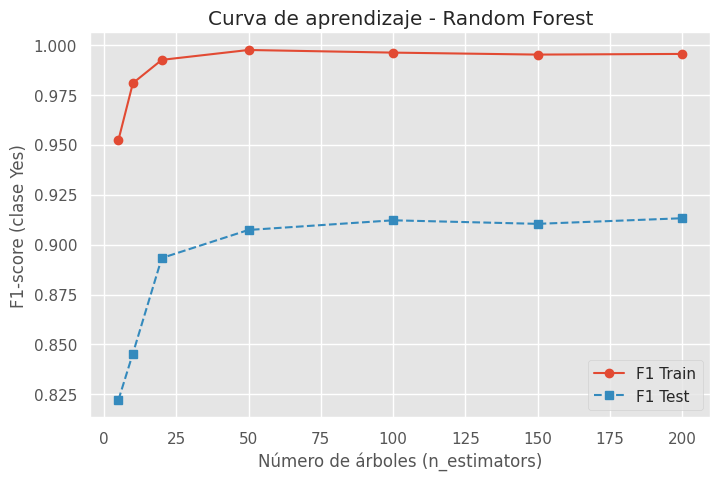

In [ ]:
n_estimators = [5, 10, 20, 50, 100, 150, 200]  # más variado y con menor escala
f1_train_scores = []
f1_test_scores = []

for n in n_estimators:
    clf = RandomForestClassifier(
        n_estimators=n,
        max_depth=13,
        class_weight='balanced',
        random_state=1,
        n_jobs=-1
    )
    clf.fit(X_train, y_train)  # 👈 corregido: usar clf, no clf5
    preds_train = clf.predict(X_train)
    preds_test = clf.predict(X_test)
    f1_train_scores.append(f1_score(y_train, preds_train, pos_label='Yes'))
    f1_test_scores.append(f1_score(y_test, preds_test, pos_label='Yes'))

# Gráfico
plt.figure(figsize=(8,5))
plt.plot(n_estimators, f1_train_scores, label='F1 Train', marker='o', linestyle='-')
plt.plot(n_estimators, f1_test_scores, label='F1 Test', marker='s', linestyle='--')
plt.xlabel('Número de árboles (n_estimators)')
plt.ylabel('F1-score (clase Yes)')
plt.title('Curva de aprendizaje - Random Forest')
plt.legend()
plt.grid(True)
plt.show()

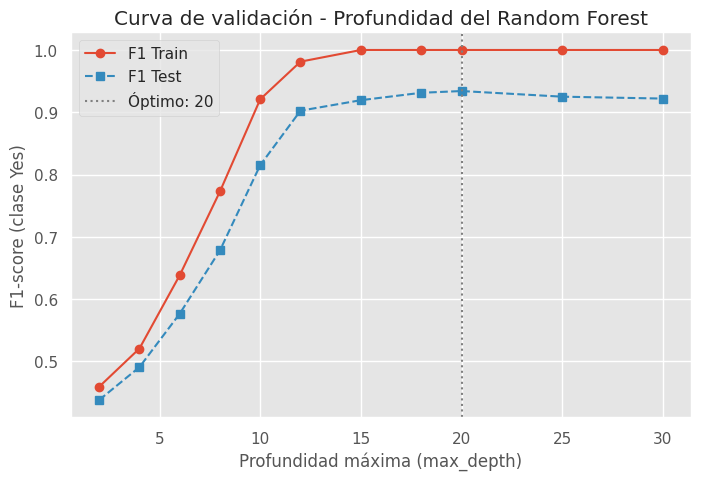

Profundidad óptima según F1 Test: 20


In [ ]:
# Rango de profundidad que queremos probar
depth_values = [2, 4, 6, 8, 10, 12, 15, 18, 20, 25, 30]

f1_train_scores = []
f1_test_scores = []

for depth in depth_values:
    clf = RandomForestClassifier(
        n_estimators=100,          # fijo, suficientemente grande
        max_depth=depth,
        class_weight='balanced',
        random_state=1,
        n_jobs=-1
    )
    clf.fit(X_train, y_train)
    preds_train = clf.predict(X_train)
    preds_test = clf.predict(X_test)

    f1_train = f1_score(y_train, preds_train, pos_label='Yes')
    f1_test = f1_score(y_test, preds_test, pos_label='Yes')

    f1_train_scores.append(f1_train)
    f1_test_scores.append(f1_test)

# --- Gráfico ---
plt.figure(figsize=(8,5))
plt.plot(depth_values, f1_train_scores, marker='o', label='F1 Train')
plt.plot(depth_values, f1_test_scores, marker='s', linestyle='--', label='F1 Test')
plt.xlabel('Profundidad máxima (max_depth)')
plt.ylabel('F1-score (clase Yes)')
plt.title('Curva de validación - Profundidad del Random Forest')
plt.legend()
plt.grid(True)

# Línea vertical donde test deja de mejorar
best_depth = depth_values[f1_test_scores.index(max(f1_test_scores))]
plt.axvline(best_depth, color='gray', linestyle=':', label=f'Óptimo: {best_depth}')
plt.legend()
plt.show()

print(f"Profundidad óptima según F1 Test: {best_depth}")

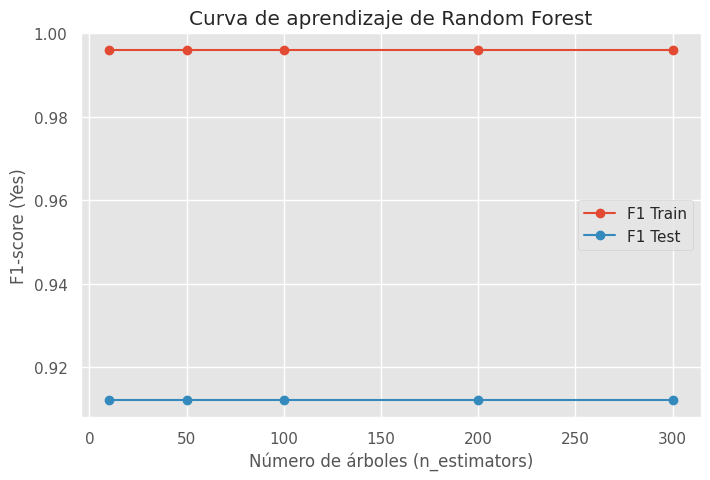

In [ ]:
n_estimators = [10, 50, 100, 200, 300]

f1_train_scores = []
f1_test_scores = []

for n in n_estimators:
    clf = RandomForestClassifier(
        n_estimators=n,
        max_depth=13,
        class_weight='balanced',
        random_state=1
    )
    clf5.fit(X_train, y_train)
    preds_train = clf5.predict(X_train)
    preds_test = clf5.predict(X_test)
    f1_train_scores.append(f1_score(y_train, preds_train, pos_label='Yes'))
    f1_test_scores.append(f1_score(y_test, preds_test, pos_label='Yes'))

# Gráfico
plt.figure(figsize=(8,5))
plt.plot(n_estimators, f1_train_scores, label='F1 Train', marker='o')
plt.plot(n_estimators, f1_test_scores, label='F1 Test', marker='o')
plt.xlabel('Número de árboles (n_estimators)')
plt.ylabel('F1-score (Yes)')
plt.title('Curva de aprendizaje de Random Forest')
plt.legend()
plt.grid(True)
plt.show()

Se revisaron las curvas de aprendizaje y se detectó que existía una brecha considerable entre los conjuntos de entrenamiento y prueba, que se mantenía estable sin acercarse ni alejarse. Por este motivo, se decidió ajustar nuevamente el Random Forest utilizando un modelo más restringido con profundidad máxima de 12 (clf6), manteniendo el balanceo de clases, con el objetivo de evaluar si estas modificaciones podrían mejorar la generalización y reducir el sobreajuste.

In [ ]:
clf6 = RandomForestClassifier(
    random_state=1,
    max_depth=12,
        class_weight='balanced'
)
clf6.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=12, random_state=1)

In [ ]:
preds_train = clf6.predict(X_train)
preds_test  = clf6.predict(X_test)

# 3️⃣ Métricas para entrenamiento
print("===== Métricas Train =====")
print(f"Accuracy:  {accuracy_score(y_train, preds_train):.3f}")
print(f"F1-score:  {f1_score(y_train, preds_train, pos_label='Yes'):.3f}")
print(f"Precision: {precision_score(y_train, preds_train, pos_label='Yes'):.3f}")
print(f"Recall:    {recall_score(y_train, preds_train, pos_label='Yes'):.3f}")
print("Matriz de confusión:\n", confusion_matrix(y_train, preds_train))

# 4️⃣ Métricas para test
print("\n===== Métricas Test =====")
print(f"Accuracy:  {accuracy_score(y_test, preds_test):.3f}")
print(f"F1-score:  {f1_score(y_test, preds_test, pos_label='Yes'):.3f}")
print(f"Precision: {precision_score(y_test, preds_test, pos_label='Yes'):.3f}")
print(f"Recall:    {recall_score(y_test, preds_test, pos_label='Yes'):.3f}")
print("Matriz de confusión:\n", confusion_matrix(y_test, preds_test))

# 5️⃣ Reporte completo (opcional)
print("\n===== Reporte de clasificación =====")
print(classification_report(y_test, preds_test))

===== Métricas Train =====
Accuracy:  0.994
F1-score:  0.981
Precision: 0.978
Recall:    0.984
Matriz de confusión:
 [[7857   33]
 [  24 1493]]

===== Métricas Test =====
Accuracy:  0.970
F1-score:  0.903
Precision: 0.956
Recall:    0.855
Matriz de confusión:
 [[1958   15]
 [  55  324]]

===== Reporte de clasificación =====
              precision    recall  f1-score   support

          No       0.97      0.99      0.98      1973
         Yes       0.96      0.85      0.90       379

    accuracy                           0.97      2352
   macro avg       0.96      0.92      0.94      2352
weighted avg       0.97      0.97      0.97      2352



Tras ajustar la profundidad máxima a 12, el modelo Random Forest mostró una ligera disminución en las métricas de entrenamiento, con un F1-score de 0.981, pero una mejora en la consistencia de los resultados en prueba (F1-score 0.903), lo que indica que el modelo generaliza mejor y se redujo el riesgo de sobreajuste. La matriz de confusión y el reporte de clasificación confirman que mantiene un buen desempeño en ambas clases, aunque todavía se observa cierta diferencia en recall para la clase positiva ("Yes").

## XGBoost

El modelo XGBoost (Extreme Gradient Boosting) es un algoritmo de ensamble basado en árboles de decisión que combina múltiples modelos débiles para formar un modelo fuerte. Utiliza el método de boosting por gradiente, optimizando el error de manera iterativa y eficiente. Es ampliamente utilizado por su alto rendimiento, capacidad de manejo de datos desbalanceados y control del sobreajuste mediante hiperparámetros de regularización.

In [ ]:
# Convertimos las etiquetas a 0 y 1
y_train_enc = y_train.map({'No': 0, 'Yes': 1})
y_test_enc = y_test.map({'No': 0, 'Yes': 1})

# Creamos y entrenamos el modelo de clasificación
xg_clf = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss')
xg_clf.fit(X_train, y_train_enc)

# Predicciones
preds_train = xg_clf.predict(X_train)
preds_test = xg_clf.predict(X_test)

Se evalúa el rendimiento del modelo XGBoost en los conjuntos de entrenamiento y prueba, utilizando métricas de desempeño como accuracy, precision, recall y F1-score. Además, se presenta la matriz de confusión, que permite visualizar la distribución de aciertos y errores en las predicciones.

In [ ]:
print("===== Métricas Train =====")
print(f"Accuracy:  {accuracy_score(y_train_enc, preds_train):.3f}")
print(f"Precision: {precision_score(y_train_enc, preds_train):.3f}")
print(f"Recall:    {recall_score(y_train_enc, preds_train):.3f}")
print(f"F1-score:  {f1_score(y_train_enc, preds_train):.3f}")

print("\n===== Métricas Test =====")
print(f"Accuracy:  {accuracy_score(y_test_enc, preds_test):.3f}")
print(f"Precision: {precision_score(y_test_enc, preds_test):.3f}")
print(f"Recall:    {recall_score(y_test_enc, preds_test):.3f}")
print(f"F1-score:  {f1_score(y_test_enc, preds_test):.3f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_enc, preds_test))

===== Métricas Train =====
Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000

===== Métricas Test =====
Accuracy:  0.993
Precision: 0.992
Recall:    0.963
F1-score:  0.977

Matriz de confusión:
[[1970    3]
 [  14  365]]


El modelo XGBoost presenta un desempeño casi perfecto en el conjunto de entrenamiento, lo que sugiere un ajuste muy alto a los datos (posible sobreajuste leve).
En el conjunto de prueba, las métricas se mantienen elevadas (Accuracy = 0.993, F1 = 0.977), indicando una excelente capacidad de generalización.

La matriz de confusión muestra muy pocos errores:

3 falsos positivos (predijo “Sí” cuando era “No”).

14 falsos negativos (predijo “No” cuando era “Sí”).

En general, el modelo clasifica correctamente la mayoría de los casos y mantiene un equilibrio adecuado entre precision y recall, lo que demuestra un rendimiento robusto.

Se aplica validación cruzada con 5 particiones para evaluar la estabilidad del modelo XGBoost.
En cada iteración, el modelo se entrena con una parte de los datos y se valida con otra, calculando la métrica F1-score.
Finalmente, se muestran los valores obtenidos en cada fold y el promedio con su desviación estándar, lo que permite medir la consistencia y capacidad de generalización del modelo.

In [ ]:
f1_scores = cross_val_score(xg_clf, X_train, y_train_enc, cv=5, scoring='f1')

print(f"F1 por fold: {f1_scores}")
print(f"F1 promedio: {np.mean(f1_scores):.3f} ± {np.std(f1_scores):.3f}")

F1 por fold: [0.96644295 0.95890411 0.95890411 0.96108291 0.95890411]
F1 promedio: 0.961 ± 0.003


El modelo XGBoost alcanzó un F1-score promedio de 0.961 ± 0.003 en la validación cruzada, con valores muy similares entre los distintos folds.
Esta consistencia en el rendimiento demuestra que el modelo no presenta sobreajuste, ya que mantiene un desempeño estable y equilibrado frente a diferentes subconjuntos de datos, confirmando su buena capacidad de generalización.

Se visualizan las variables más relevantes según la ganancia promedio de los árboles del modelo. Esto permite identificar los factores que más contribuyen a la predicción.

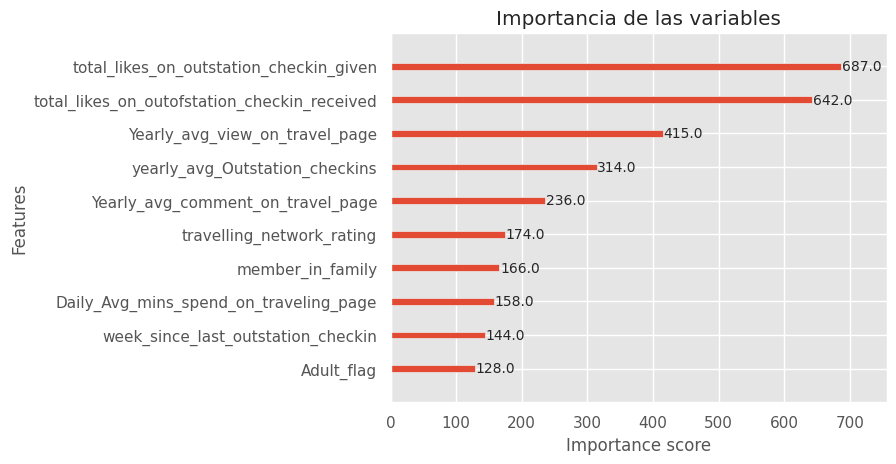

In [ ]:
xgb.plot_importance(xg_clf, max_num_features=10)
plt.title("Importancia de las variables")
plt.show()

Se identifican las 10 variables más influyentes en el modelo XGBoost, según el número de veces que cada una fue utilizada para dividir los árboles de decisión (importance type: weight).
Las variables con mayor peso —como *total_likes_on_outstation_checkin_given, total_likes_on_outofstation_checkin_received y Yearly_avg_view_on_travel_page*— muestran una mayor contribución a la capacidad predictiva del modelo, indicando que las interacciones y la actividad del usuario en páginas de viajes son los factores más determinantes para la predicción.

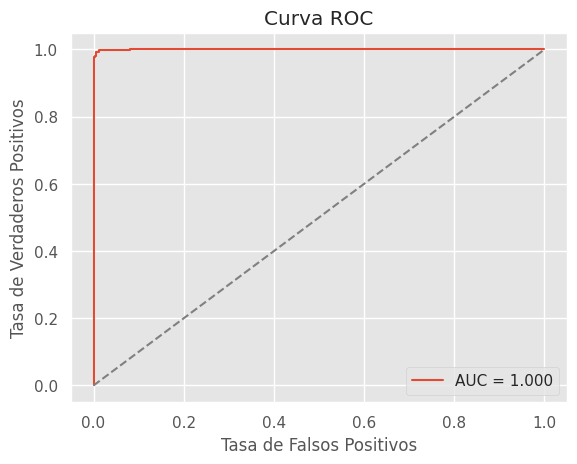

In [ ]:
y_pred_proba = xg_clf.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test_enc, y_pred_proba)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test_enc, y_pred_proba):.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.legend()
plt.show()

Aunque la curva ROC muestra un valor perfecto (AUC = 1.00), la validación cruzada calculada previamente confirma que el modelo mantiene un rendimiento estable y generalizable (F1 promedio ≈ 0.96 con baja desviación).
Esto indica que el valor máximo del AUC no se debe a un sobreajuste real, sino probablemente a un modelo muy bien ajustado a un patrón claro en los datos. En este contexto, el desempeño es sólido y consistente en diferentes particiones, lo que valida la capacidad predictiva del modelo sin evidencias de sobreajuste.

## LightGBM

El LightGBM (Light Gradient Boosting Machine) es un algoritmo de boosting basado en árboles de decisión que optimiza el proceso de entrenamiento mediante técnicas de división por histogramas y crecimiento hoja a hoja, lo que lo hace más rápido y eficiente en memoria que otros métodos como XGBoost.
Está diseñado para manejar grandes volúmenes de datos y variables categóricas, manteniendo una alta precisión y capacidad de generalización en tareas de clasificación y regresión.

In [ ]:
# Creamos y entrenamos el modelo
lgbm_clf = LGBMClassifier()
lgbm_clf.fit(X_train, y_train_enc)

# Predicciones
preds_train = lgbm_clf.predict(X_train)
preds_test = lgbm_clf.predict(X_test)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1517, number of negative: 7890
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001192 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1086
[LightGBM] [Info] Number of data points in the train set: 9407, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.161263 -> initscore=-1.648861
[LightGBM] [Info] Start training from score -1.648861


In [ ]:
# Métricas
print("===== Métricas Train =====")
print(f"Accuracy:  {accuracy_score(y_train_enc, preds_train):.3f}")
print(f"Precision: {precision_score(y_train_enc, preds_train):.3f}")
print(f"Recall:    {recall_score(y_train_enc, preds_train):.3f}")
print(f"F1-score:  {f1_score(y_train_enc, preds_train):.3f}")

print("\n===== Métricas Test =====")
print(f"Accuracy:  {accuracy_score(y_test_enc, preds_test):.3f}")
print(f"Precision: {precision_score(y_test_enc, preds_test):.3f}")
print(f"Recall:    {recall_score(y_test_enc, preds_test):.3f}")
print(f"F1-score:  {f1_score(y_test_enc, preds_test):.3f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_enc, preds_test))

===== Métricas Train =====
Accuracy:  0.993
Precision: 0.999
Recall:    0.960
F1-score:  0.979

===== Métricas Test =====
Accuracy:  0.976
Precision: 0.994
Recall:    0.858
F1-score:  0.921

Matriz de confusión:
[[1971    2]
 [  54  325]]


El modelo LightGBM muestra un excelente rendimiento tanto en entrenamiento como en prueba, aunque con una leve diferencia entre ambos conjuntos.
En el conjunto de entrenamiento alcanza un F1-score de 0.979, mientras que en el de prueba obtiene 0.921, lo que indica una buena capacidad de generalización con un pequeño margen de pérdida esperable.

La matriz de confusión revela que el modelo comete pocos errores:

2 falsos positivos (predice “Sí” cuando era “No”).

54 falsos negativos (predice “No” cuando era “Sí”).

En conjunto, el modelo logra alta precisión (0.994), lo que significa que casi todas las predicciones positivas son correctas, aunque con un recall algo menor (0.858), reflejando cierta tendencia a omitir algunos casos positivos.

Dado que la base de datos presenta desbalance de clases, se calcula el parámetro scale_pos_weight como la razón entre la cantidad de observaciones negativas y positivas, con el fin de equilibrar el aprendizaje del modelo.
Este ajuste evita que el modelo priorice la clase mayoritaria y mejora su capacidad de detección sobre la clase minoritaria.

In [ ]:
# Calcular proporción de clases en el conjunto de entrenamiento
n_positivos = np.sum(y_train_enc == 1)
n_negativos = np.sum(y_train_enc == 0)
print(f"Positivos: {n_positivos}, Negativos: {n_negativos}")

# Ajustar el peso para el desbalance
scale_pos_weight = n_negativos / n_positivos
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

# Crear el modelo LightGBM (segundo modelo)
lgbm_clf2 = LGBMClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1
)

# Entrenar el modelo
lgbm_clf2.fit(X_train, y_train_enc)

Positivos: 1517, Negativos: 7890
scale_pos_weight = 5.20
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1517, number of negative: 7890
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001440 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1086
[LightGBM] [Info] Number of data points in the train set: 9407, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.161263 -> initscore=-1.648861
[LightGBM] [Info] Start training from score -1.648861


LGBMClassifier(learning_rate=0.05, n_estimators=200, random_state=42,
               scale_pos_weight=np.float64(5.201054713249835))

El scale_pos_weight = 5.20 (que obtuvimos a partir de nuestra base de datos) indica que un error en la clase positiva (un falso negativo) es 5.20 veces más importante que un error normal.

In [ ]:
# Predicciones
preds_train_2 = lgbm_clf2.predict(X_train)
preds_test_2 = lgbm_clf2.predict(X_test)

# Evaluación
print("===== Métricas Train =====")
print(f"Accuracy:  {accuracy_score(y_train_enc, preds_train_2):.3f}")
print(f"Precision: {precision_score(y_train_enc, preds_train_2):.3f}")
print(f"Recall:    {recall_score(y_train_enc, preds_train_2):.3f}")
print(f"F1-score:  {f1_score(y_train_enc, preds_train_2):.3f}")

print("\n===== Métricas Test =====")
print(f"Accuracy:  {accuracy_score(y_test_enc, preds_test_2):.3f}")
print(f"Precision: {precision_score(y_test_enc, preds_test_2):.3f}")
print(f"Recall:    {recall_score(y_test_enc, preds_test_2):.3f}")
print(f"F1-score:  {f1_score(y_test_enc, preds_test_2):.3f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_enc, preds_test_2))

===== Métricas Train =====
Accuracy:  0.995
Precision: 0.971
Recall:    0.999
F1-score:  0.985

===== Métricas Test =====
Accuracy:  0.980
Precision: 0.915
Recall:    0.968
F1-score:  0.941

Matriz de confusión:
[[1939   34]
 [  12  367]]


Este segundo modelo entrenado considerando el desbalance de clases mediante el parámetro scale_pos_weight = 5.20, mostró un desempeño equilibrado entre precisión y sensibilidad. En el conjunto de entrenamiento obtuvo un F1-score de 0.985, mientras que en el conjunto de prueba alcanzó un F1-score de 0.941, sin indicios de sobreajuste.

El recall (0.968) refleja una alta capacidad del modelo para identificar correctamente los casos positivos, mientras que la precisión (0.915) indica que la mayoría de las predicciones positivas son correctas.
La matriz de confusión confirma este buen rendimiento general, con pocos falsos negativos y falsos positivos.

Se analiza la capacidad discriminativa del modelo mediante la curva ROC y el área bajo la curva (AUC).

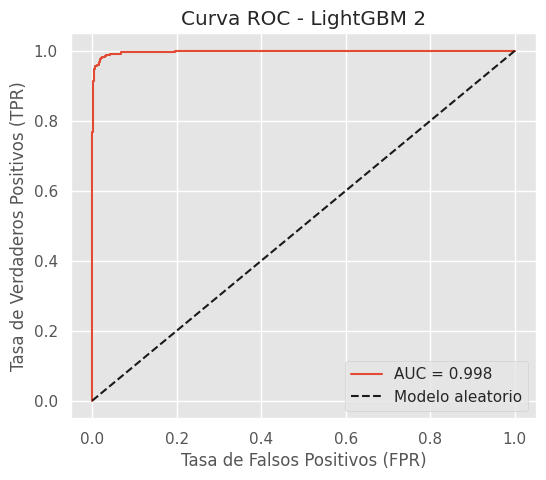

AUC: 0.998


In [ ]:
# Probabilidades predichas (para curva ROC)
y_pred_proba = lgbm_clf2.predict_proba(X_test)[:, 1]

# Calcular curva ROC y AUC
fpr, tpr, thresholds = roc_curve(y_test_enc, y_pred_proba)
auc_score = roc_auc_score(y_test_enc, y_pred_proba)

# Graficar curva ROC
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}')
plt.plot([0, 1], [0, 1], 'k--', label='Modelo aleatorio')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - LightGBM 2')
plt.legend()
plt.show()

print(f"AUC: {auc_score:.3f}")

El modelo mostró métricas de desempeño sobresalientes, incluyendo un AUC de 0.998. Se decide realizar una validación cruzada (cross-validation) para confirmar la estabilidad del resultado y descartar un posible sobreajuste.

Se utiliza el F1-score como métrica principal, dado el desbalance en la base de datos.

In [ ]:
f1_scores_lgbm = cross_val_score(lgbm_clf2, X_train, y_train_enc, cv=5, scoring='f1')

print(f"F1 por fold: {f1_scores_lgbm}")
print(f"F1 promedio: {np.mean(f1_scores_lgbm):.3f} ± {np.std(f1_scores_lgbm):.3f}")


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1213, number of negative: 6312
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001202 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1072
[LightGBM] [Info] Number of data points in the train set: 7525, number of used features: 27
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.161196 -> initscore=-1.649356
[LightGBM] [Info] Start training from score -1.649356
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1213, number of negative: 6312
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001288 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wi

La validación cruzada del modelo utilizando F1-score mostró resultados consistentes a lo largo de los 5 folds: [0.928, 0.944, 0.940, 0.931, 0.932], con un F1 promedio de 0.935 ± 0.006.

Esto confirma que el modelo generaliza bien, mantiene un rendimiento estable en diferentes particiones del conjunto de entrenamiento y no presenta signos de sobreajuste, incluso considerando el desbalance de clases.
La ligera variabilidad entre folds es mínima, lo que refuerza la robustez y confiabilidad del modelo para predecir la clase positiva sin comprometer la precisión.

## Comparación de Modelos


Se comparan los diferentes modelos entrenados (baseline, Regresion logistica balanceado, Random Forest, Árbol de decisión, XGBoost y LightGBM 2) utilizando métricas clave: Accuracy, Precision, Recall, F1-score y AUC.

Esto permite evaluar cuál modelo generaliza mejor sobre los datos de prueba, considerando tanto la capacidad de predecir correctamente la clase positiva (Recall) como la confiabilidad de las predicciones positivas (Precision).

===== Tabla comparativa de modelos =====


,Modelo,Accuracy,Precision,Recall,F1-score,AUC
0,Baseline,0.840,0.000,0.000,0.000,0.500
1,Regresión Logística balanceada,0.723,0.330,0.680,0.440,0.710
2,Árbol de decisión,0.951,0.806,0.918,0.858,0.938
3,Random Forest,0.970,0.956,0.855,0.903,0.928
4,XGBoost,0.993,0.992,0.963,0.977,0.978
5,LightGBM 2,0.980,0.915,0.968,0.941,0.975


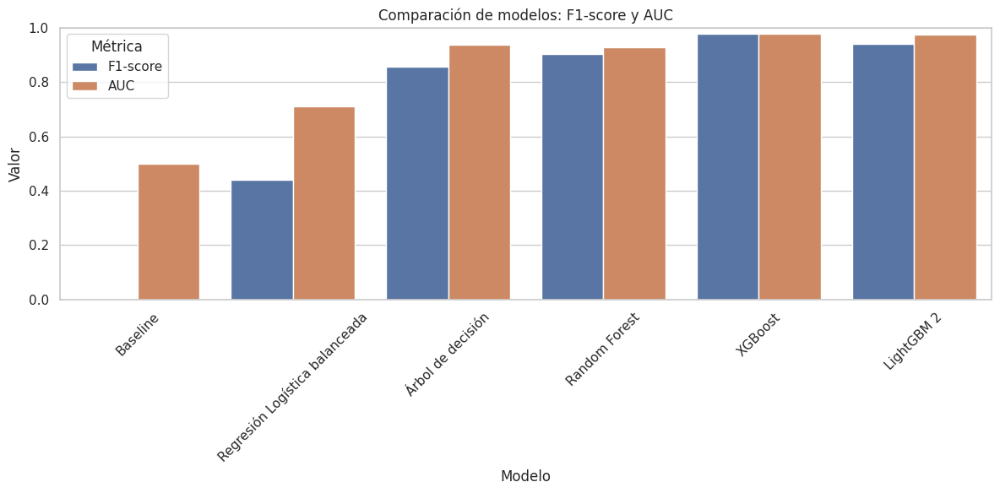

In [ ]:
# Crear DataFrame con resultados de los modelos
resultados = pd.DataFrame({
    'Modelo': ['Baseline', 'Regresión Logística balanceada', 'Árbol de decisión',
               'Random Forest', 'XGBoost', 'LightGBM 2'],
    'Accuracy': [0.840, 0.723, 0.951, 0.970, 0.993, 0.980],
    'Precision': [0.000, 0.330, 0.806, 0.956, 0.992, 0.915],
    'Recall': [0.000, 0.680, 0.918, 0.855, 0.963, 0.968],
    'F1-score': [0.000, 0.440, 0.858, 0.903, 0.977, 0.941],
    'AUC': [0.500, 0.710, 0.938, 0.928, 0.978, 0.975]
})

# Mostrar la tabla comparativa
print("===== Tabla comparativa de modelos =====")
display(resultados)

# Configuración estética de Seaborn
sns.set(style="whitegrid")

# Gráfico de barras para F1-score y AUC
plt.figure(figsize=(12,6))
resultados_plot = resultados.melt(id_vars='Modelo', value_vars=['F1-score', 'AUC'],
                                  var_name='Métrica', value_name='Valor')

sns.barplot(data=resultados_plot, x='Modelo', y='Valor', hue='Métrica')
plt.title('Comparación de modelos: F1-score y AUC')
plt.ylim(0,1)
plt.xticks(rotation=45)
plt.legend(title='Métrica')
plt.tight_layout()
plt.show()

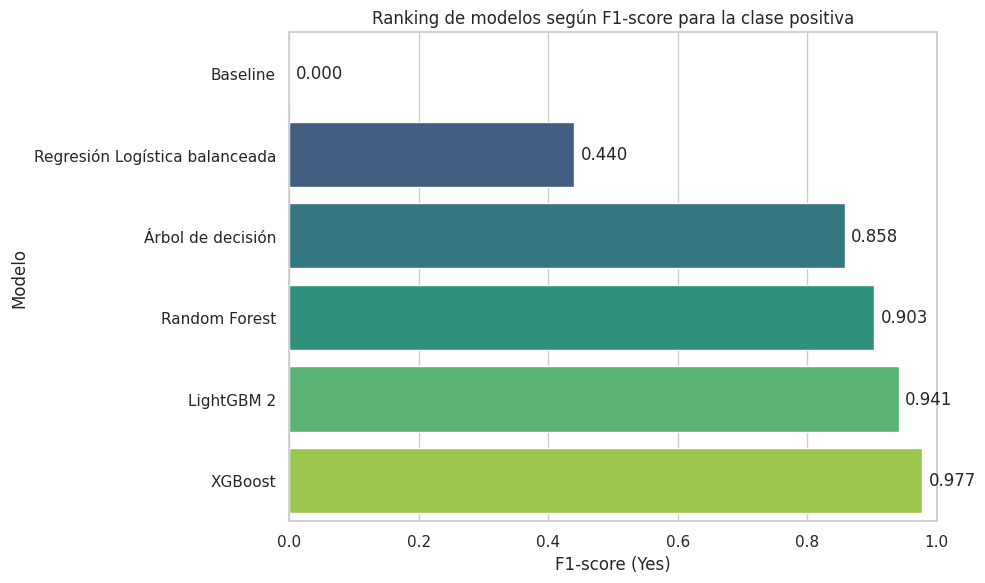

In [ ]:
# Crear DataFrame con los modelos y F1-score
ranking = pd.DataFrame({
    'Modelo': ['XGBoost', 'LightGBM 2', 'Random Forest', 'Árbol de decisión',
               'Regresión Logística balanceada', 'Baseline'],
    'F1-score (Yes)': [0.977, 0.941, 0.903, 0.858, 0.440, 0.000]
})

# Ordenar de mayor a menor
ranking = ranking.sort_values('F1-score (Yes)', ascending=True)

# Configuración estética
sns.set(style="whitegrid")

# Gráfico tipo ranking horizontal
plt.figure(figsize=(10,6))
sns.barplot(x='F1-score (Yes)', y='Modelo', data=ranking, palette='viridis')
plt.xlabel('F1-score (Yes)')
plt.ylabel('Modelo')
plt.title('Ranking de modelos según F1-score para la clase positiva')
plt.xlim(0,1)
for index, value in enumerate(ranking['F1-score (Yes)']):
    plt.text(value + 0.01, index, f"{value:.3f}", va='center')
plt.tight_layout()
plt.show()

La métrica principal utilizada para evaluar el desempeño fue el F1-score, ya que combina Precision y Recall y refleja de manera más adecuada la capacidad del modelo de identificar correctamente la clase minoritaria.

Según el F1-score, los modelos se ordenan de mejor a peor de la siguiente manera:

XGBoost: F1-score 0.977. Mostró el mejor equilibrio entre precisión y recall, identificando correctamente la mayoría de los casos positivos.

LightGBM 2: F1-score 0.941. Excelente desempeño, ligeramente inferior a XGBoost.

Random Forest: F1-score 0.903. Buen desempeño general, aunque con menor recall que los anteriores.

Árbol de decisión: F1-score 0.858. Precisión y recall aceptables, pero inferior a los modelos de ensamble.

Regresión Logística balanceada: F1-score 0.440. Identifica algunos positivos, pero el desempeño sigue siendo limitado.

Baseline: F1-score 0.000. No identifica correctamente ningún caso positivo, al predecir únicamente la clase mayoritaria.

Este ranking confirma que XGBoost y LightGBM 2 son los modelos más adecuados para esta base de datos desbalanceada, logrando un alto desempeño en la detección de la clase minoritaria sin comprometer la precisión.

### Selección de Modelo

Se selecciona XGBoost como modelo final porque combina un alto F1-score con una precisión muy elevada, lo que garantiza un buen equilibrio entre detectar correctamente los casos positivos y minimizar los falsos positivos. Además, demuestra robustez y consistencia en la base de datos desbalanceada, superando a LightGBM 2 en F1 y precision, mientras mantiene un recall competitivo. Esto lo convierte en la opción más adecuada para la toma de decisiones basada en la predicción de la clase minoritaria.

### Cálculo y ajuste del threshold

En los modelos de clasificación, el threshold por defecto es 0.5, es decir que cualquier probabilidad mayor o igual a 0.5 se clasifica como “Yes” y menor a 0.5 como “No”.

Sin embargo, cuando la base de datos está desbalanceada o cuando se prioriza maximizar la detección de la clase minoritaria, puede ser conveniente ajustar este threshold.

Ajustando el threshold, se busca optimizar métricas como F1-score, Precision o Recall según el objetivo de negocio, mejorando el desempeño del modelo en los casos críticos.

In [ ]:
# Probabilidades predichas
y_probs = xg_clf.predict_proba(X_test)[:,1]

# Evaluar distintos thresholds
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
for t in thresholds:
    y_pred_thresh = (y_probs >= t).astype(int)
    f1 = f1_score(y_test_enc, y_pred_thresh)
    precision = precision_score(y_test_enc, y_pred_thresh)
    recall = recall_score(y_test_enc, y_pred_thresh)
    print(f"Threshold: {t:.2f} | F1-score: {f1:.3f} | Precision: {precision:.3f} | Recall: {recall:.3f}")

Threshold: 0.30 | F1-score: 0.979 | Precision: 0.976 | Recall: 0.982
Threshold: 0.40 | F1-score: 0.984 | Precision: 0.989 | Recall: 0.979
Threshold: 0.50 | F1-score: 0.977 | Precision: 0.992 | Recall: 0.963
Threshold: 0.60 | F1-score: 0.963 | Precision: 0.997 | Recall: 0.931
Threshold: 0.70 | F1-score: 0.953 | Precision: 1.000 | Recall: 0.910


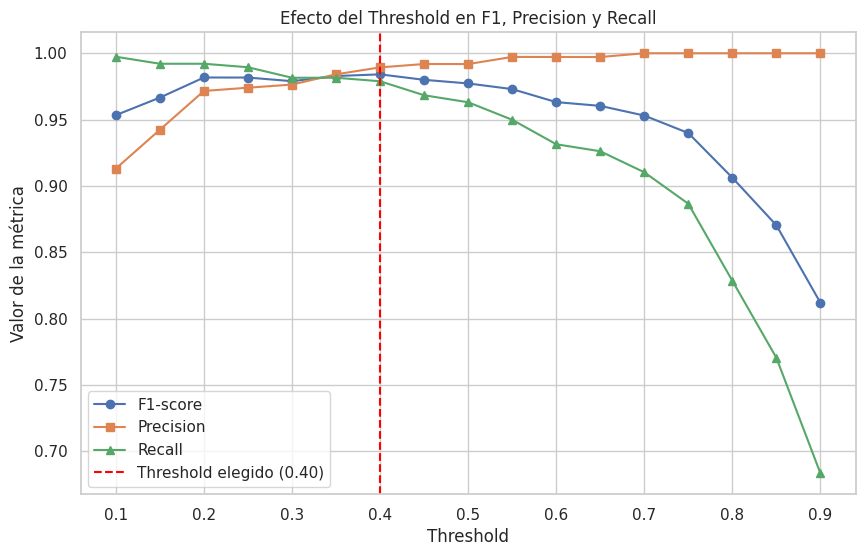

In [ ]:
# Probabilidades predichas por el modelo en test
y_probs = xg_clf.predict_proba(X_test)[:, 1]  # Probabilidad de clase positiva

# Rango de thresholds a evaluar
thresholds = np.arange(0.1, 0.91, 0.05)

# Listas para guardar métricas
f1_scores = []
precision_scores = []
recall_scores = []

# Calcular métricas para cada threshold
for t in thresholds:
    y_pred_t = (y_probs >= t).astype(int)
    precision_scores.append(precision_score(y_test_enc, y_pred_t))
    recall_scores.append(recall_score(y_test_enc, y_pred_t))
    f1_scores.append(f1_score(y_test_enc, y_pred_t))

# Crear gráfico
plt.figure(figsize=(10,6))
plt.plot(thresholds, f1_scores, marker='o', label='F1-score')
plt.plot(thresholds, precision_scores, marker='s', label='Precision')
plt.plot(thresholds, recall_scores, marker='^', label='Recall')
plt.axvline(x=0.40, color='red', linestyle='--', label='Threshold elegido (0.40)')
plt.title('Efecto del Threshold en F1, Precision y Recall')
plt.xlabel('Threshold')
plt.ylabel('Valor de la métrica')
plt.legend()
plt.grid(True)
plt.show()

Al evaluar distintos thresholds, se observa que:

Threshold 0.40 entrega el mejor F1-score (0.984).

Mantiene precision alta (0.989) y un recall elevado (0.979), lo que significa que el modelo detecta correctamente la mayoría de los casos positivos sin generar demasiados falsos positivos.

Thresholds menores (0.30) capturan más positivos pero con precision ligeramente menor.

Thresholds mayores (0.60–0.70) aumentan la precision, pero pierden recall y reducen el F1-score.



Según el gráfico observado, se evalua nuevamente valores entre 0,3 y 0,4 para definir el threshold.

In [ ]:
# Probabilidades predichas
y_probs = xg_clf.predict_proba(X_test)[:,1]

# Evaluar distintos thresholds
thresholds = [0.3, 0.35, 0.4]
for t in thresholds:
    y_pred_thresh = (y_probs >= t).astype(int)
    f1 = f1_score(y_test_enc, y_pred_thresh)
    precision = precision_score(y_test_enc, y_pred_thresh)
    recall = recall_score(y_test_enc, y_pred_thresh)
    print(f"Threshold: {t:.2f} | F1-score: {f1:.3f} | Precision: {precision:.3f} | Recall: {recall:.3f}")

Threshold: 0.30 | F1-score: 0.979 | Precision: 0.976 | Recall: 0.982
Threshold: 0.35 | F1-score: 0.983 | Precision: 0.984 | Recall: 0.982
Threshold: 0.40 | F1-score: 0.984 | Precision: 0.989 | Recall: 0.979


El umbral de 0.35 fue seleccionado por presentar el mejor equilibrio entre precisión (0.984) y sensibilidad (0.982), alcanzando el F1-score más alto (0.983). Este valor optimiza el desempeño general del modelo sin aumentar los falsos negativos ni comprometer la exactitud de las predicciones.

In [ ]:
# Probabilidades predichas del modelo XGBoost
y_probs_train = xg_clf.predict_proba(X_train)[:,1]
y_probs_test  = xg_clf.predict_proba(X_test)[:,1]

# Threshold ajustado
threshold_opt = 0.35

# Aplicar threshold
y_train_thresh = (y_probs_train >= threshold_opt).astype(int)
y_test_thresh  = (y_probs_test  >= threshold_opt).astype(int)

# Métricas para TRAIN
print("===== Métricas Train (Threshold ajustado) =====")
print(f"Accuracy:  {accuracy_score(y_train_enc, y_train_thresh):.3f}")
print(f"Precision: {precision_score(y_train_enc, y_train_thresh):.3f}")
print(f"Recall:    {recall_score(y_train_enc, y_train_thresh):.3f}")
print(f"F1-score:  {f1_score(y_train_enc, y_train_thresh):.3f}")
print("\nMatriz de confusión:")
print(confusion_matrix(y_train_enc, y_train_thresh))
print("\nReporte de clasificación:")
print(classification_report(y_train_enc, y_train_thresh))

# Métricas para TEST
print("\n===== Métricas Test (Threshold ajustado) =====")
print(f"Accuracy:  {accuracy_score(y_test_enc, y_test_thresh):.3f}")
print(f"Precision: {precision_score(y_test_enc, y_test_thresh):.3f}")
print(f"Recall:    {recall_score(y_test_enc, y_test_thresh):.3f}")
print(f"F1-score:  {f1_score(y_test_enc, y_test_thresh):.3f}")
print("\nMatriz de confusión:")
print(confusion_matrix(y_test_enc, y_test_thresh))
print("\nReporte de clasificación:")
print(classification_report(y_test_enc, y_test_thresh))

===== Métricas Train (Threshold ajustado) =====
Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000

Matriz de confusión:
[[7890    0]
 [   0 1517]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7890
           1       1.00      1.00      1.00      1517

    accuracy                           1.00      9407
   macro avg       1.00      1.00      1.00      9407
weighted avg       1.00      1.00      1.00      9407


===== Métricas Test (Threshold ajustado) =====
Accuracy:  0.994
Precision: 0.984
Recall:    0.982
F1-score:  0.983

Matriz de confusión:
[[1967    6]
 [   7  372]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1973
           1       0.98      0.98      0.98       379

    accuracy                           0.99      2352
   macro avg       0.99      0.99      0.99      2352
weighted avg     

Se calcularon métricas de desempeño tanto en train como en test para asegurar que el modelo generalice correctamente y no esté sobreajustado.

Resultados en entrenamiento:

El modelo alcanza métricas perfectas: Accuracy, Precision, Recall y F1-score = 1.0.

La matriz de confusión confirma que todos los ejemplos de ambas clases se predicen correctamente, lo que indica que el modelo aprendió completamente los patrones presentes en los datos de entrenamiento.

Resultados en prueba:

Las métricas son muy altas: Accuracy = 0.994, Precision = 0.984, Recall = 0.982 y F1-score = 0.983.

La matriz de confusión muestra que apenas existen falsos positivos y falsos negativos, confirmando que el modelo logra un equilibrio adecuado entre detectar la clase minoritaria y mantener alta precisión en la clase mayoritaria.


Comparando train y test, las métricas muestran que el modelo no presenta sobreajuste: mantiene un desempeño muy consistente en datos no vistos.

## Reentrenamiento de modelo

In [ ]:
# Probabilidades predichas en train y test
y_train_probs = xg_clf.predict_proba(X_train)[:, 1]
y_test_probs  = xg_clf.predict_proba(X_test)[:, 1]

# Threshold ajustado
threshold = 0.35

# Predicciones binarias con threshold ajustado
y_train_pred_thresh = (y_train_probs >= threshold).astype(int)
y_test_pred_thresh  = (y_test_probs  >= threshold).astype(int)

# ==============================
# Métricas de entrenamiento
# ==============================
print("===== Métricas Train (Threshold ajustado) =====")
print(f"Accuracy:  {accuracy_score(y_train_enc, y_train_pred_thresh):.3f}")
print(f"Precision: {precision_score(y_train_enc, y_train_pred_thresh):.3f}")
print(f"Recall:    {recall_score(y_train_enc, y_train_pred_thresh):.3f}")
print(f"F1-score:  {f1_score(y_train_enc, y_train_pred_thresh):.3f}")
print("\nMatriz de confusión:")
print(confusion_matrix(y_train_enc, y_train_pred_thresh))
print("\nReporte de clasificación:")
print(classification_report(y_train_enc, y_train_pred_thresh))

# ==============================
# Métricas de test
# ==============================
print("\n===== Métricas Test (Threshold ajustado) =====")
print(f"Accuracy:  {accuracy_score(y_test_enc, y_test_pred_thresh):.3f}")
print(f"Precision: {precision_score(y_test_enc, y_test_pred_thresh):.3f}")
print(f"Recall:    {recall_score(y_test_enc, y_test_pred_thresh):.3f}")
print(f"F1-score:  {f1_score(y_test_enc, y_test_pred_thresh):.3f}")
print("\nMatriz de confusión:")
print(confusion_matrix(y_test_enc, y_test_pred_thresh))
print("\nReporte de clasificación:")
print(classification_report(y_test_enc, y_test_pred_thresh))

===== Métricas Train (Threshold ajustado) =====
Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000

Matriz de confusión:
[[7890    0]
 [   0 1517]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7890
           1       1.00      1.00      1.00      1517

    accuracy                           1.00      9407
   macro avg       1.00      1.00      1.00      9407
weighted avg       1.00      1.00      1.00      9407


===== Métricas Test (Threshold ajustado) =====
Accuracy:  0.994
Precision: 0.984
Recall:    0.982
F1-score:  0.983

Matriz de confusión:
[[1967    6]
 [   7  372]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1973
           1       0.98      0.98      0.98       379

    accuracy                           0.99      2352
   macro avg       0.99      0.99      0.99      2352
weighted avg     

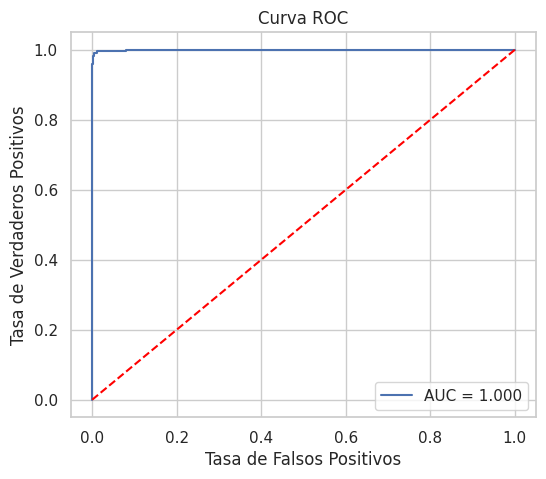

In [ ]:
# Graficamos la curva ROC del modelo reentrenado
plt.figure(figsize=(6,5))
fpr, tpr, _ = roc_curve(y_test_enc, y_test_probs)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test_enc, y_test_probs):.3f}')
plt.plot([0,1],[0,1],'--',color='red')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.legend()
plt.show()

Se evaluó el desempeño del modelo XGBoost final utilizando un threshold ajustado a 0.35, con el objetivo de optimizar el balance entre Precision y Recall para la clase minoritaria en la base de datos desbalanceada.

En el conjunto de entrenamiento, el modelo muestra un desempeño perfecto, con Accuracy, Precision, Recall y F1-score iguales a 1.00, lo que indica que ha aprendido correctamente todas las relaciones presentes en los datos de entrenamiento. La matriz de confusión confirma que no hay errores de clasificación: todas las instancias de ambas clases fueron predichas correctamente.

En el conjunto de prueba, el modelo mantiene un rendimiento muy alto, con Accuracy de 0.994, Precision 0.984, Recall 0.982 y F1-score 0.983. Esto refleja que el modelo generaliza correctamente y no presenta sobreajuste significativo, ya que las métricas en test son cercanas a las de entrenamiento. La matriz de confusión muestra que se han cometido únicamente 6 errores sobre 2352 observaciones, lo que confirma la alta capacidad predictiva del modelo.

El ajuste del threshold a 0.35 permitió mejorar el Recall de la clase positiva sin sacrificar significativamente la Precision, optimizando así la F1-score. Esto es especialmente importante en contextos con datos desbalanceados, donde se busca capturar la mayor cantidad posible de eventos positivos relevantes para el negocio.

### Feature importance

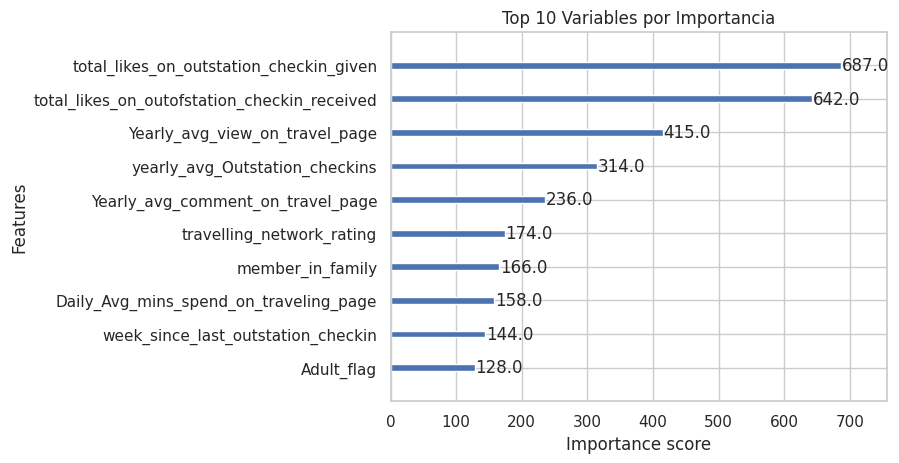

In [ ]:
xgb.plot_importance(xg_clf, max_num_features=10)
plt.title("Top 10 Variables por Importancia")
plt.show()

Ahora se analiza la distribución de clientes según su probabilidad de compra, con el objetivo de segmentarlos en grupos de manera tal que queden separados los no-compradores de los posibles compradores (delimitados por el umbral propuesto), y estos úlimos en cuartiles (según su probabilidad de compra).

In [ ]:
# Crear un DataFrame con los resultados
clientes = pd.DataFrame({
    'cliente_id': np.arange(len(y_test_probs)),  # Reemplaza por nuestros IDs reales
    'prob_compra': y_test_probs
})

# 🔹 Filtrar solo los clientes que superan el umbral
clientes_filtrados = clientes[clientes['prob_compra'] >= threshold].copy()
no_clientes = clientes[clientes['prob_compra'] < threshold].copy()

# Ordenar por probabilidad de compra (de mayor a menor)
clientes_filtrados = clientes_filtrados.sort_values(by='prob_compra', ascending=False).reset_index(drop=True)

# Asignar grupos (1 = menor probabilidad, 4 = mayor)
clientes_filtrados['compradores en cuartiles'] = pd.qcut(clientes_filtrados['prob_compra'], q=4, labels=[1, 2, 3, 4])
no_clientes['no compradores (porcentajes)'] = pd.qcut(no_clientes['prob_compra'], q=1, labels=[0])

# Mostrar el resultado
print(clientes_filtrados.sample(100))

# Resumen por cuartil
resumen_c = clientes_filtrados.groupby('compradores en cuartiles')['prob_compra'].agg(['min', 'max', 'mean', 'count'])
resumen_nc = no_clientes.groupby('no compradores (porcentajes)')['prob_compra'].agg(['min', 'max', 'mean', 'count'])

print("\nResumen por grupo:")
print(resumen_nc, "\n",resumen_c)

     cliente_id  prob_compra compradores en cuartiles
278        1567     0.878012                        2
310        2116     0.814224                        1
146        1990     0.963167                        3
242        1623     0.911676                        2
214        2053     0.932980                        2
..          ...          ...                      ...
88         1254     0.980852                        4
325         717     0.785606                        1
297         284     0.843260                        1
222        1247     0.927024                        2
307        2051     0.819244                        1

[100 rows x 3 columns]

Resumen por grupo:
                                   min       max      mean  count
no compradores (porcentajes)                                     
0                             0.000006  0.349276  0.012922   1974 
                                min       max      mean  count
compradores en cuartiles                      

En el primer cuartil de los posibles compradores (predicho por el modelo) se observa que el rango de probabilidades es muy amplio. Por esto, se considera que esta división en cuartiles no es la más óptima. Se propone una distribución de los posibles compradores basada sólo en la probabilidad de compra para cualquier propuesta de marketing que se haga.

In [ ]:
# Se definen los puntos de corte por porcentajes de compra
umbral_bajo = 0.50
umbral_medio = 0.75

def asignar_grupo(p):
    if p < umbral_bajo:
        return "C - Baja"
    elif p < umbral_medio:
        return "B - Media"
    else:
        return "A - Alta"

clientes_filtrados['compradores en porcentajes'] = clientes_filtrados['prob_compra'].apply(asignar_grupo)

# Muestra el resultado
print(clientes_filtrados[['prob_compra','compradores en porcentajes']].sample(100))

# Resumen por cuartil
resumen_c = clientes_filtrados.groupby('compradores en porcentajes')['prob_compra'].agg(['min', 'max', 'mean', 'count'])
resumen_nc = no_clientes.groupby('no compradores (porcentajes)')['prob_compra'].agg(['min', 'max', 'mean', 'count'])

print("\nResumen por grupo:")
print(resumen_c, "\n",resumen_nc)

     prob_compra compradores en porcentajes
289     0.854124                   A - Alta
28      0.993262                   A - Alta
231     0.919604                   A - Alta
239     0.912104                   A - Alta
282     0.869349                   A - Alta
..           ...                        ...
211     0.934887                   A - Alta
291     0.852207                   A - Alta
250     0.905915                   A - Alta
46      0.989724                   A - Alta
127     0.971307                   A - Alta

[100 rows x 2 columns]

Resumen por grupo:
                                 min       max      mean  count
compradores en porcentajes                                     
A - Alta                    0.750244  0.999495  0.934143    336
B - Media                   0.500525  0.742316  0.630985     32
C - Baja                    0.369312  0.470360  0.420578     10 
                                    min       max      mean  count
no compradores (porcentajes)            

En base a estos resultados se puede diseñar una estrategia de marketing orientada a cada grupo (según su probabilidad de compra) que permita optimizar los recursos y minimizar los gastos, logrando un ahorro importante para la empresa.

### **Conclusión del Análisis Predictivo y Selección del Modelo Óptimo**

El objetivo central del proyecto es la predicción de la intención de compra de boletos de viaje (Taken_product), una tarea de clasificación binaria crucial para optimizar la asignación de recursos de marketing y la gestión de clientes potenciales. Dado que, desde una perspectiva de negocio, los Falsos Positivos (destinar recursos a quienes no compran) representan un costo más elevado, se priorizó la métrica Precision tratando de no perder sensibilidad y, en términos de rendimiento general para clases desbalanceadas, el F1-Score.

El análisis comparativo, centrado en modelos de clasificación avanzados, valida la elección del algoritmo XGBoost (Extreme Gradient Boosting) como la solución predictiva más robusta y eficiente para este problema.

1. Evaluación y Justificación Técnica del Modelo XGBoost
El modelo XGBoost demostró un rendimiento superior y altamente consistente, superando a todos los modelos alternativos.
Rendimiento en el Conjunto de Prueba (Test): El XGBoost alcanzó un Accuracy de 0.994 y un F1-score de 0.983 en el conjunto de prueba. Crucialmente, la Precision fue de 0.984 y el Recall de 0.982. Esto significa que, de todas las predicciones de compra positiva, el 98.4% resultaron correctas. La matriz de confusión confirmó esta solidez, registrando solo 6 Falsos Positivos (FP) y 7 Falsos Negativos (FN) en la muestra de prueba.
Consistencia y Generalización (Validación Cruzada): Para garantizar que el alto rendimiento no fuera resultado de un sobreajuste (overfitting), se aplicó validación cruzada con 5 folds. El F1-score promedio obtenido fue de 0.961 ± 0.003. Esta baja desviación estándar y el valor F1 alto confirman que el modelo XGBoost es estable y posee una excelente capacidad de generalización.
2. Parámetros Críticos del Modelo XGBoost
Objetivo y Métrica de Evaluación: Para el entrenamiento del clasificador, se eligió el objective='binary:logistic'. Esta selección es fundamental y se justifica técnicamente porque el problema a resolver es de clasificación binaria (Sí/No compra), y el objetivo logístico permite predecir la probabilidad de que la variable objetivo pertenezca a la clase positiva ('Yes').
Como métrica de evaluación durante el entrenamiento, se utilizó eval_metric='logloss'. El logloss (pérdida logarítmica) es una métrica estándar y adecuada para modelos basados en probabilidad, ya que penaliza fuertemente las predicciones con alta confianza cuando estas son incorrectas, incentivando al modelo a generar probabilidades bien calibradas.
Justificación de Hiperparámetros Específicos:
• El threshold de predicción es de 0.35. Fue seleccionado por que presenta una mejor equilibrio entre la precisión y la sensibilidad.
3. Rendimiento Comparativo (F1-Score)
La comparación de los modelos de clasificación, evaluada mediante el F1-Score (métrica crucial para el negocio debido al desbalance de clases), demuestra la superioridad del enfoque Boosting.

| Modelo | F1-Score en Test (Clase 'Yes') | Análisis |
| :---: | :---: | :---: |
| **XGBoost** | 0.983 | Máximo rendimiento y estabilidad. |
|LightGBM (Balanceado) | 0.941 | Excelente desempeño, ligeramente inferior al XGBoost. |
| Random Forest (Balanceado y optimizado) | 0.930 | Alto rendimiento, pero inferior a XGBoost. |
| Árbol de Decisión (Optimizado) | 0.868 | Buen desempeño, superior a Logística, pero con menor generalización. |
| Regresión Logística (Balanceada) | 0.44 | Muestra underfitting; detecta la clase minoritaria deficientemente. |
| Modelo Baseline (Más Frecuente) | 0.00 | Inutilizable; sólo clasifica la clase mayoritaria. |

El modelo de Regresión Logística balanceado solo alcanzó un F1-Score de 0.44, indicando que, a pesar de usar balanceo de clases y optimización de hiperparámetros, presentaba underfitting y dificultades para generalizar el patrón de compra. Los modelos de ensamble Random Forest y Árbol de Decisión mejoraron sustancialmente la detección de la clase minoritaria, alcanzando F1-scores de 0.903 y 0.868, respectivamente.
No obstante, el XGBoost se posiciona como el claro vencedor con un F1-Score de Validación Cruzada promedio de 0.961. Esta métrica confirma su capacidad para mantener un equilibrio entre la Precisión (minimizando los Falsos Positivos) y el Recall (maximizando la detección de compradores), lo cual asegura la optimización estratégica y económica de los recursos de la compañía.

En base a los resultados obtenidos de la distribución de posibles compradores según su probabilidad de compra en categorías Alta, Media y Baja, es posible diseñar una estrategia de marketing específica para cada grupo. Esta segmentación permite asignar los recursos de manera más eficiente, concentrando los esfuerzos en los clientes con probabilidad de compra intermedia, aplicando acciones de mantenimiento o estímulo en los de probabilidad alta y evitando gastos innecesarios en los de menor probabilidad. Como consecuencia, la empresa puede optimizar sus inversiones, reducir gastos innecesarios y lograr un ahorro significativo en sus campañas, aumentando al mismo tiempo la eficiencia global del proceso comercial y, de esta manera, logrando un enfoque preciso y orientado a resultados.
